# EDA 04 — Análise temporal e clustering

Coorte resolvida por `resolve_cohort_path` (`coorte_final.parquet`).
Descrição temporal usa todas as fichas; tabelas com desfecho usam só
o bloco `train_ref`. Desfecho e identificadores não formam clusters.


In [4]:
from pathlib import Path
import gc
import json
import sys
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import os
import psutil

PROCESSO_ATUAL = psutil.Process(os.getpid())

def memoria_processo_gb():
    """Retorna a memória residente do kernel atual em GB."""

    return (
        PROCESSO_ATUAL.memory_info().rss
        / (1024 ** 3)
    )

print(
    "Memória inicial do kernel:",
    f"{memoria_processo_gb():.2f} GB",
)

def encontrar_raiz_projeto() -> Path:
    pasta_atual = Path.cwd().resolve()

    for pasta in [pasta_atual, *pasta_atual.parents]:
        possui_src = (pasta / "src").is_dir()
        possui_configs = (pasta / "configs").is_dir()

        if possui_src and possui_configs:
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


ROOT_DIR = encontrar_raiz_projeto()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.dados import resolve_cohort_path
from src import config as C

TIPO_COORTE, CAMINHO_COORTE = resolve_cohort_path(
    root=ROOT_DIR,
    kind="final",
    explicit_path=None,
)

CAMINHO_COORTE = Path(CAMINHO_COORTE)
NOME_COORTE = str(TIPO_COORTE)

if not CAMINHO_COORTE.is_file():
    raise FileNotFoundError(
        "A fonte de coorte resolvida não existe: "
        f"{CAMINHO_COORTE}"
    )

print(
    "Tipo de coorte:",
    NOME_COORTE,
)
print(
    "Arquivo da coorte:",
    CAMINHO_COORTE,
)


COLUNAS_ESTRUTURA = [
    "id_registro",
    "nu_notific",
    "dt_interna_convertida",
    "ano_internacao",
    "evolucao_normalizada",
    "alvo_obito_srag",
]

COLUNAS_DEMOGRAFIA = [
    "cs_sexo",
    "sexo_categoria",
    "nu_idade_n",
    "tp_idade",
    "idade_anos",
    "faixa_etaria",
    "cs_gestant",
    "cs_raca",
    "cs_zona",
]

COLUNAS_SINTOMAS_PLANEJADAS = [
    "febre",
    "tosse",
    "garganta",
    "dispneia",
    "desc_resp",
    "saturacao",
    "diarreia",
    "vomito",
    "dor_abd",
    "fadiga",
    "perd_olft",
    "perd_pala",
    "outro_sin",
]

COLUNAS_COMORBIDADES_PLANEJADAS = [
    "puerpera",
    "cardiopati",
    "hematologi",
    "sind_down",
    "hepatica",
    "asma",
    "diabetes",
    "neurologic",
    "pneumopati",
    "imunodepre",
    "renal",
    "obesidade",
    "out_morbi",
]

COLUNAS_CONTEXTO = [
    "cs_escol_n",
    "sg_uf",
    "vacina",
    "vacina_cov",
    "ave_suino",
]

COLUNAS_INTERVALOS = [
    "dt_sin_pri",
    "dt_interna",
    "dt_sin_pri_convertida",
    "dias_sintomas_ate_internacao",
    "flag_intervalo_invalido",
]

COLUNAS_CONTADORES_EXISTENTES = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

COLUNAS_CLUSTERING = [
    "sin_semana",
    "cos_semana",
]


COLUNAS_SOLICITADAS = list(
    dict.fromkeys(
        COLUNAS_ESTRUTURA
        + COLUNAS_DEMOGRAFIA
        + COLUNAS_SINTOMAS_PLANEJADAS
        + COLUNAS_COMORBIDADES_PLANEJADAS
        + COLUNAS_CONTEXTO
        + COLUNAS_INTERVALOS
        + COLUNAS_CONTADORES_EXISTENTES
        + COLUNAS_CLUSTERING
    )
)


arquivo_parquet = pq.ParquetFile(
    CAMINHO_COORTE
)

COLUNAS_DISPONIVEIS_COORTE = set(
    arquivo_parquet.schema_arrow.names
)

COLUNAS_EXISTENTES = [
    coluna
    for coluna in COLUNAS_SOLICITADAS
    if coluna in COLUNAS_DISPONIVEIS_COORTE
]

COLUNAS_AUSENTES = [
    coluna
    for coluna in COLUNAS_SOLICITADAS
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]


COLUNAS_OBRIGATORIAS_COORTE = [
    "id_registro",
    "nu_notific",
    "dt_interna",
    "alvo_obito_srag",
]

colunas_obrigatorias_ausentes = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_COORTE
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]

if colunas_obrigatorias_ausentes:
    raise KeyError(
        "A coorte não contém as colunas obrigatórias: "
        f"{colunas_obrigatorias_ausentes}"
    )


print(
    "Colunas disponíveis no Parquet:",
    len(COLUNAS_DISPONIVEIS_COORTE),
)

print(
    "Colunas solicitadas pelo notebook:",
    len(COLUNAS_SOLICITADAS),
)

print(
    "Colunas que serão carregadas:",
    len(COLUNAS_EXISTENTES),
)

if COLUNAS_AUSENTES:
    print(
        "Colunas opcionais ausentes, que poderão ser derivadas:",
        COLUNAS_AUSENTES,
    )


t0_carregamento = time.perf_counter()

try:
    coorte = pd.read_parquet(
        CAMINHO_COORTE,
        columns=COLUNAS_EXISTENTES,
        dtype_backend="pyarrow",
    )

    BACKEND_COORTE = "pyarrow"

except TypeError:
    coorte = pd.read_parquet(
        CAMINHO_COORTE,
        columns=COLUNAS_EXISTENTES,
    )

    BACKEND_COORTE = "numpy/object"


if coorte.empty:
    raise ValueError(
        "A coorte carregada está vazia."
    )


CAMINHO_PARTICAO_MESTRA = ROOT_DIR / "data" / "analytical" / "partitions_master.parquet"
CAMINHO_MANIFESTO_PARTICAO = ROOT_DIR / "data" / "analytical" / "manifesto_particao.json"

for caminho_necessario in (CAMINHO_PARTICAO_MESTRA, CAMINHO_MANIFESTO_PARTICAO):
    if not caminho_necessario.is_file():
        raise FileNotFoundError(
            "Arquivo da partição-mestra não encontrado: "
            f"{caminho_necessario}"
        )

particao_mestra = pd.read_parquet(
    CAMINHO_PARTICAO_MESTRA,
    columns=["id_registro", "particao"],
)

if not particao_mestra["id_registro"].is_unique:
    raise ValueError(
        "A partição-mestra tem id_registro repetido."
    )

particao_mestra["particao"] = particao_mestra["particao"].astype("category")

bloco_por_registro = particao_mestra.set_index("id_registro")["particao"]

coorte["particao"] = bloco_por_registro.reindex(
    coorte["id_registro"].to_numpy()
).array

del particao_mestra
del bloco_por_registro


with open(CAMINHO_MANIFESTO_PARTICAO, encoding="utf-8") as arquivo_manifesto:
    blocos_esperados = {
        nome_bloco: int(info_bloco["n_linhas"])
        for nome_bloco, info_bloco in json.load(arquivo_manifesto)["blocos"].items()
    }

blocos_observados = (
    coorte["particao"]
    .value_counts(dropna=True)
    .astype("int64")
    .to_dict()
)

if blocos_observados != blocos_esperados:
    raise ValueError(
        "As contagens por bloco divergem do manifesto da partição. "
        f"Observado: {blocos_observados}. Esperado: {blocos_esperados}."
    )

print(
    "Fichas sem bloco na partição-mestra:",
    int(coorte["particao"].isna().sum()),
)
print(
    "Fichas em train_ref:",
    blocos_observados["train_ref"],
)


memoria_apos_leitura_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)


COLUNAS_CATEGORICAS_BAIXA_CARDINALIDADE = [
    coluna
    for coluna in (
        COLUNAS_DEMOGRAFIA
        + COLUNAS_SINTOMAS_PLANEJADAS
        + COLUNAS_COMORBIDADES_PLANEJADAS
        + COLUNAS_CONTEXTO
        + [
            "evolucao_normalizada",
            "faixa_etaria",
        ]
    )
    if coluna in coorte.columns
]


relatorio_compactacao = []


for coluna in COLUNAS_CATEGORICAS_BAIXA_CARDINALIDADE:
    memoria_antes = int(
        coorte[coluna]
        .memory_usage(
            index=False,
            deep=True,
        )
    )

    quantidade_categorias = int(
        coorte[coluna]
        .nunique(
            dropna=False
        )
    )

    if quantidade_categorias <= 500:
        coorte[coluna] = (
            coorte[coluna]
            .astype("category")
        )

    memoria_depois = int(
        coorte[coluna]
        .memory_usage(
            index=False,
            deep=True,
        )
    )

    relatorio_compactacao.append(
        {
            "coluna": coluna,
            "categorias": quantidade_categorias,
            "dtype_final": str(
                coorte[coluna].dtype
            ),
            "memoria_antes_mb": (
                memoria_antes
                / 1_048_576
            ),
            "memoria_depois_mb": (
                memoria_depois
                / 1_048_576
            ),
        }
    )


if "ano_internacao" in coorte.columns:
    coorte["ano_internacao"] = (
        pd.to_numeric(
            coorte["ano_internacao"],
            errors="coerce",
        )
        .astype("Int16")
    )


if "alvo_obito_srag" in coorte.columns:
    coorte["alvo_obito_srag"] = (
        pd.to_numeric(
            coorte["alvo_obito_srag"],
            errors="coerce",
        )
        .astype("Int8")
    )


if "idade_anos" in coorte.columns:
    coorte["idade_anos"] = (
        pd.to_numeric(
            coorte["idade_anos"],
            errors="coerce",
        )
        .astype("Float32")
    )


if "dias_sintomas_ate_internacao" in coorte.columns:
    coorte["dias_sintomas_ate_internacao"] = (
        pd.to_numeric(
            coorte["dias_sintomas_ate_internacao"],
            errors="coerce",
        )
        .astype("Float32")
    )


for coluna in [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]:
    if coluna in coorte.columns:
        coorte[coluna] = (
            pd.to_numeric(
                coorte[coluna],
                errors="coerce",
            )
            .astype("Int16")
        )


for coluna in [
    "flag_intervalo_invalido",
    "flag_multimorbidade",
]:
    if coluna in coorte.columns:
        coorte[coluna] = (
            pd.to_numeric(
                coorte[coluna],
                errors="coerce",
            )
            .fillna(0)
            .astype("int8")
        )


memoria_final_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

tempo_carregamento_s = (
    time.perf_counter()
    - t0_carregamento
)

gc.collect()


print(
    "Coorte utilizada:",
    NOME_COORTE,
)

print(
    "Caminho:",
    CAMINHO_COORTE,
)

print(
    "Backend:",
    BACKEND_COORTE,
)

print(
    "Dimensão carregada:",
    coorte.shape,
)

print(
    "Memória após leitura:",
    f"{memoria_apos_leitura_mb:,.2f} MB",
)

print(
    "Memória após compactação:",
    f"{memoria_final_mb:,.2f} MB",
)

if memoria_apos_leitura_mb > 0:
    reducao_memoria_pct = (
        1
        - memoria_final_mb
        / memoria_apos_leitura_mb
    ) * 100
else:
    reducao_memoria_pct = 0.0

print(
    "Redução após compactação:",
    f"{reducao_memoria_pct:,.2f}%",
)

print(
    "Tempo de leitura e compactação:",
    f"{tempo_carregamento_s:,.2f} s",
)


relatorio_compactacao_df = (
    pd.DataFrame(
        relatorio_compactacao
    )
    .sort_values(
        [
            "memoria_antes_mb",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


display(
    relatorio_compactacao_df.head(20)
)

Memória inicial do kernel: 0.12 GB
Tipo de coorte: final
Arquivo da coorte: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\analytical\coorte_final.parquet
Colunas disponíveis no Parquet: 199
Colunas solicitadas pelo notebook: 58
Colunas que serão carregadas: 42
Colunas opcionais ausentes, que poderão ser derivadas: ['dt_interna_convertida', 'ano_internacao', 'evolucao_normalizada', 'sexo_categoria', 'idade_anos', 'faixa_etaria', 'dt_sin_pri_convertida', 'dias_sintomas_ate_internacao', 'flag_intervalo_invalido', 'n_sintomas_confirmados', 'n_sintomas_avaliados', 'n_comorbidades_confirmadas', 'n_comorbidades_avaliadas', 'flag_multimorbidade', 'sin_semana', 'cos_semana']
Fichas sem bloco na partição-mestra: 4
Fichas em train_ref: 556462
Coorte utilizada: final
Caminho: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\analytical\coorte_final.parquet
Backend: pyarrow
Dimensão carregada: (3884728, 43)
Memória após leitura: 864.79 MB
Memória após compact

,coluna,categorias,dtype_final,memoria_antes_mb,memoria_depois_mb
0,sg_uf,28,category,22.689557,3.704924
1,nu_idade_n,135,category,21.475392,7.410336
2,cs_zona,5,category,18.662969,3.704785
3,tosse,4,category,18.626857,3.704781
4,cs_raca,7,category,18.616165,3.704795
5,dispneia,4,category,18.591432,3.704781
6,cs_gestant,8,category,18.523827,3.704804
7,cs_sexo,3,category,18.523827,3.704781
8,tp_idade,3,category,18.523827,3.704781
9,febre,4,category,18.491655,3.704781


In [5]:
if "dt_interna_convertida" not in coorte.columns:
    coorte["dt_interna_convertida"] = pd.to_datetime(
        coorte["dt_interna"].astype("string"),
        errors="coerce",
    )

if "dt_sin_pri_convertida" not in coorte.columns and "dt_sin_pri" in coorte.columns:
    coorte["dt_sin_pri_convertida"] = pd.to_datetime(
        coorte["dt_sin_pri"].astype("string"),
        errors="coerce",
    )

if "ano_internacao" not in coorte.columns:
    coorte["ano_internacao"] = (
        coorte["dt_interna_convertida"].dt.year.astype("Int16")
    )

if "evolucao_normalizada" not in coorte.columns:
    coorte["evolucao_normalizada"] = (
        pd.to_numeric(coorte["alvo_obito_srag"], errors="coerce")
        .map({1: "obito_srag", 0: "cura"})
        .astype("category")
    )

print(
    "Datas de internação não convertidas:",
    int(coorte["dt_interna_convertida"].isna().sum()),
)
print(
    "Anos presentes:",
    sorted(coorte["ano_internacao"].dropna().unique().tolist()),
)

Datas de internação não convertidas: 0
Anos presentes: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [6]:
COLUNAS_ENTRADA_FEATURES = [
    "nu_idade_n",
    "tp_idade",
    "cs_sexo",
    "dt_sin_pri",
    "dt_interna",
]

colunas_entrada_ausentes_parquet = [
    coluna
    for coluna in COLUNAS_ENTRADA_FEATURES
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]

colunas_entrada_fora_da_leitura = [
    coluna
    for coluna in COLUNAS_ENTRADA_FEATURES
    if coluna not in COLUNAS_EXISTENTES
]

print(
    "Entradas ausentes no Parquet:",
    colunas_entrada_ausentes_parquet,
)
print(
    "Entradas disponíveis, mas fora da leitura:",
    colunas_entrada_fora_da_leitura,
)

if colunas_entrada_ausentes_parquet:
    raise KeyError(
        "O Parquet não contém todas as entradas exigidas pela "
        "engenharia centralizada: "
        f"{colunas_entrada_ausentes_parquet}"
    )

if colunas_entrada_fora_da_leitura:
    raise RuntimeError(
        "Há entradas da engenharia disponíveis no Parquet, "
        "mas excluídas da leitura projetada: "
        f"{colunas_entrada_fora_da_leitura}"
    )

Entradas ausentes no Parquet: []
Entradas disponíveis, mas fora da leitura: []


In [7]:
COLUNAS_OBRIGATORIAS_COORTE = [
    "nu_notific",
    "dt_interna_convertida",
    "ano_internacao",
    "evolucao_normalizada",
    "alvo_obito_srag",
]

colunas_obrigatorias_ausentes = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_COORTE
    if coluna not in coorte.columns
]

if colunas_obrigatorias_ausentes:
    raise KeyError(
        "A coorte não contém as colunas obrigatórias: "
        f"{colunas_obrigatorias_ausentes}"
    )

dt_interna_sem_ausencia = (
    not coorte[
        "dt_interna_convertida"
    ]
    .isna()
    .any()
)

alvo_binario = (
    coorte[
        "alvo_obito_srag"
    ]
    .isin(
        [
            0,
            1,
        ]
    )
    .all()
)

periodo_valido = (
    coorte[
        "ano_internacao"
    ]
    .between(
        2019,
        2026,
    )
    .all()
)

verificacao_contrato = pd.DataFrame(
    {
        "verificacao": [
            "coorte_nao_vazia",
            "colunas_obrigatorias_presentes",
            "dt_interna_sem_ausencia",
            "alvo_binario",
            "ano_internacao_entre_2019_e_2026",
        ],
        "resultado": [
            not coorte.empty,
            not colunas_obrigatorias_ausentes,
            dt_interna_sem_ausencia,
            alvo_binario,
            periodo_valido,
        ],
    }
)

display(
    verificacao_contrato
)

if not verificacao_contrato[
    "resultado"
].all():
    falhas = (
        verificacao_contrato.loc[
            ~verificacao_contrato[
                "resultado"
            ],
            "verificacao",
        ]
        .tolist()
    )

    raise RuntimeError(
        "O contrato mínimo da coorte falhou em: "
        f"{falhas}"
    )

print(
    "Contrato mínimo da coorte validado."
)

,verificacao,resultado
0,coorte_nao_vazia,True
1,colunas_obrigatorias_presentes,True
2,dt_interna_sem_ausencia,True
3,alvo_binario,True
4,ano_internacao_entre_2019_e_2026,True


Contrato mínimo da coorte validado.


In [8]:
CAMINHO_VOLUME_ANO = (
    C.TABLES_DIR
    / "04_eda_volume_por_ano.csv"
)

CAMINHO_ALVO_ANO = (
    C.TABLES_DIR
    / "04_eda_alvo_por_ano.csv"
)

CAMINHO_AUSENCIA_ANO = (
    C.TABLES_DIR
    / "04_eda_ausencia_por_ano.csv"
)

CAMINHO_RESUMO_FONTE = (
    C.TABLES_DIR
    / "04_eda_resumo_fonte.csv"
)

C.TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

C.FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

resumo_fonte = pd.DataFrame(
    {
        "metrica": [
            "nome_coorte",
            "caminho_coorte",
            "quantidade_linhas",
            "quantidade_colunas",
        ],
        "valor": [
            NOME_COORTE,
            str(
                CAMINHO_COORTE
            ),
            len(
                coorte
            ),
            coorte.shape[1],
        ],
    }
)

resumo_fonte.to_csv(
    CAMINHO_RESUMO_FONTE,
    index=False,
    encoding="utf-8-sig",
)

display(
    resumo_fonte
)

,metrica,valor
0,nome_coorte,final
1,caminho_coorte,C:\Users\ivanI\OneDrive\Documentos\Projetos\Pr...
2,quantidade_linhas,3884728
3,quantidade_colunas,47


In [9]:
import matplotlib.pyplot as plt

CAMINHO_FIGURA_VOLUME_ANO = (
    C.FIGURES_DIR
    / "04_eda_volume_por_ano.png"
)

CAMINHO_FIGURA_ALVO_ANO = (
    C.FIGURES_DIR
    / "04_eda_proporcao_obito_por_ano.png"
)

print(
    "Figura de volume:",
    CAMINHO_FIGURA_VOLUME_ANO,
)

print(
    "Figura do desfecho:",
    CAMINHO_FIGURA_ALVO_ANO,
)

Figura de volume: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_volume_por_ano.png
Figura do desfecho: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_proporcao_obito_por_ano.png


In [10]:
volume_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade_registros"
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

volume_por_ano[
    "percentual_coorte"
] = (
    volume_por_ano[
        "quantidade_registros"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

volume_por_ano[
    "ano_internacao"
] = (
    volume_por_ano[
        "ano_internacao"
    ]
    .astype("Int64")
)

volume_por_ano[
    "periodo_completo"
] = (
    volume_por_ano[
        "ano_internacao"
    ]
    .ne(2026)
)

total_volume_por_ano = int(
    volume_por_ano[
        "quantidade_registros"
    ]
    .sum()
)

if total_volume_por_ano != len(
    coorte
):
    raise RuntimeError(
        "A soma do volume por ano não corresponde "
        "ao total de registros da coorte."
    )

display(
    volume_por_ano
)

,ano_internacao,quantidade_registros,percentual_coorte,periodo_completo
0,2019,43392,1.116989,True
1,2020,974415,25.083223,True
2,2021,1471091,37.868571,True
3,2022,470323,12.106974,True
4,2023,237976,6.125937,True
5,2024,226749,5.836934,True
6,2025,286837,7.383709,True
7,2026,173945,4.477662,False


In [11]:
contagem_alvo_por_ano = (
    coorte.groupby(
        [
            "ano_internacao",
            "alvo_obito_srag",
        ],
        dropna=False,
    )
    .size()
    .unstack(
        fill_value=0
    )
)

contagem_alvo_por_ano = (
    contagem_alvo_por_ano.reindex(
        columns=[
            0,
            1,
        ],
        fill_value=0,
    )
)

contagem_alvo_por_ano = (
    contagem_alvo_por_ano.rename(
        columns={
            0: "quantidade_cura",
            1: "quantidade_obito_srag",
        }
    )
    .reset_index()
)

alvo_por_ano = (
    contagem_alvo_por_ano
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

alvo_por_ano[
    "quantidade_total"
] = (
    alvo_por_ano[
        "quantidade_cura"
    ]
    .add(
        alvo_por_ano[
            "quantidade_obito_srag"
        ]
    )
)

alvo_por_ano[
    "percentual_cura"
] = (
    alvo_por_ano[
        "quantidade_cura"
    ]
    .div(
        alvo_por_ano[
            "quantidade_total"
        ]
    )
    .mul(100)
)

alvo_por_ano[
    "percentual_obito_srag"
] = (
    alvo_por_ano[
        "quantidade_obito_srag"
    ]
    .div(
        alvo_por_ano[
            "quantidade_total"
        ]
    )
    .mul(100)
)

alvo_por_ano[
    "ano_internacao"
] = (
    alvo_por_ano[
        "ano_internacao"
    ]
    .astype("Int64")
)

total_alvo_por_ano = int(
    alvo_por_ano[
        "quantidade_total"
    ]
    .sum()
)

if total_alvo_por_ano != len(
    coorte
):
    raise RuntimeError(
        "A soma da distribuição do alvo por ano "
        "não corresponde ao total da coorte."
    )

display(
    alvo_por_ano
)

alvo_obito_srag,ano_internacao,quantidade_cura,quantidade_obito_srag,quantidade_total,percentual_cura,percentual_obito_srag
0,2019,38186,5206,43392,88.002397,11.997603
1,2020,702311,272104,974415,72.075143,27.924857
2,2021,1057151,413940,1471091,71.861700,28.138300
3,2022,385272,85051,470323,81.916470,18.083530
4,2023,215498,22478,237976,90.554510,9.445490
5,2024,208120,18629,226749,91.784308,8.215692
6,2025,266058,20779,286837,92.755816,7.244184
7,2026,164412,9533,173945,94.519532,5.480468


In [12]:
resumo_temporal = (
    volume_por_ano.merge(
        alvo_por_ano,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
)

resumo_temporal[
    "diferenca_total"
] = (
    resumo_temporal[
        "quantidade_registros"
    ]
    .sub(
        resumo_temporal[
            "quantidade_total"
        ]
    )
)

if not resumo_temporal[
    "diferenca_total"
].eq(0).all():
    raise RuntimeError(
        "Existe divergência entre o volume anual "
        "e a distribuição anual do alvo."
    )

COLUNAS_RESUMO_TEMPORAL = [
    "ano_internacao",
    "quantidade_registros",
    "percentual_coorte",
    "quantidade_cura",
    "quantidade_obito_srag",
    "percentual_cura",
    "percentual_obito_srag",
    "periodo_completo",
]

resumo_temporal = (
    resumo_temporal[
        COLUNAS_RESUMO_TEMPORAL
    ]
    .copy()
)

display(
    resumo_temporal
)

,ano_internacao,quantidade_registros,percentual_coorte,quantidade_cura,quantidade_obito_srag,percentual_cura,percentual_obito_srag,periodo_completo
0,2019,43392,1.116989,38186,5206,88.002397,11.997603,True
1,2020,974415,25.083223,702311,272104,72.075143,27.924857,True
2,2021,1471091,37.868571,1057151,413940,71.861700,28.138300,True
3,2022,470323,12.106974,385272,85051,81.916470,18.083530,True
4,2023,237976,6.125937,215498,22478,90.554510,9.445490,True
5,2024,226749,5.836934,208120,18629,91.784308,8.215692,True
6,2025,286837,7.383709,266058,20779,92.755816,7.244184,True
7,2026,173945,4.477662,164412,9533,94.519532,5.480468,False


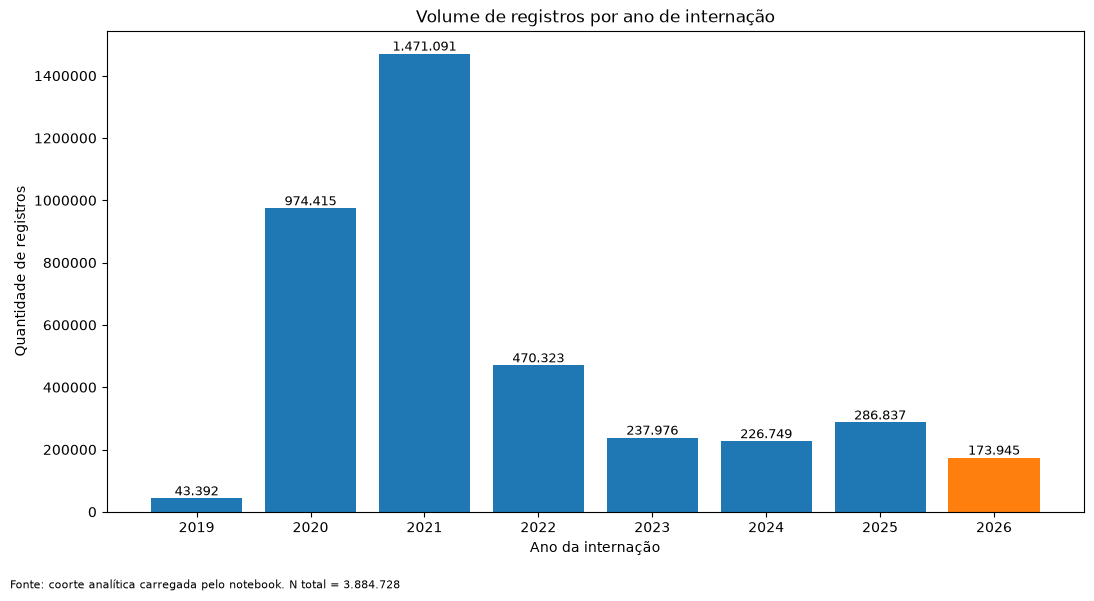

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_volume_por_ano.png


In [13]:
anos_volume = (
    resumo_temporal[
        "ano_internacao"
    ]
    .astype(int)
    .astype(str)
)

quantidades_volume = (
    resumo_temporal[
        "quantidade_registros"
    ]
)

cores_volume = [
    (
        "tab:orange"
        if ano == 2026
        else "tab:blue"
    )
    for ano in resumo_temporal[
        "ano_internacao"
    ]
]

figura_volume, eixo_volume = plt.subplots(
    figsize=(
        11,
        6,
    )
)

barras_volume = eixo_volume.bar(
    anos_volume,
    quantidades_volume,
    color=cores_volume,
)

eixo_volume.set_title(
    "Volume de registros por ano de internação"
)

eixo_volume.set_xlabel(
    "Ano da internação"
)

eixo_volume.set_ylabel(
    "Quantidade de registros"
)

eixo_volume.ticklabel_format(
    style="plain",
    axis="y",
)

for barra, quantidade in zip(
    barras_volume,
    quantidades_volume,
):
    rotulo_quantidade = (
        f"{int(quantidade):,}"
        .replace(
            ",",
            ".",
        )
    )

    eixo_volume.text(
        barra.get_x()
        + barra.get_width()
        / 2,
        barra.get_height(),
        rotulo_quantidade,
        ha="center",
        va="bottom",
        fontsize=9,
    )

figura_volume.text(
    0.01,
    0.01,
    (
        "Fonte: coorte analítica carregada pelo notebook. "
        f"N total = {len(coorte):,}"
        .replace(
            ",",
            ".",
        )
    ),
    fontsize=8,
)

figura_volume.tight_layout(
    rect=(
        0,
        0.04,
        1,
        1,
    )
)

figura_volume.savefig(
    CAMINHO_FIGURA_VOLUME_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VOLUME_ANO,
)

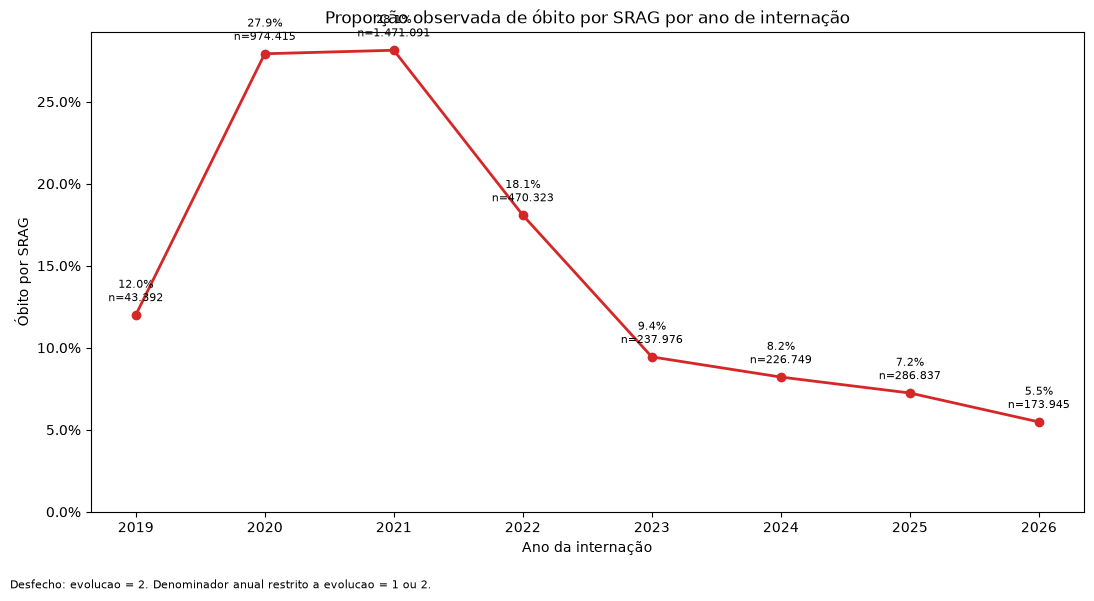

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_proporcao_obito_por_ano.png


In [14]:
anos_alvo = (
    alvo_por_ano[
        "ano_internacao"
    ]
    .astype(int)
)

percentuais_obito = (
    alvo_por_ano[
        "percentual_obito_srag"
    ]
)

denominadores_ano = (
    alvo_por_ano[
        "quantidade_total"
    ]
)

figura_alvo, eixo_alvo = plt.subplots(
    figsize=(
        11,
        6,
    )
)

eixo_alvo.plot(
    anos_alvo,
    percentuais_obito,
    color="tab:red",
    marker="o",
    linewidth=2,
)

eixo_alvo.set_title(
    "Proporção observada de óbito por SRAG por ano de internação"
)

eixo_alvo.set_xlabel(
    "Ano da internação"
)

eixo_alvo.set_ylabel(
    "Óbito por SRAG"
)

eixo_alvo.set_xticks(
    anos_alvo
)

eixo_alvo.set_ylim(
    bottom=0,
)

eixo_alvo.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.1f}%"
        )
    )
)

for ano, percentual, denominador in zip(
    anos_alvo,
    percentuais_obito,
    denominadores_ano,
):
    denominador_formatado = (
        f"{int(denominador):,}"
        .replace(
            ",",
            ".",
        )
    )

    rotulo_ponto = (
        f"{percentual:.1f}%\n"
        f"n={denominador_formatado}"
    )

    eixo_alvo.annotate(
        rotulo_ponto,
        (
            ano,
            percentual,
        ),
        textcoords="offset points",
        xytext=(
            0,
            10,
        ),
        ha="center",
        fontsize=8,
    )

figura_alvo.text(
    0.01,
    0.01,
    (
        "Desfecho: evolucao = 2. "
        "Denominador anual restrito a evolucao = 1 ou 2."
    ),
    fontsize=8,
)

figura_alvo.tight_layout(
    rect=(
        0.0,
        0.04,
        1.0,
        1.0,
    )
)

figura_alvo.savefig(
    CAMINHO_FIGURA_ALVO_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_ALVO_ANO,
)

In [15]:
volume_por_ano.to_csv(
    CAMINHO_VOLUME_ANO,
    index=False,
    encoding="utf-8-sig",
)

alvo_por_ano.to_csv(
    CAMINHO_ALVO_ANO,
    index=False,
    encoding="utf-8-sig",
)

CAMINHO_RESUMO_TEMPORAL = (
    C.TABLES_DIR
    / "04_eda_resumo_temporal.csv"
)

resumo_temporal.to_csv(
    CAMINHO_RESUMO_TEMPORAL,
    index=False,
    encoding="utf-8-sig",
)

print(
    "Volume por ano salvo em:",
    CAMINHO_VOLUME_ANO,
)

print(
    "Distribuição do alvo salva em:",
    CAMINHO_ALVO_ANO,
)

print(
    "Resumo temporal salvo em:",
    CAMINHO_RESUMO_TEMPORAL,
)

Volume por ano salvo em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_volume_por_ano.csv
Distribuição do alvo salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_alvo_por_ano.csv
Resumo temporal salvo em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_resumo_temporal.csv


In [16]:
CAMINHO_IDADE_ANO = (
    C.TABLES_DIR
    / "04_eda_idade_por_ano.csv"
)

CAMINHO_FAIXA_ETARIA_ANO = (
    C.TABLES_DIR
    / "04_eda_faixa_etaria_por_ano.csv"
)

CAMINHO_SEXO_ANO = (
    C.TABLES_DIR
    / "04_eda_sexo_por_ano.csv"
)

CAMINHO_AUDITORIA_IDADE = (
    C.TABLES_DIR
    / "04_eda_auditoria_idade.csv"
)

CAMINHO_FIGURA_IDADE_ANO = (
    C.FIGURES_DIR
    / "04_eda_idade_por_ano.png"
)

CAMINHO_FIGURA_FAIXA_ETARIA = (
    C.FIGURES_DIR
    / "04_eda_faixa_etaria_por_ano.png"
)

print(
    "Tabela de idade:",
    CAMINHO_IDADE_ANO,
)

print(
    "Tabela de faixa etária:",
    CAMINHO_FAIXA_ETARIA_ANO,
)

print(
    "Tabela de sexo:",
    CAMINHO_SEXO_ANO,
)

Tabela de idade: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_idade_por_ano.csv
Tabela de faixa etária: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_faixa_etaria_por_ano.csv
Tabela de sexo: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_sexo_por_ano.csv


In [17]:
from src.features import montar_features

COLUNAS_ORIGEM_DEMOGRAFIA = [
    "nu_idade_n",
    "tp_idade",
    "cs_sexo",
]

colunas_origem_ausentes = [
    coluna
    for coluna in COLUNAS_ORIGEM_DEMOGRAFIA
    if coluna not in coorte.columns
]

if colunas_origem_ausentes:
    raise KeyError(
        "A coorte não contém as colunas de origem necessárias: "
        f"{colunas_origem_ausentes}"
    )

quantidade_linhas_antes = len(coorte)
indice_antes = coorte.index.copy()

coorte = montar_features(coorte)

COLUNAS_DEMOGRAFICAS_CENTRALIZADAS = [
    "idade_anos",
    "faixa_etaria",
    "sexo_categoria",
]

colunas_demograficas_ausentes = [
    coluna
    for coluna in COLUNAS_DEMOGRAFICAS_CENTRALIZADAS
    if coluna not in coorte.columns
]

if colunas_demograficas_ausentes:
    raise KeyError(
        "A engenharia centralizada não produziu as colunas esperadas: "
        f"{colunas_demograficas_ausentes}"
    )

if len(coorte) != quantidade_linhas_antes:
    raise RuntimeError(
        "A engenharia de atributos alterou a quantidade de registros: "
        f"{quantidade_linhas_antes} -> {len(coorte)}"
    )

if not coorte.index.equals(indice_antes):
    raise RuntimeError(
        "A engenharia de atributos alterou o índice ou a ordem dos registros."
    )

idade_valor = pd.to_numeric(
    coorte["nu_idade_n"],
    errors="coerce",
)

tipo_idade = (
    coorte["tp_idade"]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "NaN": pd.NA,
            "None": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

coorte["flag_idade_ausente"] = (
    idade_valor.isna()
    | tipo_idade.isna()
).astype("int8")

coorte["flag_tipo_idade_invalido"] = (
    tipo_idade.notna()
    & ~tipo_idade.isin(["1", "2", "3"])
).astype("int8")

coorte["flag_idade_nao_convertida"] = (
    idade_valor.notna()
    & tipo_idade.notna()
    & coorte["idade_anos"].isna()
).astype("int8")

print(
    "Idades padronizadas válidas:",
    int(coorte["idade_anos"].notna().sum()),
)
print(
    "Idades ausentes:",
    int(coorte["flag_idade_ausente"].sum()),
)
print(
    "Idades não convertidas ou implausíveis:",
    int(coorte["flag_idade_nao_convertida"].sum()),
)
print(
    "Tipos de idade inválidos:",
    int(coorte["flag_tipo_idade_invalido"].sum()),
)
print(
    "Categorias de faixa etária:",
    coorte["faixa_etaria"].cat.categories.tolist(),
)
print(
    "Categorias de sexo:",
    coorte["sexo_categoria"].cat.categories.tolist(),
)

Idades padronizadas válidas: 3884704
Idades ausentes: 0
Idades não convertidas ou implausíveis: 24
Tipos de idade inválidos: 0
Categorias de faixa etária: ['1-4', '12-17', '18-39', '40-59', '5-11', '60-79', '80+', '<1', 'desconhecida']
Categorias de sexo: ['feminino', 'ignorado', 'masculino']


In [18]:
auditoria_idade = (
    pd.DataFrame(
        {
            "tipo_idade": tipo_idade,
            "idade_valor_original": idade_valor,
            "idade_anos": coorte[
                "idade_anos"
            ],
            "flag_idade_ausente": coorte[
                "flag_idade_ausente"
            ],
            "flag_idade_nao_convertida": coorte[
                "flag_idade_nao_convertida"
            ],
            "flag_tipo_idade_invalido": coorte[
                "flag_tipo_idade_invalido"
            ],
        }
    )
    .groupby(
        "tipo_idade",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "idade_valor_original",
            "size",
        ),
        quantidade_valor_informado=(
            "idade_valor_original",
            "count",
        ),
        quantidade_idade_convertida=(
            "idade_anos",
            "count",
        ),
        quantidade_idade_ausente=(
            "flag_idade_ausente",
            "sum",
        ),
        quantidade_nao_convertida=(
            "flag_idade_nao_convertida",
            "sum",
        ),
        quantidade_tipo_invalido=(
            "flag_tipo_idade_invalido",
            "sum",
        ),
    )
    .reset_index()
)

auditoria_idade[
    "percentual_convertido"
] = (
    auditoria_idade[
        "quantidade_idade_convertida"
    ]
    .div(
        auditoria_idade[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

display(
    auditoria_idade
)

,tipo_idade,quantidade_registros,quantidade_valor_informado,quantidade_idade_convertida,quantidade_idade_ausente,quantidade_nao_convertida,quantidade_tipo_invalido,percentual_convertido
0,1,26271,26271,26270,0,1,0,99.996194
1,2,352745,352745,352730,0,15,0,99.995748
2,3,3505712,3505712,3505704,0,8,0,99.999772


In [19]:
idade_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "ano_internacao",
            "size",
        ),
        quantidade_idade_valida=(
            "idade_anos",
            "count",
        ),
        idade_media=(
            "idade_anos",
            "mean",
        ),
        idade_mediana=(
            "idade_anos",
            "median",
        ),
        idade_minima=(
            "idade_anos",
            "min",
        ),
        idade_maxima=(
            "idade_anos",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

quantil_25_idade = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        "idade_anos"
    ]
    .quantile(0.25)
    .rename(
        "idade_q1"
    )
    .reset_index()
)

quantil_75_idade = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        "idade_anos"
    ]
    .quantile(0.75)
    .rename(
        "idade_q3"
    )
    .reset_index()
)

idade_por_ano = (
    idade_por_ano.merge(
        quantil_25_idade,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
    .merge(
        quantil_75_idade,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
)

idade_por_ano[
    "idade_iqr"
] = (
    idade_por_ano[
        "idade_q3"
    ]
    .sub(
        idade_por_ano[
            "idade_q1"
        ]
    )
)

idade_por_ano[
    "quantidade_idade_ausente"
] = (
    idade_por_ano[
        "quantidade_registros"
    ]
    .sub(
        idade_por_ano[
            "quantidade_idade_valida"
        ]
    )
)

idade_por_ano[
    "percentual_idade_ausente"
] = (
    idade_por_ano[
        "quantidade_idade_ausente"
    ]
    .div(
        idade_por_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

COLUNAS_IDADE_ANO = [
    "ano_internacao",
    "quantidade_registros",
    "quantidade_idade_valida",
    "quantidade_idade_ausente",
    "percentual_idade_ausente",
    "idade_media",
    "idade_mediana",
    "idade_q1",
    "idade_q3",
    "idade_iqr",
    "idade_minima",
    "idade_maxima",
]

idade_por_ano = (
    idade_por_ano[
        COLUNAS_IDADE_ANO
    ]
    .copy()
)

display(
    idade_por_ano
)

,ano_internacao,quantidade_registros,quantidade_idade_valida,quantidade_idade_ausente,percentual_idade_ausente,idade_media,idade_mediana,idade_q1,idade_q3,idade_iqr,idade_minima,idade_maxima
0,2019,43392,43392,0,0.0,24.570303,5.0,0.666667,50.0,49.333333,0.0,108.0
1,2020,974415,974411,4,0.000411,56.894779,60.0,43.000000,74.0,31.000000,0.0,120.0
2,2021,1471091,1471083,8,0.000544,53.559093,56.0,41.000000,70.0,29.000000,0.0,119.0
3,2022,470323,470319,4,0.00085,47.340607,58.0,5.000000,77.0,72.000000,0.0,118.0
4,2023,237976,237973,3,0.001261,29.865681,7.0,0.916667,66.0,65.083333,0.0,117.0
5,2024,226749,226745,4,0.001764,28.117401,6.0,0.833333,63.0,62.166667,0.0,114.0
6,2025,286837,286836,1,0.000349,27.306364,5.0,0.750000,62.0,61.250000,0.0,114.0
7,2026,173945,173945,0,0.0,23.570118,3.0,0.750000,53.0,52.250000,0.0,115.0


In [20]:
COLUNAS_DEMOGRAFICAS_CENTRALIZADAS = [
    "idade_anos",
    "faixa_etaria",
    "sexo_categoria",
]

colunas_demograficas_ausentes = [
    coluna
    for coluna in COLUNAS_DEMOGRAFICAS_CENTRALIZADAS
    if coluna not in coorte.columns
]

if colunas_demograficas_ausentes:
    raise KeyError(
        "A coorte não contém todas as variáveis demográficas "
        "centralizadas necessárias para esta análise: "
        f"{colunas_demograficas_ausentes}"
    )

if not isinstance(coorte["faixa_etaria"].dtype, pd.CategoricalDtype):
    raise TypeError(
        "faixa_etaria não preservou o tipo categórico centralizado."
    )

if not isinstance(coorte["sexo_categoria"].dtype, pd.CategoricalDtype):
    raise TypeError(
        "sexo_categoria não preservou o tipo categórico centralizado."
    )

ROTULOS_FAIXA_ETARIA = (
    coorte["faixa_etaria"]
    .cat.categories
    .astype("string")
    .tolist()
)

ROTULOS_SEXO = (
    coorte["sexo_categoria"]
    .cat.categories
    .astype("string")
    .tolist()
)

ROTULO_FAIXA_AUSENTE = "idade ausente ou inválida"
ROTULO_SEXO_AUSENTE = "sexo ausente ou inesperado"

faixa_etaria_eda = (
    coorte["faixa_etaria"]
    .astype("string")
    .fillna(ROTULO_FAIXA_AUSENTE)
)

sexo_categoria_eda = (
    coorte["sexo_categoria"]
    .astype("string")
    .fillna(ROTULO_SEXO_AUSENTE)
)

ORDEM_FAIXA_ETARIA = (
    ROTULOS_FAIXA_ETARIA
    + [ROTULO_FAIXA_AUSENTE]
)

ORDEM_SEXO = (
    ROTULOS_SEXO
    + [ROTULO_SEXO_AUSENTE]
)

faixa_etaria_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte["ano_internacao"],
            "faixa_etaria": faixa_etaria_eda,
        }
    )
    .groupby(
        ["ano_internacao", "faixa_etaria"],
        dropna=False,
    )
    .size()
    .rename("quantidade")
    .reset_index()
)

faixa_etaria_por_ano["percentual_ano"] = (
    faixa_etaria_por_ano["quantidade"]
    .div(
        faixa_etaria_por_ano.groupby(
            "ano_internacao"
        )["quantidade"].transform("sum")
    )
    .mul(100)
)

ordem_faixa = {
    categoria: posicao
    for posicao, categoria in enumerate(ORDEM_FAIXA_ETARIA)
}

faixa_etaria_por_ano["ordem_faixa"] = (
    faixa_etaria_por_ano["faixa_etaria"]
    .map(ordem_faixa)
    .fillna(len(ordem_faixa))
)

faixa_etaria_por_ano = (
    faixa_etaria_por_ano
    .sort_values(["ano_internacao", "ordem_faixa"])
    .drop(columns=["ordem_faixa"])
    .reset_index(drop=True)
)

sexo_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte["ano_internacao"],
            "sexo_categoria": sexo_categoria_eda,
        }
    )
    .groupby(
        ["ano_internacao", "sexo_categoria"],
        dropna=False,
    )
    .size()
    .rename("quantidade")
    .reset_index()
)

sexo_por_ano["percentual_ano"] = (
    sexo_por_ano["quantidade"]
    .div(
        sexo_por_ano.groupby(
            "ano_internacao"
        )["quantidade"].transform("sum")
    )
    .mul(100)
)

ordem_sexo = {
    categoria: posicao
    for posicao, categoria in enumerate(ORDEM_SEXO)
}

sexo_por_ano["ordem_sexo"] = (
    sexo_por_ano["sexo_categoria"]
    .map(ordem_sexo)
    .fillna(len(ordem_sexo))
)

sexo_por_ano = (
    sexo_por_ano
    .sort_values(["ano_internacao", "ordem_sexo"])
    .drop(columns=["ordem_sexo"])
    .reset_index(drop=True)
)

auditoria_categorias_demograficas = pd.DataFrame(
    {
        "variavel": ["faixa_etaria", "sexo_categoria"],
        "quantidade_registros": [len(coorte), len(coorte)],
        "quantidade_categorias": [
            coorte["faixa_etaria"].nunique(dropna=True),
            coorte["sexo_categoria"].nunique(dropna=True),
        ],
        "quantidade_ausente_ou_invalida": [
            int(coorte["faixa_etaria"].isna().sum()),
            int(coorte["sexo_categoria"].isna().sum()),
        ],
    }
)

display(auditoria_categorias_demograficas)
display(faixa_etaria_por_ano.head(30))
display(sexo_por_ano)

,variavel,quantidade_registros,quantidade_categorias,quantidade_ausente_ou_invalida
0,faixa_etaria,3884728,9,0
1,sexo_categoria,3884728,3,0


,ano_internacao,faixa_etaria,quantidade,percentual_ano
0,2019,1-4,8187,18.867533
1,2019,12-17,931,2.145557
2,2019,18-39,5047,11.631176
3,2019,40-59,5303,12.221147
4,2019,5-11,2752,6.342183
5,2019,60-79,5591,12.884864
6,2019,80+,2476,5.706121
7,2019,<1,13105,30.201420
8,2020,1-4,24369,2.500885
9,2020,12-17,9204,0.944567


,ano_internacao,sexo_categoria,quantidade,percentual_ano
0,2019,feminino,21110,48.649521
1,2019,ignorado,12,0.027655
2,2019,masculino,22270,51.322824
3,2020,feminino,444414,45.608288
4,2020,ignorado,216,0.022167
5,2020,masculino,529785,54.369545
6,2021,feminino,666186,45.285166
7,2021,ignorado,175,0.011896
8,2021,masculino,804730,54.702938
9,2022,feminino,232830,49.504277


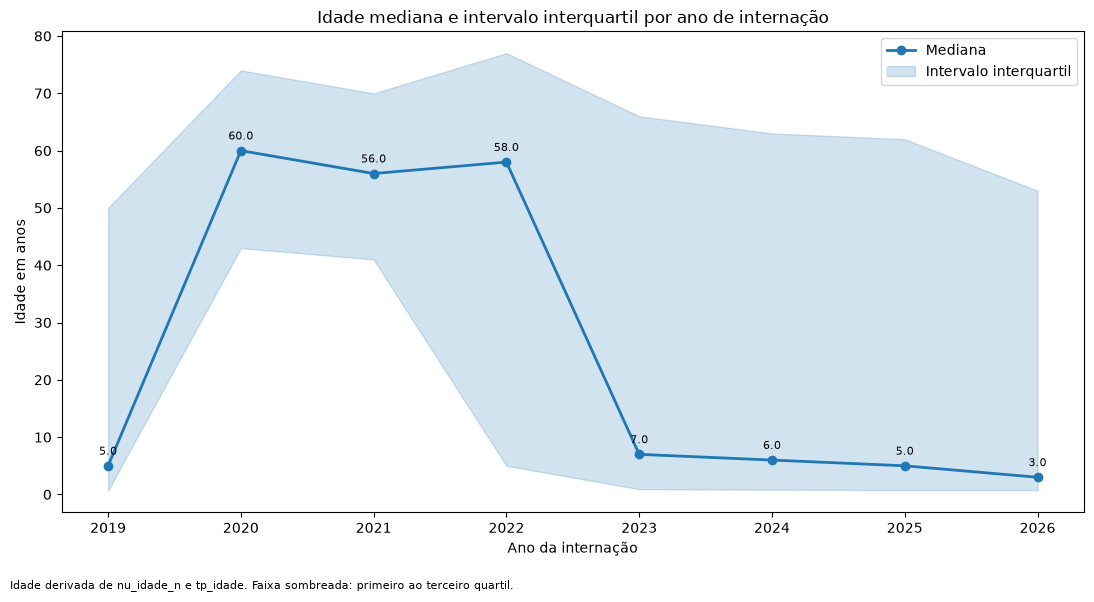

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_idade_por_ano.png


In [21]:
anos_idade = (
    idade_por_ano[
        "ano_internacao"
    ]
    .astype(int)
    .to_numpy()
)

idade_mediana_grafico = (
    idade_por_ano[
        "idade_mediana"
    ]
    .astype(float)
    .to_numpy()
)

idade_q1_grafico = (
    idade_por_ano[
        "idade_q1"
    ]
    .astype(float)
    .to_numpy()
)

idade_q3_grafico = (
    idade_por_ano[
        "idade_q3"
    ]
    .astype(float)
    .to_numpy()
)

figura_idade, eixo_idade = plt.subplots(
    figsize=(
        11,
        6,
    )
)

eixo_idade.plot(
    anos_idade,
    idade_mediana_grafico,
    color="tab:blue",
    marker="o",
    linewidth=2,
    label="Mediana",
)

eixo_idade.fill_between(
    anos_idade,
    idade_q1_grafico,
    idade_q3_grafico,
    color="tab:blue",
    alpha=0.2,
    label="Intervalo interquartil",
)

eixo_idade.set_title(
    "Idade mediana e intervalo interquartil por ano de internação"
)

eixo_idade.set_xlabel(
    "Ano da internação"
)

eixo_idade.set_ylabel(
    "Idade em anos"
)

eixo_idade.set_xticks(
    anos_idade
)

eixo_idade.legend()

for ano, mediana in zip(
    anos_idade,
    idade_mediana_grafico,
):
    eixo_idade.annotate(
        f"{mediana:.1f}",
        (
            ano,
            mediana,
        ),
        textcoords="offset points",
        xytext=(
            0,
            8,
        ),
        ha="center",
        fontsize=8,
    )

figura_idade.text(
    0.01,
    0.01,
    (
        "Idade derivada de nu_idade_n e tp_idade. "
        "Faixa sombreada: primeiro ao terceiro quartil."
    ),
    fontsize=8,
)

figura_idade.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_idade.savefig(
    CAMINHO_FIGURA_IDADE_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_IDADE_ANO,
)

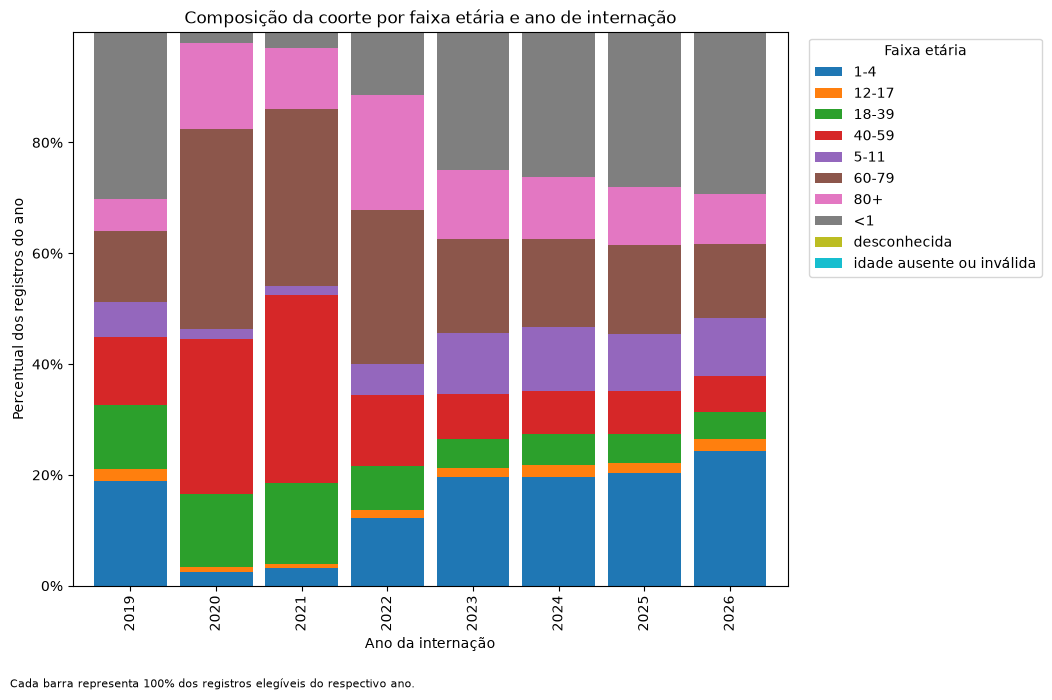

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_faixa_etaria_por_ano.png


In [22]:
if "ORDEM_FAIXA_ETARIA" not in globals():
    raise NameError(
        "A ordem centralizada das faixas etárias não foi criada. "
        "Execute novamente a célula demográfica desde o início."
    )

faixa_etaria_grafico = (
    faixa_etaria_por_ano.pivot(
        index="ano_internacao",
        columns="faixa_etaria",
        values="percentual_ano",
    )
    .reindex(
        columns=ORDEM_FAIXA_ETARIA,
        fill_value=0,
    )
    .fillna(0)
)

figura_faixa, eixo_faixa = plt.subplots(
    figsize=(
        13,
        7,
    )
)

faixa_etaria_grafico.plot(
    kind="bar",
    stacked=True,
    ax=eixo_faixa,
    width=0.85,
)

eixo_faixa.set_title(
    "Composição da coorte por faixa etária e ano de internação"
)

eixo_faixa.set_xlabel(
    "Ano da internação"
)

eixo_faixa.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_faixa.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_faixa.legend(
    title="Faixa etária",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

figura_faixa.text(
    0.01,
    0.01,
    (
        "Cada barra representa 100% dos registros elegíveis "
        "do respectivo ano."
    ),
    fontsize=8,
)

figura_faixa.tight_layout(
    rect=[
        0,
        0.04,
        0.82,
        1,
    ]
)

figura_faixa.savefig(
    CAMINHO_FIGURA_FAIXA_ETARIA,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_FAIXA_ETARIA,
)

In [23]:
idade_por_ano.to_csv(
    CAMINHO_IDADE_ANO,
    index=False,
    encoding="utf-8-sig",
)

faixa_etaria_por_ano.to_csv(
    CAMINHO_FAIXA_ETARIA_ANO,
    index=False,
    encoding="utf-8-sig",
)

sexo_por_ano.to_csv(
    CAMINHO_SEXO_ANO,
    index=False,
    encoding="utf-8-sig",
)

auditoria_idade.to_csv(
    CAMINHO_AUDITORIA_IDADE,
    index=False,
    encoding="utf-8-sig",
)

total_faixa_etaria = int(
    faixa_etaria_por_ano[
        "quantidade"
    ]
    .sum()
)

total_sexo = int(
    sexo_por_ano[
        "quantidade"
    ]
    .sum()
)

LIMITE_MINIMO_IDADE = 0.0
LIMITE_MAXIMO_IDADE = 120.0

idades_validas = (
    coorte["idade_anos"]
    .dropna()
)

idade_valida_entre_limites = (
    idades_validas
    .between(
        LIMITE_MINIMO_IDADE,
        LIMITE_MAXIMO_IDADE,
        inclusive="both",
    )
    .all()
)

verificacoes_demograficas = {
    "idade_por_ano_nao_vazia": (
        not idade_por_ano.empty
    ),
    "faixa_etaria_nao_vazia": (
        not faixa_etaria_por_ano.empty
    ),
    "sexo_por_ano_nao_vazio": (
        not sexo_por_ano.empty
    ),
    "total_faixa_etaria_igual_coorte": (
        total_faixa_etaria
        == len(coorte)
    ),
    "total_sexo_igual_coorte": (
        total_sexo
        == len(coorte)
    ),
    "idade_valida_entre_zero_e_120": (
        bool(idade_valida_entre_limites)
    ),
    "arquivo_idade_criado": (
        CAMINHO_IDADE_ANO.exists()
    ),
    "arquivo_faixa_etaria_criado": (
        CAMINHO_FAIXA_ETARIA_ANO.exists()
    ),
    "arquivo_sexo_criado": (
        CAMINHO_SEXO_ANO.exists()
    ),
    "arquivo_auditoria_idade_criado": (
        CAMINHO_AUDITORIA_IDADE.exists()
    ),
    "figura_idade_criada": (
        CAMINHO_FIGURA_IDADE_ANO.exists()
    ),
    "figura_faixa_etaria_criada": (
        CAMINHO_FIGURA_FAIXA_ETARIA.exists()
    ),
}

verificacoes_demograficas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_demograficas.keys()
        ),
        "resultado": list(
            verificacoes_demograficas.values()
        ),
    }
)

display(
    verificacoes_demograficas_df
)

if not all(
    verificacoes_demograficas.values()
):
    falhas_demograficas = [
        verificacao
        for verificacao, resultado
        in verificacoes_demograficas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A seção demográfica terminou com falhas: "
        f"{falhas_demograficas}"
    )

print(
    "Análise demográfica validada com sucesso."
)

,verificacao,resultado
0,idade_por_ano_nao_vazia,True
1,faixa_etaria_nao_vazia,True
2,sexo_por_ano_nao_vazio,True
3,total_faixa_etaria_igual_coorte,True
4,total_sexo_igual_coorte,True
5,idade_valida_entre_zero_e_120,True
6,arquivo_idade_criado,True
7,arquivo_faixa_etaria_criado,True
8,arquivo_sexo_criado,True
9,arquivo_auditoria_idade_criado,True


Análise demográfica validada com sucesso.


In [24]:
CAMINHO_DICIONARIO_OPERACIONAL = (
    C.CONFIGS_DIR
    / "dicionario_variaveis_v1.csv"
)

if not CAMINHO_DICIONARIO_OPERACIONAL.exists():
    raise FileNotFoundError(
        "O dicionário operacional não foi encontrado em: "
        f"{CAMINHO_DICIONARIO_OPERACIONAL}"
    )

dicionario_operacional = pd.read_csv(
    CAMINHO_DICIONARIO_OPERACIONAL,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False,
)

COLUNAS_DICIONARIO_NECESSARIAS = [
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
]

colunas_dicionario_ausentes = [
    coluna
    for coluna in COLUNAS_DICIONARIO_NECESSARIAS
    if coluna not in dicionario_operacional.columns
]

if colunas_dicionario_ausentes:
    raise KeyError(
        "O dicionário operacional não contém as colunas: "
        f"{colunas_dicionario_ausentes}"
    )

dicionario_operacional[
    "coluna"
] = (
    dicionario_operacional[
        "coluna"
    ]
    .astype("string")
    .str.strip()
)

dicionario_operacional = (
    dicionario_operacional.loc[
        dicionario_operacional[
            "coluna"
        ].ne("")
    ]
    .drop_duplicates(
        subset=[
            "coluna",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

colunas_dicionario_na_coorte = [
    coluna
    for coluna in dicionario_operacional[
        "coluna"
    ].tolist()
    if coluna in coorte.columns
]

colunas_dicionario_fora_coorte = [
    coluna
    for coluna in dicionario_operacional[
        "coluna"
    ].tolist()
    if coluna not in coorte.columns
]

if not colunas_dicionario_na_coorte:
    raise ValueError(
        "Nenhuma variável do dicionário foi encontrada na coorte."
    )

print(
    "Variáveis do dicionário encontradas na coorte:",
    len(
        colunas_dicionario_na_coorte
    ),
)

print(
    "Variáveis do dicionário ausentes na coorte:",
    len(
        colunas_dicionario_fora_coorte
    ),
)

if colunas_dicionario_fora_coorte:
    display(
        pd.DataFrame(
            {
                "coluna_ausente_na_coorte": (
                    colunas_dicionario_fora_coorte
                ),
            }
        )
    )

Variáveis do dicionário encontradas na coorte: 40
Variáveis do dicionário ausentes na coorte: 48


,coluna_ausente_na_coorte
0,dt_notific
1,sem_pri
2,hospital
3,cs_etinia
4,out_anim
5,tabag
6,outro_des
7,obes_imc
8,morb_desc
9,out_antiv


In [25]:
CAMINHO_PREENCHIMENTO_ANO = (
    C.TABLES_DIR
    / "04_eda_preenchimento_por_variavel_ano.csv"
)

CAMINHO_RESUMO_PREENCHIMENTO = (
    C.TABLES_DIR
    / "04_eda_resumo_preenchimento_variaveis.csv"
)

CAMINHO_VARIACAO_PREENCHIMENTO = (
    C.TABLES_DIR
    / "04_eda_variacao_preenchimento.csv"
)

CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO = (
    C.FIGURES_DIR
    / "04_eda_variacao_preenchimento.png"
)

print(
    "Tabela anual de preenchimento:",
    CAMINHO_PREENCHIMENTO_ANO,
)

print(
    "Resumo de preenchimento:",
    CAMINHO_RESUMO_PREENCHIMENTO,
)

print(
    "Figura de variação:",
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
)

Tabela anual de preenchimento: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_preenchimento_por_variavel_ano.csv
Resumo de preenchimento: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_resumo_preenchimento_variaveis.csv
Figura de variação: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_variacao_preenchimento.png


In [26]:
quantidade_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade_registros_ano"
    )
    .sort_index()
)

preenchidos_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        colunas_dicionario_na_coorte
    ]
    .count()
    .sort_index()
)

preenchidos_por_ano.index = (
    preenchidos_por_ano.index.astype(
        "Int64"
    )
)

quantidade_por_ano.index = (
    quantidade_por_ano.index.astype(
        "Int64"
    )
)

preenchimento_percentual_por_ano = (
    preenchidos_por_ano
    .div(
        quantidade_por_ano,
        axis=0,
    )
    .mul(100)
)

quantidade_preenchida_longa = (
    preenchidos_por_ano
    .reset_index()
    .melt(
        id_vars=[
            "ano_internacao",
        ],
        var_name="coluna",
        value_name="quantidade_preenchida",
    )
)

percentual_preenchido_longo = (
    preenchimento_percentual_por_ano
    .reset_index()
    .melt(
        id_vars=[
            "ano_internacao",
        ],
        var_name="coluna",
        value_name="percentual_preenchido",
    )
)

preenchimento_por_variavel_ano = (
    quantidade_preenchida_longa.merge(
        percentual_preenchido_longo,
        on=[
            "ano_internacao",
            "coluna",
        ],
        how="inner",
        validate="one_to_one",
    )
)

quantidade_por_ano_df = (
    quantidade_por_ano
    .reset_index()
)

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano.merge(
        quantidade_por_ano_df,
        on="ano_internacao",
        how="left",
        validate="many_to_one",
    )
)

preenchimento_por_variavel_ano[
    "quantidade_ausente"
] = (
    preenchimento_por_variavel_ano[
        "quantidade_registros_ano"
    ]
    .sub(
        preenchimento_por_variavel_ano[
            "quantidade_preenchida"
        ]
    )
)

preenchimento_por_variavel_ano[
    "percentual_ausente"
] = (
    100
    - preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
)

metadados_variaveis = (
    dicionario_operacional[
        COLUNAS_DICIONARIO_NECESSARIAS
    ]
    .copy()
)

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano.merge(
        metadados_variaveis,
        on="coluna",
        how="left",
        validate="many_to_one",
    )
)

COLUNAS_PREENCHIMENTO_ANUAL = [
    "ano_internacao",
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
    "quantidade_registros_ano",
    "quantidade_preenchida",
    "quantidade_ausente",
    "percentual_preenchido",
    "percentual_ausente",
]

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano[
        COLUNAS_PREENCHIMENTO_ANUAL
    ]
    .sort_values(
        [
            "grupo",
            "coluna",
            "ano_internacao",
        ]
    )
    .reset_index(drop=True)
)

display(
    preenchimento_por_variavel_ano.head(30)
)

,ano_internacao,coluna,nome_amigavel,grupo,uso_inicial_sugerido,quantidade_registros_ano,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,2019,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,43392,16823,26569,38.769819,61.230181
1,2020,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,974415,427968,546447,43.920506,56.079494
2,2021,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,1471091,533375,937716,36.257104,63.742896
3,2022,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,470323,174237,296086,37.046243,62.953757
4,2023,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,237976,74072,163904,31.125828,68.874172
5,2024,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,226749,70734,156015,31.194845,68.805155
6,2025,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,286837,93145,193692,32.473147,67.526853
7,2026,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,173945,53572,120373,30.798241,69.201759
8,2019,cardiopati,Doenca cardiovascular cronica,comorbidades_fatores_risco,modelo_a_nucleo,43392,16972,26420,39.113201,60.886799
9,2020,cardiopati,Doenca cardiovascular cronica,comorbidades_fatores_risco,modelo_a_nucleo,974415,527716,446699,54.157212,45.842788


In [27]:
quantidade_total_coorte = len(
    coorte
)

quantidade_preenchida_global = (
    coorte[
        colunas_dicionario_na_coorte
    ]
    .count()
    .rename(
        "quantidade_preenchida"
    )
)

resumo_preenchimento_variaveis = (
    quantidade_preenchida_global
    .reset_index()
    .rename(
        columns={
            "index": "coluna",
        }
    )
)

resumo_preenchimento_variaveis[
    "quantidade_registros"
] = quantidade_total_coorte

resumo_preenchimento_variaveis[
    "quantidade_ausente"
] = (
    resumo_preenchimento_variaveis[
        "quantidade_registros"
    ]
    .sub(
        resumo_preenchimento_variaveis[
            "quantidade_preenchida"
        ]
    )
)

resumo_preenchimento_variaveis[
    "percentual_preenchido"
] = (
    resumo_preenchimento_variaveis[
        "quantidade_preenchida"
    ]
    .div(
        resumo_preenchimento_variaveis[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

resumo_preenchimento_variaveis[
    "percentual_ausente"
] = (
    100
    - resumo_preenchimento_variaveis[
        "percentual_preenchido"
    ]
)

resumo_preenchimento_variaveis = (
    resumo_preenchimento_variaveis.merge(
        metadados_variaveis,
        on="coluna",
        how="left",
        validate="one_to_one",
    )
)

COLUNAS_RESUMO_PREENCHIMENTO = [
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
    "quantidade_registros",
    "quantidade_preenchida",
    "quantidade_ausente",
    "percentual_preenchido",
    "percentual_ausente",
]

resumo_preenchimento_variaveis = (
    resumo_preenchimento_variaveis[
        COLUNAS_RESUMO_PREENCHIMENTO
    ]
    .sort_values(
        [
            "percentual_preenchido",
            "grupo",
            "coluna",
        ],
        ascending=[
            True,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    resumo_preenchimento_variaveis.head(30)
)

,coluna,nome_amigavel,grupo,uso_inicial_sugerido,quantidade_registros,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,puerpera,Puerpera ou parturiente,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1397706,2487022,35.979507,64.020493
1,hepatica,Doenca hepatica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1399538,2485190,36.026666,63.973334
2,sind_down,Sindrome de Down,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1400612,2484116,36.054313,63.945687
3,hematologi,Doenca hematologica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1404906,2479822,36.164849,63.835151
4,imunodepre,Imunodeficiencia ou imunodepressao,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1421767,2462961,36.598882,63.401118
5,renal,Doenca renal cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1426204,2458524,36.713098,63.286902
6,neurologic,Doenca neurologica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1443221,2441507,37.151147,62.848853
7,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1443926,2440802,37.169295,62.830705
8,pneumopati,Outra pneumopatia cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1444275,2440453,37.178279,62.821721
9,obesidade,Obesidade,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1449319,2435409,37.308120,62.691880


In [28]:
variacao_preenchimento = (
    preenchimento_por_variavel_ano.groupby(
        [
            "coluna",
            "nome_amigavel",
            "grupo",
            "uso_inicial_sugerido",
        ],
        dropna=False,
    )
    .agg(
        preenchimento_minimo=(
            "percentual_preenchido",
            "min",
        ),
        preenchimento_maximo=(
            "percentual_preenchido",
            "max",
        ),
        preenchimento_medio=(
            "percentual_preenchido",
            "mean",
        ),
        quantidade_anos_observados=(
            "ano_internacao",
            "nunique",
        ),
    )
    .reset_index()
)

variacao_preenchimento[
    "amplitude_pontos_percentuais"
] = (
    variacao_preenchimento[
        "preenchimento_maximo"
    ]
    .sub(
        variacao_preenchimento[
            "preenchimento_minimo"
        ]
    )
)

variacao_preenchimento[
    "flag_variacao_20_pp"
] = (
    variacao_preenchimento[
        "amplitude_pontos_percentuais"
    ]
    .ge(20)
)

variacao_preenchimento = (
    variacao_preenchimento
    .sort_values(
        [
            "amplitude_pontos_percentuais",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    variacao_preenchimento.head(30)
)

,coluna,nome_amigavel,grupo,uso_inicial_sugerido,preenchimento_minimo,preenchimento_maximo,preenchimento_medio,quantidade_anos_observados,amplitude_pontos_percentuais,flag_variacao_20_pp
0,vacina_cov,Recebeu vacina contra COVID-19?,vacinacao_covid,modelo_a_nucleo,1.338956,99.993725,73.685134,8,98.654768,True
1,fadiga,Fadiga,sintomas,modelo_a_nucleo,0.523138,83.964472,63.423242,8,83.441334,True
2,dor_abd,Dor abdominal,sintomas,modelo_a_nucleo,0.274244,82.470321,61.557547,8,82.196077,True
3,perd_olft,Perda do olfato,sintomas,modelo_a_nucleo,0.269635,82.09549,61.261682,8,81.825855,True
4,perd_pala,Perda do paladar,sintomas,modelo_a_nucleo,0.26733,81.902325,61.179847,8,81.634995,True
5,vacina,Recebeu vacina contra influenza?,vacinacao_influenza,modelo_a_nucleo,56.119945,96.034379,78.088779,8,39.914434,True
6,cs_escol_n,Escolaridade,demografia_contexto_social,modelo_b_ampliado,62.544488,92.593105,69.350736,8,30.048617,True
7,diarreia,Diarreia,sintomas,modelo_a_nucleo,68.500158,97.607854,78.344364,8,29.107696,True
8,vomito,Vomito,sintomas,modelo_a_nucleo,69.104211,97.693123,78.517096,8,28.588912,True
9,garganta,Dor de garganta,sintomas,modelo_a_nucleo,70.390136,98.041114,78.838657,8,27.650977,True


,coluna,rotulo_variavel,grupo,uso_inicial_sugerido,preenchimento_minimo,preenchimento_maximo,amplitude_pontos_percentuais
0,vacina_cov,Recebeu vacina contra COVID-19?,vacinacao_covid,modelo_a_nucleo,1.338956,99.993725,98.654768
1,fadiga,Fadiga,sintomas,modelo_a_nucleo,0.523138,83.964472,83.441334
2,dor_abd,Dor abdominal,sintomas,modelo_a_nucleo,0.274244,82.470321,82.196077
3,perd_olft,Perda do olfato,sintomas,modelo_a_nucleo,0.269635,82.09549,81.825855
4,perd_pala,Perda do paladar,sintomas,modelo_a_nucleo,0.26733,81.902325,81.634995
5,vacina,Recebeu vacina contra influenza?,vacinacao_influenza,modelo_a_nucleo,56.119945,96.034379,39.914434
6,cs_escol_n,Escolaridade,demografia_contexto_social,modelo_b_ampliado,62.544488,92.593105,30.048617
7,diarreia,Diarreia,sintomas,modelo_a_nucleo,68.500158,97.607854,29.107696
8,vomito,Vomito,sintomas,modelo_a_nucleo,69.104211,97.693123,28.588912
9,garganta,Dor de garganta,sintomas,modelo_a_nucleo,70.390136,98.041114,27.650977


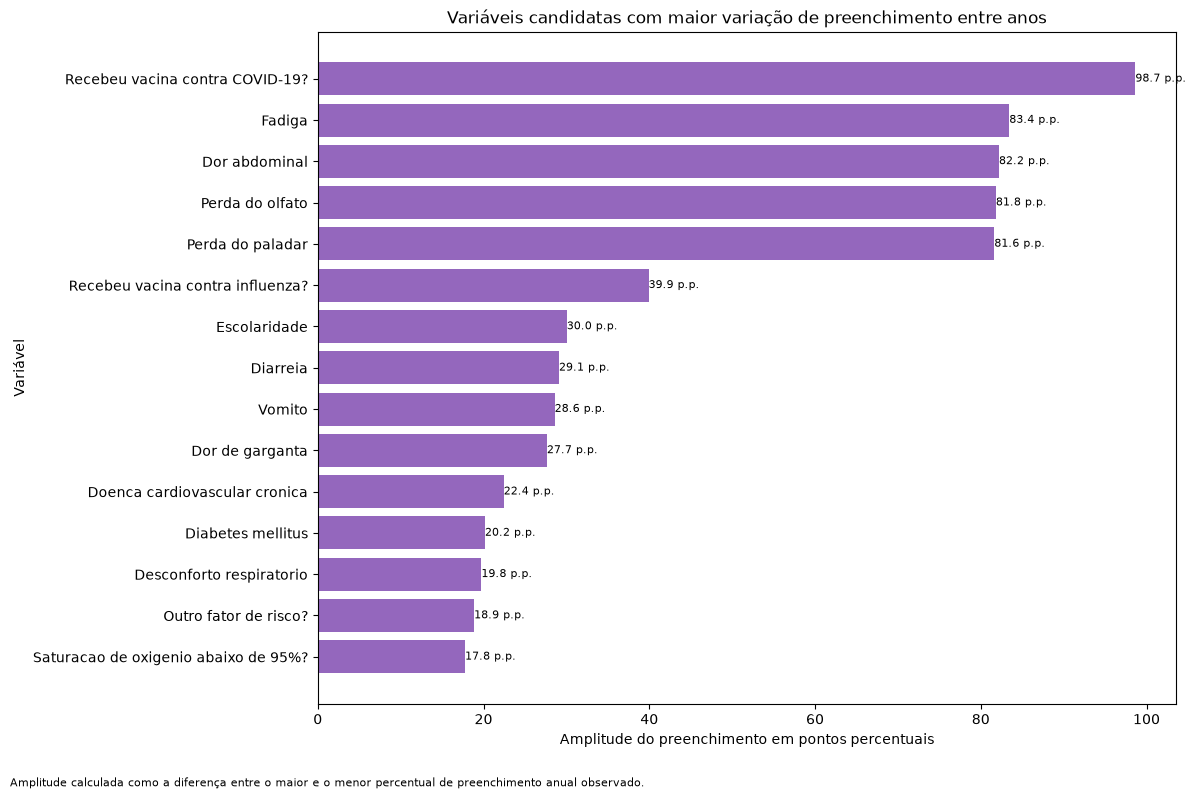

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_variacao_preenchimento.png


In [29]:
USOS_RELEVANTES_PARA_GRAFICO = {
    "modelo_a_nucleo",
    "modelo_b_ampliado",
    "modelo_c_sensibilidade",
    "derivar_atributo",
    "reavaliar_apos_eda",
    "reavaliar_apos_modelo_principal",
    "exploracao_subgrupo",
}

variaveis_relevantes_variacao = (
    variacao_preenchimento.loc[
        variacao_preenchimento[
            "uso_inicial_sugerido"
        ].isin(
            USOS_RELEVANTES_PARA_GRAFICO
        )
    ]
    .copy()
)

QUANTIDADE_VARIAVEIS_GRAFICO = 15

variaveis_grafico = (
    variaveis_relevantes_variacao.head(
        QUANTIDADE_VARIAVEIS_GRAFICO
    )
    .copy()
)

if variaveis_grafico.empty:
    raise ValueError(
        "Nenhuma variável foi selecionada para "
        "o gráfico de variação de preenchimento."
    )

variaveis_grafico[
    "rotulo_variavel"
] = (
    variaveis_grafico[
        "nome_amigavel"
    ]
    .where(
        variaveis_grafico[
            "nome_amigavel"
        ].str.strip().ne(""),
        variaveis_grafico[
            "coluna"
        ],
    )
)

display(
    variaveis_grafico[
        [
            "coluna",
            "rotulo_variavel",
            "grupo",
            "uso_inicial_sugerido",
            "preenchimento_minimo",
            "preenchimento_maximo",
            "amplitude_pontos_percentuais",
        ]
    ]
)

variaveis_grafico = (
    variaveis_grafico
    .sort_values(
        "amplitude_pontos_percentuais",
        ascending=True,
    )
    .reset_index(drop=True)
)

figura_variacao, eixo_variacao = plt.subplots(
    figsize=(
        12,
        8,
    )
)

barras_variacao = eixo_variacao.barh(
    variaveis_grafico[
        "rotulo_variavel"
    ],
    variaveis_grafico[
        "amplitude_pontos_percentuais"
    ],
    color="tab:purple",
)

eixo_variacao.set_title(
    "Variáveis candidatas com maior variação de preenchimento entre anos"
)

eixo_variacao.set_xlabel(
    "Amplitude do preenchimento em pontos percentuais"
)

eixo_variacao.set_ylabel(
    "Variável"
)

for barra, amplitude in zip(
    barras_variacao,
    variaveis_grafico[
        "amplitude_pontos_percentuais"
    ],
):
    eixo_variacao.text(
        barra.get_width(),
        barra.get_y()
        + barra.get_height()
        / 2,
        f"{amplitude:.1f} p.p.",
        va="center",
        ha="left",
        fontsize=8,
    )

figura_variacao.text(
    0.01,
    0.01,
    (
        "Amplitude calculada como a diferença entre o maior e o menor "
        "percentual de preenchimento anual observado."
    ),
    fontsize=8,
)

figura_variacao.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_variacao.savefig(
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
)

In [30]:
preenchimento_por_variavel_ano.to_csv(
    CAMINHO_PREENCHIMENTO_ANO,
    index=False,
    encoding="utf-8-sig",
)

resumo_preenchimento_variaveis.to_csv(
    CAMINHO_RESUMO_PREENCHIMENTO,
    index=False,
    encoding="utf-8-sig",
)

variacao_preenchimento.to_csv(
    CAMINHO_VARIACAO_PREENCHIMENTO,
    index=False,
    encoding="utf-8-sig",
)

quantidade_anos_observados = (
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

quantidade_linhas_esperada = (
    len(
        colunas_dicionario_na_coorte
    )
    * quantidade_anos_observados
)

percentuais_preenchimento_validos = (
    preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_ausencia_validos = (
    preenchimento_por_variavel_ano[
        "percentual_ausente"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

soma_percentuais_valida = (
    preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
    .add(
        preenchimento_por_variavel_ano[
            "percentual_ausente"
        ]
    )
    .sub(100)
    .abs()
    .lt(0.000001)
    .all()
)

verificacoes_preenchimento = {
    "tabela_anual_nao_vazia": (
        not preenchimento_por_variavel_ano.empty
    ),
    "resumo_global_nao_vazio": (
        not resumo_preenchimento_variaveis.empty
    ),
    "variacao_nao_vazia": (
        not variacao_preenchimento.empty
    ),
    "uma_linha_por_variavel_e_ano": (
        len(
            preenchimento_por_variavel_ano
        )
        == quantidade_linhas_esperada
    ),
    "todas_variaveis_no_resumo": (
        len(
            resumo_preenchimento_variaveis
        )
        == len(
            colunas_dicionario_na_coorte
        )
    ),
    "percentuais_preenchimento_validos": (
        percentuais_preenchimento_validos
    ),
    "percentuais_ausencia_validos": (
        percentuais_ausencia_validos
    ),
    "preenchimento_e_ausencia_somam_100": (
        soma_percentuais_valida
    ),
    "arquivo_anual_criado": (
        CAMINHO_PREENCHIMENTO_ANO.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_PREENCHIMENTO.exists()
    ),
    "arquivo_variacao_criado": (
        CAMINHO_VARIACAO_PREENCHIMENTO.exists()
    ),
    "figura_variacao_criada": (
        CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO.exists()
    ),
}

verificacoes_preenchimento_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_preenchimento.keys()
        ),
        "resultado": list(
            verificacoes_preenchimento.values()
        ),
    }
)

display(
    verificacoes_preenchimento_df
)

if not all(
    verificacoes_preenchimento.values()
):
    falhas_preenchimento = [
        verificacao
        for verificacao, resultado
        in verificacoes_preenchimento.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de preenchimento terminou com falhas: "
        f"{falhas_preenchimento}"
    )

print(
    "Análise de preenchimento validada com sucesso."
)

,verificacao,resultado
0,tabela_anual_nao_vazia,True
1,resumo_global_nao_vazio,True
2,variacao_nao_vazia,True
3,uma_linha_por_variavel_e_ano,True
4,todas_variaveis_no_resumo,True
5,percentuais_preenchimento_validos,True
6,percentuais_ausencia_validos,True
7,preenchimento_e_ausencia_somam_100,True
8,arquivo_anual_criado,True
9,arquivo_resumo_criado,True


Análise de preenchimento validada com sucesso.


In [31]:

COLUNAS_SINTOMAS = [
    coluna
    for coluna in COLUNAS_SINTOMAS_PLANEJADAS
    if coluna in coorte.columns
]

COLUNAS_COMORBIDADES = [
    coluna
    for coluna in COLUNAS_COMORBIDADES_PLANEJADAS
    if coluna in coorte.columns
]

SINTOMAS_AUSENTES_NA_COORTE = [
    coluna
    for coluna in COLUNAS_SINTOMAS_PLANEJADAS
    if coluna not in coorte.columns
]

COMORBIDADES_AUSENTES_NA_COORTE = [
    coluna
    for coluna in COLUNAS_COMORBIDADES_PLANEJADAS
    if coluna not in coorte.columns
]

if not COLUNAS_SINTOMAS:
    raise ValueError(
        "Nenhuma variável estruturada de sintomas "
        "foi encontrada na coorte."
    )

if not COLUNAS_COMORBIDADES:
    raise ValueError(
        "Nenhuma variável estruturada de comorbidades "
        "foi encontrada na coorte."
    )

print(
    "Sintomas encontrados:",
    len(COLUNAS_SINTOMAS),
)

print(
    "Comorbidades encontradas:",
    len(COLUNAS_COMORBIDADES),
)

if SINTOMAS_AUSENTES_NA_COORTE:
    print(
        "Sintomas ausentes na coorte:",
        SINTOMAS_AUSENTES_NA_COORTE,
    )

if COMORBIDADES_AUSENTES_NA_COORTE:
    print(
        "Comorbidades ausentes na coorte:",
        COMORBIDADES_AUSENTES_NA_COORTE,
    )

Sintomas encontrados: 13
Comorbidades encontradas: 13


In [32]:
nomes_amigaveis_dicionario = (
    dicionario_operacional.set_index(
        "coluna"
    )[
        "nome_amigavel"
    ]
    .to_dict()
)

CAMINHO_SINTOMAS_ANO = (
    C.TABLES_DIR
    / "04_eda_sintomas_por_ano.csv"
)

CAMINHO_COMORBIDADES_ANO = (
    C.TABLES_DIR
    / "04_eda_comorbidades_por_ano.csv"
)

CAMINHO_CONTADORES_CLINICOS_ANO = (
    C.TABLES_DIR
    / "04_eda_contadores_clinicos_por_ano.csv"
)

CAMINHO_VARIACAO_SINTOMAS = (
    C.TABLES_DIR
    / "04_eda_variacao_sintomas.csv"
)

CAMINHO_VARIACAO_COMORBIDADES = (
    C.TABLES_DIR
    / "04_eda_variacao_comorbidades.csv"
)

CAMINHO_FIGURA_SINTOMAS = (
    C.FIGURES_DIR
    / "04_eda_sintomas_por_ano.png"
)

CAMINHO_FIGURA_COMORBIDADES = (
    C.FIGURES_DIR
    / "04_eda_comorbidades_por_ano.png"
)

print(
    "Tabela de sintomas:",
    CAMINHO_SINTOMAS_ANO,
)

print(
    "Tabela de comorbidades:",
    CAMINHO_COMORBIDADES_ANO,
)

print(
    "Tabela de contadores clínicos:",
    CAMINHO_CONTADORES_CLINICOS_ANO,
)

Tabela de sintomas: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_sintomas_por_ano.csv
Tabela de comorbidades: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_comorbidades_por_ano.csv
Tabela de contadores clínicos: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_contadores_clinicos_por_ano.csv


In [33]:
def normalizar_resposta_clinica(
    serie: pd.Series,
) -> pd.Series:
    """Normaliza respostas estruturadas sem converter ausência em não."""

    codigos_linhas, valores_distintos = pd.factorize(
        serie.astype("string"),
        use_na_sentinel=False,
    )

    codigo = (
        pd.Series(
            valores_distintos,
            dtype="string",
        )
        .str.strip()
        .str.upper()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
        .replace(
            {
                "": pd.NA,
                "NAN": pd.NA,
                "NONE": pd.NA,
                "<NA>": pd.NA,
            }
        )
    )

    mapa_respostas = {
        "1": "sim",
        "SIM": "sim",
        "S": "sim",
        "2": "nao",
        "NÃO": "nao",
        "NAO": "nao",
        "N": "nao",
        "9": "ignorado",
        "IGNORADO": "ignorado",
        "I": "ignorado",
    }

    resposta = (
        codigo.map(
            mapa_respostas
        )
    )

    resposta = resposta.where(
        codigo.notna(),
        "ausente",
    )

    resposta = resposta.fillna(
        "inesperado"
    )

    return pd.Series(
        resposta.to_numpy(dtype=object)[codigos_linhas],
        index=serie.index,
        dtype="string",
    )

In [34]:
def criar_tabela_clinica_por_ano(
    dataframe: pd.DataFrame,
    colunas: list,
    grupo_clinico: str,
    nomes_amigaveis: dict,
) -> pd.DataFrame:
    """Cria uma tabela longa de sintomas ou comorbidades por ano."""

    registros = []

    anos_observados = (
        dataframe[
            "ano_internacao"
        ]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
        .tolist()
    )

    for coluna in colunas:
        resposta_normalizada = (
            normalizar_resposta_clinica(
                dataframe[
                    coluna
                ]
            )
        )

        tabela_variavel = pd.DataFrame(
            {
                "ano_internacao": dataframe[
                    "ano_internacao"
                ],
                "resposta": resposta_normalizada,
            }
        )

        contagem = (
            tabela_variavel.groupby(
                [
                    "ano_internacao",
                    "resposta",
                ],
                dropna=False,
            )
            .size()
            .unstack(
                fill_value=0
            )
        )

        contagem = contagem.reindex(
            index=anos_observados,
            fill_value=0,
        )

        contagem = contagem.reindex(
            columns=[
                "sim",
                "nao",
                "ignorado",
                "ausente",
                "inesperado",
            ],
            fill_value=0,
        )

        for ano in anos_observados:
            quantidade_sim = int(
                contagem.loc[
                    ano,
                    "sim",
                ]
            )

            quantidade_nao = int(
                contagem.loc[
                    ano,
                    "nao",
                ]
            )

            quantidade_ignorado = int(
                contagem.loc[
                    ano,
                    "ignorado",
                ]
            )

            quantidade_ausente = int(
                contagem.loc[
                    ano,
                    "ausente",
                ]
            )

            quantidade_inesperado = int(
                contagem.loc[
                    ano,
                    "inesperado",
                ]
            )

            quantidade_total = (
                quantidade_sim
                + quantidade_nao
                + quantidade_ignorado
                + quantidade_ausente
                + quantidade_inesperado
            )

            quantidade_respostas_validas = (
                quantidade_sim
                + quantidade_nao
            )

            if quantidade_respostas_validas == 0:
                percentual_sim_validos = np.nan
                percentual_nao_validos = np.nan
            else:
                percentual_sim_validos = (
                    quantidade_sim
                    / quantidade_respostas_validas
                    * 100
                )

                percentual_nao_validos = (
                    quantidade_nao
                    / quantidade_respostas_validas
                    * 100
                )

            if quantidade_total == 0:
                percentual_sem_resposta_valida = np.nan
            else:
                percentual_sem_resposta_valida = (
                    (
                        quantidade_ignorado
                        + quantidade_ausente
                        + quantidade_inesperado
                    )
                    / quantidade_total
                    * 100
                )

            registros.append(
                {
                    "ano_internacao": int(
                        ano
                    ),
                    "grupo_clinico": grupo_clinico,
                    "coluna": coluna,
                    "nome_amigavel": (
                        nomes_amigaveis.get(
                            coluna,
                            coluna,
                        )
                    ),
                    "quantidade_total": (
                        quantidade_total
                    ),
                    "quantidade_sim": (
                        quantidade_sim
                    ),
                    "quantidade_nao": (
                        quantidade_nao
                    ),
                    "quantidade_ignorado": (
                        quantidade_ignorado
                    ),
                    "quantidade_ausente": (
                        quantidade_ausente
                    ),
                    "quantidade_inesperado": (
                        quantidade_inesperado
                    ),
                    "quantidade_respostas_validas": (
                        quantidade_respostas_validas
                    ),
                    "percentual_sim_validos": (
                        percentual_sim_validos
                    ),
                    "percentual_nao_validos": (
                        percentual_nao_validos
                    ),
                    "percentual_sem_resposta_valida": (
                        percentual_sem_resposta_valida
                    ),
                }
            )

    resultado = pd.DataFrame(
        registros
    )

    resultado = (
        resultado.sort_values(
            [
                "coluna",
                "ano_internacao",
            ]
        )
        .reset_index(drop=True)
    )

    return resultado

In [35]:
sintomas_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_SINTOMAS,
        grupo_clinico="sintomas",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

comorbidades_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_COMORBIDADES,
        grupo_clinico="comorbidades",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

display(
    sintomas_por_ano.head(20)
)

display(
    comorbidades_por_ano.head(20)
)

,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,sintomas,desc_resp,Desconforto respiratorio,43392,36428,6383,270,311,0,42811,85.090281,14.909719,1.338956
1,2020,sintomas,desc_resp,Desconforto respiratorio,974415,557926,262682,13363,140444,0,820608,67.989344,32.010656,15.784548
2,2021,sintomas,desc_resp,Desconforto respiratorio,1471091,828013,364544,15648,262886,0,1192557,69.431734,30.568266,18.933839
3,2022,sintomas,desc_resp,Desconforto respiratorio,470323,236652,133071,4338,96262,0,369723,64.007919,35.992081,21.389556
4,2023,sintomas,desc_resp,Desconforto respiratorio,237976,148542,52781,1097,35556,0,201323,73.782926,26.217074,15.401973
5,2024,sintomas,desc_resp,Desconforto respiratorio,226749,150921,49069,649,26110,0,199990,75.464273,24.535727,11.801155
6,2025,sintomas,desc_resp,Desconforto respiratorio,286837,200604,62392,689,23152,0,262996,76.276445,23.723555,8.311689
7,2026,sintomas,desc_resp,Desconforto respiratorio,173945,125747,35151,603,12444,0,160898,78.153240,21.846760,7.500647
8,2019,sintomas,diarreia,Diarreia,43392,3877,37134,1343,1038,0,41011,9.453561,90.546439,5.487187
9,2020,sintomas,diarreia,Diarreia,974415,120987,601592,23549,228287,0,722579,16.743775,83.256225,25.844840


,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,comorbidades,asma,Asma,43392,2499,14066,258,26569,0,16565,15.086025,84.913975,61.824760
1,2020,comorbidades,asma,Asma,974415,38255,378185,11528,546447,0,416440,9.186197,90.813803,57.262563
2,2021,comorbidades,asma,Asma,1471091,46082,476655,10638,937716,0,522737,8.815523,91.184477,64.466032
3,2022,comorbidades,asma,Asma,470323,23001,148785,2451,296086,0,171786,13.389333,86.610667,63.474889
4,2023,comorbidades,asma,Asma,237976,16856,56486,730,163904,0,73342,22.982738,77.017262,69.180926
5,2024,comorbidades,asma,Asma,226749,15548,54686,500,156015,0,70234,22.137426,77.862574,69.025663
6,2025,comorbidades,asma,Asma,286837,21063,71616,466,193692,0,92679,22.726831,77.273169,67.689315
7,2026,comorbidades,asma,Asma,173945,13918,39446,208,120373,0,53364,26.081253,73.918747,69.321337
8,2019,comorbidades,cardiopati,Doenca cardiovascular cronica,43392,4680,12102,190,26420,0,16782,27.887022,72.112978,61.324668
9,2020,comorbidades,cardiopati,Doenca cardiovascular cronica,974415,322595,198688,6433,446699,0,521283,61.884811,38.115189,46.502979


In [36]:

import gc

def contar_respostas_clinicas(
    dataframe: pd.DataFrame,
    colunas: list[str],
    coluna_confirmados: str,
    coluna_avaliados: str,
) -> None:
    """Calcula as quantidades de respostas confirmadas e avaliadas sem manter grandes matrizes textuais simultaneamente."""

    if not colunas:
        raise ValueError(
            "A lista de colunas clínicas está vazia."
        )

    colunas_ausentes = [
        coluna
        for coluna in colunas
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "Não foi possível calcular os contadores clínicos. "
            "As seguintes colunas não existem na coorte: "
            f"{colunas_ausentes}"
        )

    quantidade_linhas = len(
        dataframe
    )

    confirmados = np.zeros(
        quantidade_linhas,
        dtype=np.int16,
    )

    avaliados = np.zeros(
        quantidade_linhas,
        dtype=np.int16,
    )

    for coluna in colunas:
        resposta = normalizar_resposta_clinica(
            dataframe[coluna]
        )

        mascara_confirmado = (
            resposta.eq("sim")
            .to_numpy(
                dtype=bool,
                copy=False,
            )
        )

        mascara_avaliado = (
            resposta.isin(
                [
                    "sim",
                    "nao",
                ]
            )
            .to_numpy(
                dtype=bool,
                copy=False,
            )
        )

        confirmados += (
            mascara_confirmado
            .astype(
                np.int16,
                copy=False,
            )
        )

        avaliados += (
            mascara_avaliado
            .astype(
                np.int16,
                copy=False,
            )
        )

        del resposta
        del mascara_confirmado
        del mascara_avaliado

    dataframe[coluna_confirmados] = pd.Series(
        confirmados,
        index=dataframe.index,
        dtype="Int16",
    )

    dataframe[coluna_avaliados] = pd.Series(
        avaliados,
        index=dataframe.index,
        dtype="Int16",
    )

    if not dataframe[coluna_confirmados].between(
        0,
        len(colunas),
        inclusive="both",
    ).all():
        raise RuntimeError(
            f"A coluna {coluna_confirmados!r} contém "
            "valores fora do intervalo esperado."
        )

    if not dataframe[coluna_avaliados].between(
        0,
        len(colunas),
        inclusive="both",
    ).all():
        raise RuntimeError(
            f"A coluna {coluna_avaliados!r} contém "
            "valores fora do intervalo esperado."
        )

    if (
        dataframe[coluna_confirmados]
        .gt(
            dataframe[coluna_avaliados]
        )
        .any()
    ):
        raise RuntimeError(
            "A quantidade de condições confirmadas não pode "
            "ser maior que a quantidade avaliada."
        )

    del confirmados
    del avaliados

    gc.collect()


COLUNAS_CONTADORES_INCORRETAS = [
    "n_comorbidades_confirmados",
    "n_comorbidades_avaliados",
]

colunas_incorretas_presentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_INCORRETAS
    if coluna in coorte.columns
]

if colunas_incorretas_presentes:
    coorte.drop(
        columns=colunas_incorretas_presentes,
        inplace=True,
    )

    print(
        "Colunas com nomes incorretos removidas:",
        colunas_incorretas_presentes,
    )


contar_respostas_clinicas(
    dataframe=coorte,
    colunas=COLUNAS_SINTOMAS,
    coluna_confirmados="n_sintomas_confirmados",
    coluna_avaliados="n_sintomas_avaliados",
)


contar_respostas_clinicas(
    dataframe=coorte,
    colunas=COLUNAS_COMORBIDADES,
    coluna_confirmados="n_comorbidades_confirmadas",
    coluna_avaliados="n_comorbidades_avaliadas",
)


coorte["flag_multimorbidade"] = (
    coorte["n_comorbidades_confirmadas"]
    .ge(2)
    .astype("int8")
)


COLUNAS_CONTADORES_CLINICOS = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

colunas_contadores_ausentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_CLINICOS
    if coluna not in coorte.columns
]

if colunas_contadores_ausentes:
    raise RuntimeError(
        "Os contadores clínicos não foram criados corretamente. "
        "Colunas ausentes: "
        f"{colunas_contadores_ausentes}"
    )


print(
    "Contadores clínicos criados "
    "sem matrizes textuais persistentes."
)

print(
    "Colunas criadas:",
    COLUNAS_CONTADORES_CLINICOS,
)

display(
    coorte[
        COLUNAS_CONTADORES_CLINICOS
    ]
    .describe()
)

Contadores clínicos criados sem matrizes textuais persistentes.
Colunas criadas: ['n_sintomas_confirmados', 'n_sintomas_avaliados', 'n_comorbidades_confirmadas', 'n_comorbidades_avaliadas', 'flag_multimorbidade']


,n_sintomas_confirmados,n_sintomas_avaliados,n_comorbidades_confirmadas,n_comorbidades_avaliadas,flag_multimorbidade
count,3884728.0,3884728.0,3884728.0,3884728.0,3.884728e+06
mean,4.142065,9.695599,0.941079,4.870517,2.687457e-01
std,1.850346,4.267144,1.073624,5.944442,4.433075e-01
min,0.0,0.0,0.0,0.0,0.000000e+00
25%,3.0,5.0,0.0,0.0,0.000000e+00
50%,4.0,13.0,1.0,1.0,0.000000e+00
75%,5.0,13.0,2.0,13.0,1.000000e+00
max,13.0,13.0,13.0,13.0,1.000000e+00


In [37]:
contadores_clinicos_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "ano_internacao",
            "size",
        ),
        sintomas_confirmados_media=(
            "n_sintomas_confirmados",
            "mean",
        ),
        sintomas_confirmados_mediana=(
            "n_sintomas_confirmados",
            "median",
        ),
        sintomas_avaliados_media=(
            "n_sintomas_avaliados",
            "mean",
        ),
        comorbidades_confirmadas_media=(
            "n_comorbidades_confirmadas",
            "mean",
        ),
        comorbidades_confirmadas_mediana=(
            "n_comorbidades_confirmadas",
            "median",
        ),
        comorbidades_avaliadas_media=(
            "n_comorbidades_avaliadas",
            "mean",
        ),
        quantidade_multimorbidade=(
            "flag_multimorbidade",
            "sum",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

contadores_clinicos_por_ano[
    "percentual_multimorbidade"
] = (
    contadores_clinicos_por_ano[
        "quantidade_multimorbidade"
    ]
    .div(
        contadores_clinicos_por_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

display(
    contadores_clinicos_por_ano
)

,ano_internacao,quantidade_registros,sintomas_confirmados_media,sintomas_confirmados_mediana,sintomas_avaliados_media,comorbidades_confirmadas_media,comorbidades_confirmadas_mediana,comorbidades_avaliadas_media,quantidade_multimorbidade,percentual_multimorbidade
0,2019,43392,4.794617,5.0,8.633435,0.650327,0.0,4.938007,6800,15.671091
1,2020,974415,4.033549,4.0,9.060519,1.135779,1.0,5.76689,325926,33.448377
2,2021,1471091,4.327608,4.0,9.669373,0.975763,1.0,4.837385,414433,28.171813
3,2022,470323,3.717947,4.0,9.460728,0.987862,1.0,4.871118,133281,28.338185
4,2023,237976,4.000059,4.0,9.973304,0.724846,0.0,3.93996,45904,19.28934
5,2024,226749,4.13032,4.0,10.385867,0.686517,0.0,3.955034,41425,18.269099
6,2025,286837,4.197551,4.0,10.933534,0.655142,0.0,4.090236,49397,17.221279
7,2026,173945,4.282848,4.0,11.053942,0.602294,0.0,3.864101,26838,15.429015


In [38]:
def calcular_variacao_clinica(
    tabela_clinica: pd.DataFrame,
) -> pd.DataFrame:
    """
    Resume a variação anual da proporção de respostas sim.
    """

    resultado = (
        tabela_clinica.groupby(
            [
                "grupo_clinico",
                "coluna",
                "nome_amigavel",
            ],
            dropna=False,
        )
        .agg(
            percentual_sim_minimo=(
                "percentual_sim_validos",
                "min",
            ),
            percentual_sim_maximo=(
                "percentual_sim_validos",
                "max",
            ),
            percentual_sim_medio=(
                "percentual_sim_validos",
                "mean",
            ),
            percentual_sem_resposta_valida_maximo=(
                "percentual_sem_resposta_valida",
                "max",
            ),
            quantidade_anos_observados=(
                "ano_internacao",
                "nunique",
            ),
        )
        .reset_index()
    )

    resultado[
        "amplitude_percentual_sim"
    ] = (
        resultado[
            "percentual_sim_maximo"
        ]
        .sub(
            resultado[
                "percentual_sim_minimo"
            ]
        )
    )

    resultado[
        "flag_variacao_10_pp"
    ] = (
        resultado[
            "amplitude_percentual_sim"
        ]
        .ge(10)
    )

    resultado = (
        resultado.sort_values(
            [
                "amplitude_percentual_sim",
                "coluna",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    return resultado


variacao_sintomas = (
    calcular_variacao_clinica(
        sintomas_por_ano
    )
)

variacao_comorbidades = (
    calcular_variacao_clinica(
        comorbidades_por_ano
    )
)

display(
    variacao_sintomas
)

display(
    variacao_comorbidades
)

,grupo_clinico,coluna,nome_amigavel,percentual_sim_minimo,percentual_sim_maximo,percentual_sim_medio,percentual_sem_resposta_valida_maximo,quantidade_anos_observados,amplitude_percentual_sim,flag_variacao_10_pp
0,sintomas,fadiga,Fadiga,21.304499,50.660793,28.183663,99.476862,8,29.356294,True
1,sintomas,febre,Febre,61.496012,88.735499,69.695489,18.588289,8,27.239487,True
2,sintomas,desc_resp,Desconforto respiratorio,64.007919,85.090281,73.774520,21.389556,8,21.082361,True
3,sintomas,outro_sin,Apresentou outros sintomas?,25.142604,46.125307,38.570735,31.421597,8,20.982703,True
4,sintomas,tosse,Tosse,76.130208,93.388871,83.367387,12.921159,8,17.258662,True
5,sintomas,saturacao,Saturacao de oxigenio abaixo de 95%?,61.022151,77.043969,66.712164,20.162527,8,16.021818,True
6,sintomas,perd_pala,Perda do paladar,0.869565,13.097523,4.302944,99.734974,8,12.227958,True
7,sintomas,perd_olft,Perda do olfato,0.869565,12.842341,4.221967,99.734974,8,11.972776,True
8,sintomas,dispneia,Dispneia,72.688406,83.651963,76.393838,16.252448,8,10.963557,True
9,sintomas,garganta,Dor de garganta,13.372231,23.293317,17.528870,31.456892,8,9.921086,False


,grupo_clinico,coluna,nome_amigavel,percentual_sim_minimo,percentual_sim_maximo,percentual_sim_medio,percentual_sem_resposta_valida_maximo,quantidade_anos_observados,amplitude_percentual_sim,flag_variacao_10_pp
0,comorbidades,cardiopati,Doenca cardiovascular cronica,27.887022,62.538807,48.645988,68.400931,8,34.651785,True
1,comorbidades,diabetes,Diabetes mellitus,19.549913,46.408440,33.125874,69.497830,8,26.858528,True
2,comorbidades,obesidade,Obesidade,4.112634,22.640659,9.580133,71.334084,8,18.528025,True
3,comorbidades,asma,Asma,8.815523,26.081253,17.550666,69.321337,8,17.265730,True
4,comorbidades,out_morbi,Outro fator de risco?,46.319858,59.841626,52.863165,68.913162,8,13.521768,True
5,comorbidades,pneumopati,Outra pneumopatia cronica,9.034147,18.084402,15.510518,70.181379,8,9.050255,False
6,comorbidades,neurologic,Doenca neurologica cronica,9.221022,16.781076,13.790006,70.304981,8,7.560054,False
7,comorbidades,renal,Doenca renal cronica,5.943627,10.640829,8.088698,70.865503,8,4.697201,False
8,comorbidades,imunodepre,Imunodeficiencia ou imunodepressao,5.863559,10.196031,8.319239,70.678088,8,4.332472,False
9,comorbidades,sind_down,Sindrome de Down,0.724400,3.731976,2.197276,71.074394,8,3.007577,False


In [39]:
QUANTIDADE_INDICADORES_GRAFICO = 8

sintomas_grafico = (
    variacao_sintomas.head(
        QUANTIDADE_INDICADORES_GRAFICO
    )[
        [
            "coluna",
            "nome_amigavel",
        ]
    ]
    .copy()
)

comorbidades_grafico = (
    variacao_comorbidades.head(
        QUANTIDADE_INDICADORES_GRAFICO
    )[
        [
            "coluna",
            "nome_amigavel",
        ]
    ]
    .copy()
)

if sintomas_grafico.empty:
    raise ValueError(
        "Nenhum sintoma foi selecionado para o gráfico."
    )

if comorbidades_grafico.empty:
    raise ValueError(
        "Nenhuma comorbidade foi selecionada para o gráfico."
    )

display(
    sintomas_grafico
)

display(
    comorbidades_grafico
)

,coluna,nome_amigavel
0,fadiga,Fadiga
1,febre,Febre
2,desc_resp,Desconforto respiratorio
3,outro_sin,Apresentou outros sintomas?
4,tosse,Tosse
5,saturacao,Saturacao de oxigenio abaixo de 95%?
6,perd_pala,Perda do paladar
7,perd_olft,Perda do olfato


,coluna,nome_amigavel
0,cardiopati,Doenca cardiovascular cronica
1,diabetes,Diabetes mellitus
2,obesidade,Obesidade
3,asma,Asma
4,out_morbi,Outro fator de risco?
5,pneumopati,Outra pneumopatia cronica
6,neurologic,Doenca neurologica cronica
7,renal,Doenca renal cronica


In [40]:
def criar_grafico_clinico_temporal(
    tabela_clinica: pd.DataFrame,
    selecao_variaveis: pd.DataFrame,
    titulo: str,
    caminho_saida: Path,
) -> None:
    """
    Cria um gráfico de linhas com a proporção anual de resposta sim.
    """

    colunas_selecionadas = (
        selecao_variaveis[
            "coluna"
        ]
        .tolist()
    )

    dados_grafico = (
        tabela_clinica.loc[
            tabela_clinica[
                "coluna"
            ].isin(
                colunas_selecionadas
            )
        ]
        .copy()
    )

    dados_grafico[
        "rotulo"
    ] = (
        dados_grafico[
            "nome_amigavel"
        ]
        .where(
            dados_grafico[
                "nome_amigavel"
            ]
            .astype("string")
            .str.strip()
            .ne(""),
            dados_grafico[
                "coluna"
            ],
        )
    )

    figura, eixo = plt.subplots(
        figsize=(
            13,
            7,
        )
    )

    for rotulo in dados_grafico[
        "rotulo"
    ].drop_duplicates():
        serie_variavel = (
            dados_grafico.loc[
                dados_grafico[
                    "rotulo"
                ].eq(
                    rotulo
                )
            ]
            .sort_values(
                "ano_internacao"
            )
        )

        eixo.plot(
            serie_variavel[
                "ano_internacao"
            ].astype(int),
            serie_variavel[
                "percentual_sim_validos"
            ],
            marker="o",
            linewidth=2,
            label=rotulo,
        )

    anos_grafico = (
        dados_grafico[
            "ano_internacao"
        ]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Ano da internação"
    )

    eixo.set_ylabel(
        "Resposta sim entre respostas válidas"
    )

    eixo.set_xticks(
        anos_grafico
    )

    eixo.set_ylim(
        bottom=0
    )

    eixo.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )

    eixo.legend(
        bbox_to_anchor=(
            1.02,
            1,
        ),
        loc="upper left",
        title="Indicador",
    )

    figura.text(
        0.01,
        0.01,
        (
            "Denominador de cada indicador: respostas sim ou não. "
            "Ignorado, ausente e código inesperado não entram "
            "no denominador da proporção."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.04,
            0.82,
            1,
        ]
    )

    figura.savefig(
        caminho_saida,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        caminho_saida,
    )

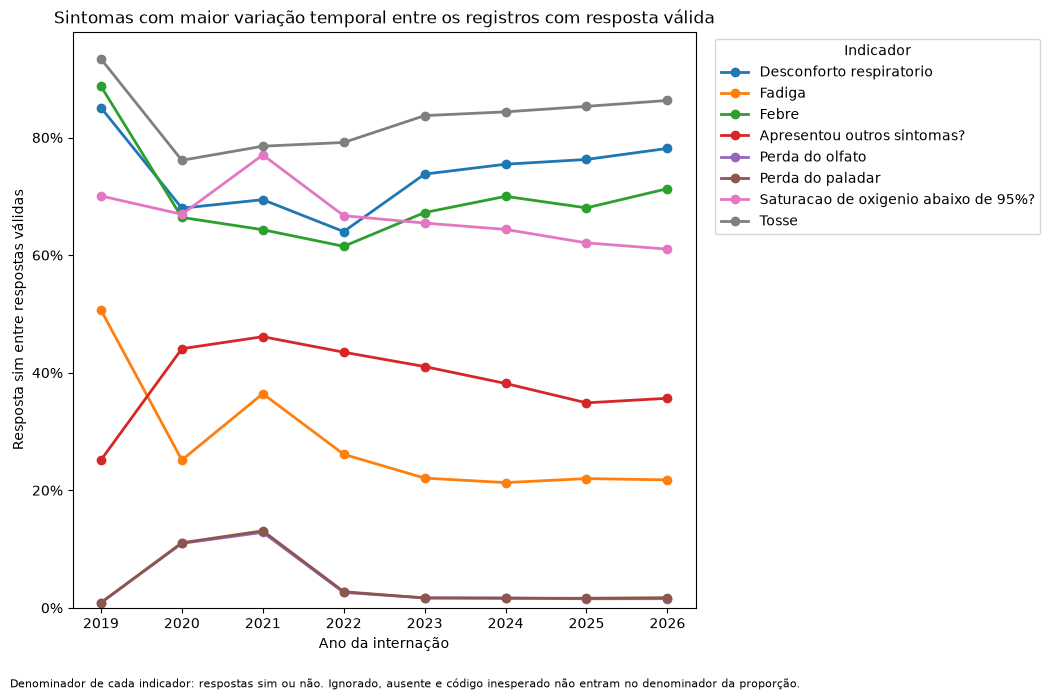

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_sintomas_por_ano.png


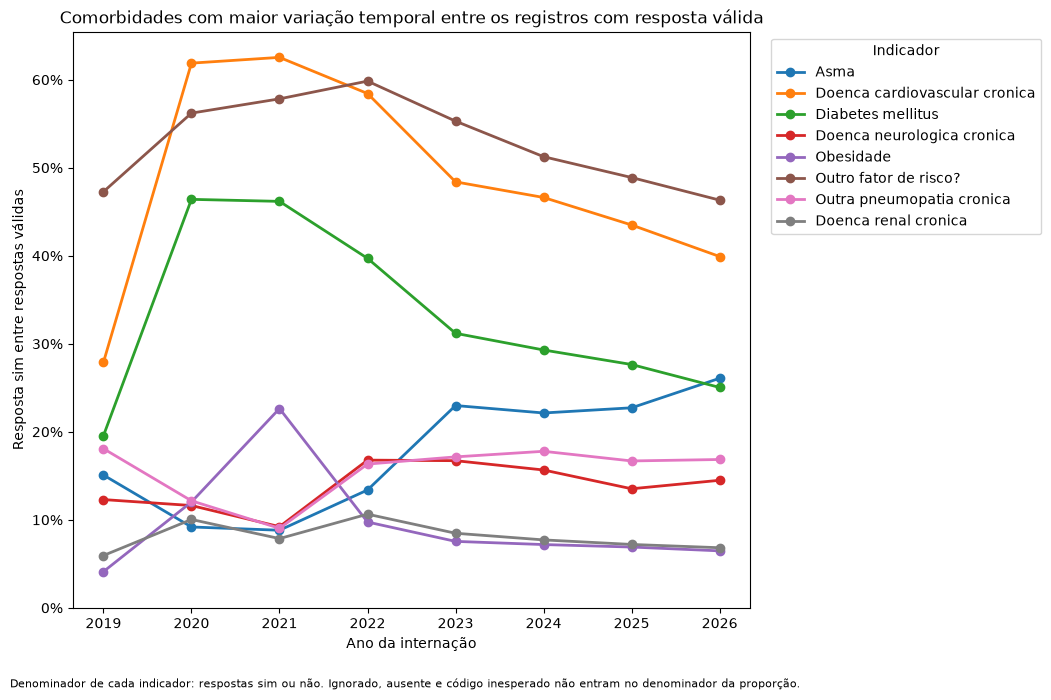

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_comorbidades_por_ano.png


In [41]:
criar_grafico_clinico_temporal(
    tabela_clinica=sintomas_por_ano,
    selecao_variaveis=sintomas_grafico,
    titulo=(
        "Sintomas com maior variação temporal "
        "entre os registros com resposta válida"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_SINTOMAS
    ),
)

criar_grafico_clinico_temporal(
    tabela_clinica=comorbidades_por_ano,
    selecao_variaveis=(
        comorbidades_grafico
    ),
    titulo=(
        "Comorbidades com maior variação temporal "
        "entre os registros com resposta válida"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_COMORBIDADES
    ),
)

In [42]:
sintomas_por_ano.to_csv(
    CAMINHO_SINTOMAS_ANO,
    index=False,
    encoding="utf-8-sig",
)

comorbidades_por_ano.to_csv(
    CAMINHO_COMORBIDADES_ANO,
    index=False,
    encoding="utf-8-sig",
)

contadores_clinicos_por_ano.to_csv(
    CAMINHO_CONTADORES_CLINICOS_ANO,
    index=False,
    encoding="utf-8-sig",
)

variacao_sintomas.to_csv(
    CAMINHO_VARIACAO_SINTOMAS,
    index=False,
    encoding="utf-8-sig",
)

variacao_comorbidades.to_csv(
    CAMINHO_VARIACAO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

anos_clinicos_observados = (
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

linhas_sintomas_esperadas = (
    len(
        COLUNAS_SINTOMAS
    )
    * anos_clinicos_observados
)

linhas_comorbidades_esperadas = (
    len(
        COLUNAS_COMORBIDADES
    )
    * anos_clinicos_observados
)

totais_sintomas_validos = (
    sintomas_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        sintomas_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

totais_comorbidades_validos = (
    comorbidades_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        comorbidades_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

percentuais_sintomas_validos = (
    sintomas_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_comorbidades_validos = (
    comorbidades_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

verificacoes_clinicas = {
    "sintomas_por_ano_nao_vazio": (
        not sintomas_por_ano.empty
    ),
    "comorbidades_por_ano_nao_vazio": (
        not comorbidades_por_ano.empty
    ),
    "contadores_por_ano_nao_vazio": (
        not contadores_clinicos_por_ano.empty
    ),
    "uma_linha_por_sintoma_e_ano": (
        len(
            sintomas_por_ano
        )
        == linhas_sintomas_esperadas
    ),
    "uma_linha_por_comorbidade_e_ano": (
        len(
            comorbidades_por_ano
        )
        == linhas_comorbidades_esperadas
    ),
    "categorias_sintomas_somam_total": (
        totais_sintomas_validos
    ),
    "categorias_comorbidades_somam_total": (
        totais_comorbidades_validos
    ),
    "percentuais_sintomas_validos": (
        percentuais_sintomas_validos
    ),
    "percentuais_comorbidades_validos": (
        percentuais_comorbidades_validos
    ),
    "contagem_sintomas_dentro_limite": (
        coorte[
            "n_sintomas_confirmados"
        ]
        .between(
            0,
            len(
                COLUNAS_SINTOMAS
            ),
            inclusive="both",
        )
        .all()
    ),
    "contagem_comorbidades_dentro_limite": (
        coorte[
            "n_comorbidades_confirmadas"
        ]
        .between(
            0,
            len(
                COLUNAS_COMORBIDADES
            ),
            inclusive="both",
        )
        .all()
    ),
    "arquivo_sintomas_criado": (
        CAMINHO_SINTOMAS_ANO.exists()
    ),
    "arquivo_comorbidades_criado": (
        CAMINHO_COMORBIDADES_ANO.exists()
    ),
    "arquivo_contadores_criado": (
        CAMINHO_CONTADORES_CLINICOS_ANO.exists()
    ),
    "arquivo_variacao_sintomas_criado": (
        CAMINHO_VARIACAO_SINTOMAS.exists()
    ),
    "arquivo_variacao_comorbidades_criado": (
        CAMINHO_VARIACAO_COMORBIDADES.exists()
    ),
    "figura_sintomas_criada": (
        CAMINHO_FIGURA_SINTOMAS.exists()
    ),
    "figura_comorbidades_criada": (
        CAMINHO_FIGURA_COMORBIDADES.exists()
    ),
}

verificacoes_clinicas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_clinicas.keys()
        ),
        "resultado": list(
            verificacoes_clinicas.values()
        ),
    }
)

display(
    verificacoes_clinicas_df
)

if not all(
    verificacoes_clinicas.values()
):
    falhas_clinicas = [
        verificacao
        for verificacao, resultado
        in verificacoes_clinicas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de sintomas e comorbidades "
        "terminou com falhas: "
        f"{falhas_clinicas}"
    )

print(
    "Análise de sintomas e comorbidades validada com sucesso."
)

,verificacao,resultado
0,sintomas_por_ano_nao_vazio,True
1,comorbidades_por_ano_nao_vazio,True
2,contadores_por_ano_nao_vazio,True
3,uma_linha_por_sintoma_e_ano,True
4,uma_linha_por_comorbidade_e_ano,True
5,categorias_sintomas_somam_total,True
6,categorias_comorbidades_somam_total,True
7,percentuais_sintomas_validos,True
8,percentuais_comorbidades_validos,True
9,contagem_sintomas_dentro_limite,True


Análise de sintomas e comorbidades validada com sucesso.


In [43]:
COLUNAS_VACINACAO_PLANEJADAS = [
    "vacina",
    "vacina_cov",
]

COLUNAS_VACINACAO = [
    coluna
    for coluna in COLUNAS_VACINACAO_PLANEJADAS
    if coluna in coorte.columns
]

COLUNA_ESCOLARIDADE = "cs_escol_n"
COLUNA_UF_RESIDENCIA = "sg_uf"

if not COLUNAS_VACINACAO:
    raise ValueError(
        "Nenhum indicador geral de vacinação "
        "foi encontrado na coorte."
    )

if COLUNA_ESCOLARIDADE not in coorte.columns:
    raise KeyError(
        "A coluna cs_escol_n não está disponível na coorte."
    )

if COLUNA_UF_RESIDENCIA not in coorte.columns:
    raise KeyError(
        "A coluna sg_uf não está disponível na coorte."
    )

CAMINHO_VACINACAO_ANO = (
    C.TABLES_DIR
    / "04_eda_vacinacao_por_ano.csv"
)

CAMINHO_ESCOLARIDADE_ANO = (
    C.TABLES_DIR
    / "04_eda_escolaridade_por_ano.csv"
)

CAMINHO_UF_RESIDENCIA_ANO = (
    C.TABLES_DIR
    / "04_eda_uf_residencia_por_ano.csv"
)

CAMINHO_RESUMO_UF = (
    C.TABLES_DIR
    / "04_eda_resumo_uf_residencia.csv"
)

CAMINHO_FIGURA_VACINACAO = (
    C.FIGURES_DIR
    / "04_eda_vacinacao_por_ano.png"
)

CAMINHO_FIGURA_ESCOLARIDADE = (
    C.FIGURES_DIR
    / "04_eda_escolaridade_preenchimento_por_ano.png"
)

CAMINHO_FIGURA_UF = (
    C.FIGURES_DIR
    / "04_eda_principais_uf_residencia.png"
)

print(
    "Indicadores de vacinação encontrados:",
    COLUNAS_VACINACAO,
)

print(
    "Tabela de vacinação:",
    CAMINHO_VACINACAO_ANO,
)

print(
    "Tabela de escolaridade:",
    CAMINHO_ESCOLARIDADE_ANO,
)

print(
    "Tabela de UF de residência:",
    CAMINHO_UF_RESIDENCIA_ANO,
)

Indicadores de vacinação encontrados: ['vacina', 'vacina_cov']
Tabela de vacinação: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_vacinacao_por_ano.csv
Tabela de escolaridade: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_escolaridade_por_ano.csv
Tabela de UF de residência: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_uf_residencia_por_ano.csv


In [44]:
vacinacao_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_VACINACAO,
        grupo_clinico="vacinacao",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

vacinacao_por_ano = (
    vacinacao_por_ano.sort_values(
        [
            "coluna",
            "ano_internacao",
        ]
    )
    .reset_index(drop=True)
)

display(
    vacinacao_por_ano
)

,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,vacinacao,vacina,Recebeu vacina contra influenza?,43392,9046,19176,7222,7948,0,28222,32.053008,67.946992,34.960361
1,2020,vacinacao,vacina,Recebeu vacina contra influenza?,974415,132627,275741,384289,181758,0,408368,32.477324,67.522676,58.090957
2,2021,vacinacao,vacina,Recebeu vacina contra influenza?,1471091,123939,497424,489374,360354,0,621363,19.946312,80.053688,57.761756
3,2022,vacinacao,vacina,Recebeu vacina contra influenza?,470323,41049,105996,146532,176746,0,147045,27.915944,72.084056,68.735316
4,2023,vacinacao,vacina,Recebeu vacina contra influenza?,237976,16565,54302,62685,104424,0,70867,23.374772,76.625228,70.220947
5,2024,vacinacao,vacina,Recebeu vacina contra influenza?,226749,34123,116945,24418,51263,0,151068,22.587841,77.412159,33.376553
6,2025,vacinacao,vacina,Recebeu vacina contra influenza?,286837,76923,187319,5984,16611,0,264242,29.110815,70.889185,7.877296
7,2026,vacinacao,vacina,Recebeu vacina contra influenza?,173945,36545,129022,1480,6898,0,165567,22.072635,77.927365,4.816465
8,2019,vacinacao,vacina_cov,Recebeu vacina contra COVID-19?,43392,51,275,255,42811,0,326,15.644172,84.355828,99.248709
9,2020,vacinacao,vacina_cov,Recebeu vacina contra COVID-19?,974415,24164,65492,36099,848660,0,89656,26.951905,73.048095,90.798992


In [45]:
escolaridade_normalizada = (
    coorte[
        COLUNA_ESCOLARIDADE
    ]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "NaN": pd.NA,
            "NONE": pd.NA,
            "None": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

escolaridade_categoria = (
    escolaridade_normalizada
    .fillna(
        "ausente"
    )
)

escolaridade_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte[
                "ano_internacao"
            ],
            "categoria_escolaridade": (
                escolaridade_categoria
            ),
        }
    )
    .groupby(
        [
            "ano_internacao",
            "categoria_escolaridade",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
)

denominador_escolaridade_ano = (
    escolaridade_por_ano.groupby(
        "ano_internacao"
    )[
        "quantidade"
    ]
    .transform("sum")
)

escolaridade_por_ano[
    "percentual_ano"
] = (
    escolaridade_por_ano[
        "quantidade"
    ]
    .div(
        denominador_escolaridade_ano
    )
    .mul(100)
)

escolaridade_por_ano[
    "flag_ausente"
] = (
    escolaridade_por_ano[
        "categoria_escolaridade"
    ]
    .eq("ausente")
)

escolaridade_por_ano = (
    escolaridade_por_ano
    .sort_values(
        [
            "ano_internacao",
            "categoria_escolaridade",
        ]
    )
    .reset_index(drop=True)
)

display(
    escolaridade_por_ano.head(40)
)

,ano_internacao,categoria_escolaridade,quantidade,percentual_ano,flag_ausente
0,2019,0,1803,4.155144,False
1,2019,1,3987,9.188330,False
2,2019,2,2199,5.067754,False
3,2019,3,3325,7.662703,False
4,2019,4,1485,3.422290,False
5,2019,5,19149,44.130254,False
6,2019,9,8230,18.966630,False
7,2019,ausente,3214,7.406895,True
8,2020,0,30645,3.144964,False
9,2020,1,100573,10.321372,False


In [46]:
escolaridade_preenchimento_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte[
                "ano_internacao"
            ],
            "escolaridade_preenchida": (
                escolaridade_normalizada
                .notna()
                .astype("int8")
            ),
        }
    )
    .groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "escolaridade_preenchida",
            "size",
        ),
        quantidade_preenchida=(
            "escolaridade_preenchida",
            "sum",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

escolaridade_preenchimento_ano[
    "quantidade_ausente"
] = (
    escolaridade_preenchimento_ano[
        "quantidade_registros"
    ]
    .sub(
        escolaridade_preenchimento_ano[
            "quantidade_preenchida"
        ]
    )
)

escolaridade_preenchimento_ano[
    "percentual_preenchido"
] = (
    escolaridade_preenchimento_ano[
        "quantidade_preenchida"
    ]
    .div(
        escolaridade_preenchimento_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

escolaridade_preenchimento_ano[
    "percentual_ausente"
] = (
    100
    - escolaridade_preenchimento_ano[
        "percentual_preenchido"
    ]
)

display(
    escolaridade_preenchimento_ano
)

,ano_internacao,quantidade_registros,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,2019,43392,40178,3214,92.593105,7.406895
1,2020,974415,702761,271654,72.121324,27.878676
2,2021,1471091,982668,488423,66.798587,33.201413
3,2022,470323,301776,168547,64.163564,35.836436
4,2023,237976,154678,83298,64.997311,35.002689
5,2024,226749,141819,84930,62.544488,37.455512
6,2025,286837,186892,99945,65.156169,34.843831
7,2026,173945,115554,58391,66.431343,33.568657


In [47]:
uf_residencia_normalizada = (
    coorte[
        COLUNA_UF_RESIDENCIA
    ]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace(
        {
            "": pd.NA,
            "NAN": pd.NA,
            "NONE": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

SIGLAS_UF_VALIDAS = {
    "AC",
    "AL",
    "AP",
    "AM",
    "BA",
    "CE",
    "DF",
    "ES",
    "GO",
    "MA",
    "MT",
    "MS",
    "MG",
    "PA",
    "PB",
    "PR",
    "PE",
    "PI",
    "RJ",
    "RN",
    "RS",
    "RO",
    "RR",
    "SC",
    "SP",
    "SE",
    "TO",
}

coorte[
    "uf_residencia_categoria"
] = (
    uf_residencia_normalizada
    .where(
        uf_residencia_normalizada.isin(
            SIGLAS_UF_VALIDAS
        ),
        "Ausente ou inesperada",
    )
)

uf_residencia_por_ano = (
    coorte.groupby(
        [
            "ano_internacao",
            "uf_residencia_categoria",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
)

denominador_uf_ano = (
    uf_residencia_por_ano.groupby(
        "ano_internacao"
    )[
        "quantidade"
    ]
    .transform("sum")
)

uf_residencia_por_ano[
    "percentual_ano"
] = (
    uf_residencia_por_ano[
        "quantidade"
    ]
    .div(
        denominador_uf_ano
    )
    .mul(100)
)

uf_residencia_por_ano = (
    uf_residencia_por_ano
    .sort_values(
        [
            "ano_internacao",
            "quantidade",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    uf_residencia_por_ano.head(40)
)

,ano_internacao,uf_residencia_categoria,quantidade,percentual_ano
0,2019,SP,10772,24.824853
1,2019,PR,6548,15.090339
2,2019,MG,3653,8.418603
3,2019,RS,3425,7.893160
4,2019,RJ,2202,5.074668
5,2019,SC,2170,5.000922
6,2019,AM,1918,4.420170
7,2019,MS,1654,3.811763
8,2019,PE,1602,3.691925
9,2019,DF,1493,3.440726


In [48]:
resumo_uf_residencia = (
    coorte.groupby(
        "uf_residencia_categoria",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
    .sort_values(
        "quantidade",
        ascending=False,
    )
    .reset_index(drop=True)
)

resumo_uf_residencia[
    "percentual_coorte"
] = (
    resumo_uf_residencia[
        "quantidade"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

resumo_uf_residencia[
    "ordem_frequencia"
] = (
    resumo_uf_residencia.index
    + 1
)

display(
    resumo_uf_residencia
)

,uf_residencia_categoria,quantidade,percentual_coorte,ordem_frequencia
0,SP,1153276,29.687432,1
1,MG,468123,12.050342,2
2,PR,334556,8.612083,3
3,RJ,298669,7.688286,4
4,RS,231209,5.951742,5
5,SC,165795,4.267866,6
6,BA,141446,3.641079,7
7,GO,140843,3.625556,8
8,CE,128309,3.302908,9
9,PE,100549,2.588315,10


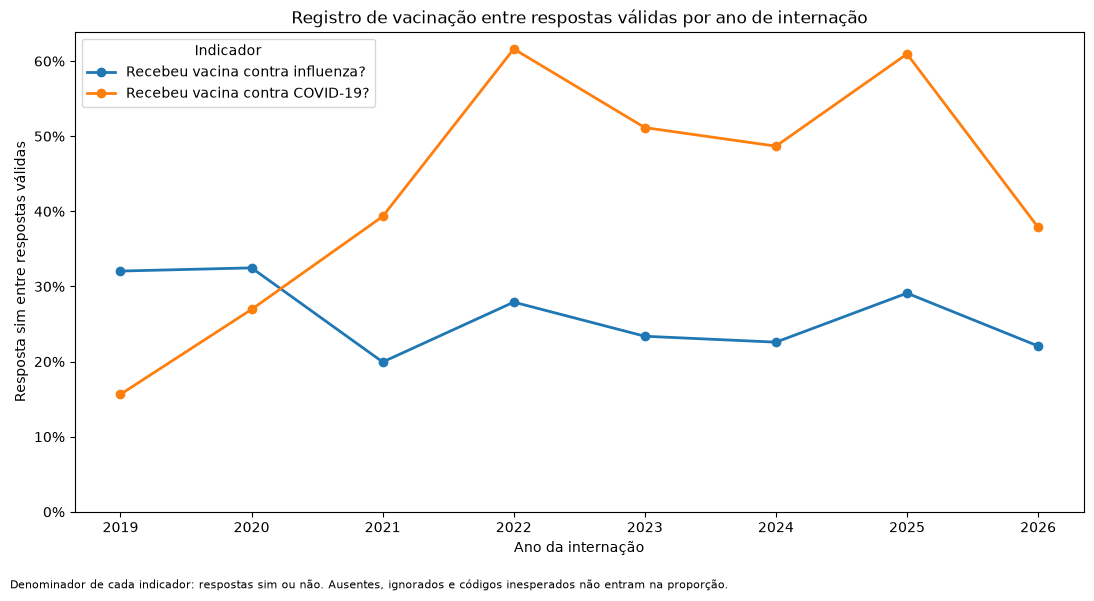

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_vacinacao_por_ano.png


In [49]:
figura_vacinacao, eixo_vacinacao = plt.subplots(
    figsize=(
        11,
        6,
    )
)

for coluna in COLUNAS_VACINACAO:
    dados_variavel = (
        vacinacao_por_ano.loc[
            vacinacao_por_ano[
                "coluna"
            ].eq(
                coluna
            )
        ]
        .sort_values(
            "ano_internacao"
        )
    )

    nome_variavel = (
        nomes_amigaveis_dicionario.get(
            coluna,
            coluna,
        )
    )

    eixo_vacinacao.plot(
        dados_variavel[
            "ano_internacao"
        ].astype(int),
        dados_variavel[
            "percentual_sim_validos"
        ],
        marker="o",
        linewidth=2,
        label=nome_variavel,
    )

anos_vacinacao = (
    vacinacao_por_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_vacinacao.set_title(
    "Registro de vacinação entre respostas válidas por ano de internação"
)

eixo_vacinacao.set_xlabel(
    "Ano da internação"
)

eixo_vacinacao.set_ylabel(
    "Resposta sim entre respostas válidas"
)

eixo_vacinacao.set_xticks(
    anos_vacinacao
)

eixo_vacinacao.set_ylim(
    bottom=0
)

eixo_vacinacao.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_vacinacao.legend(
    title="Indicador"
)

figura_vacinacao.text(
    0.01,
    0.01,
    (
        "Denominador de cada indicador: respostas sim ou não. "
        "Ausentes, ignorados e códigos inesperados não entram "
        "na proporção."
    ),
    fontsize=8,
)

figura_vacinacao.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_vacinacao.savefig(
    CAMINHO_FIGURA_VACINACAO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VACINACAO,
)

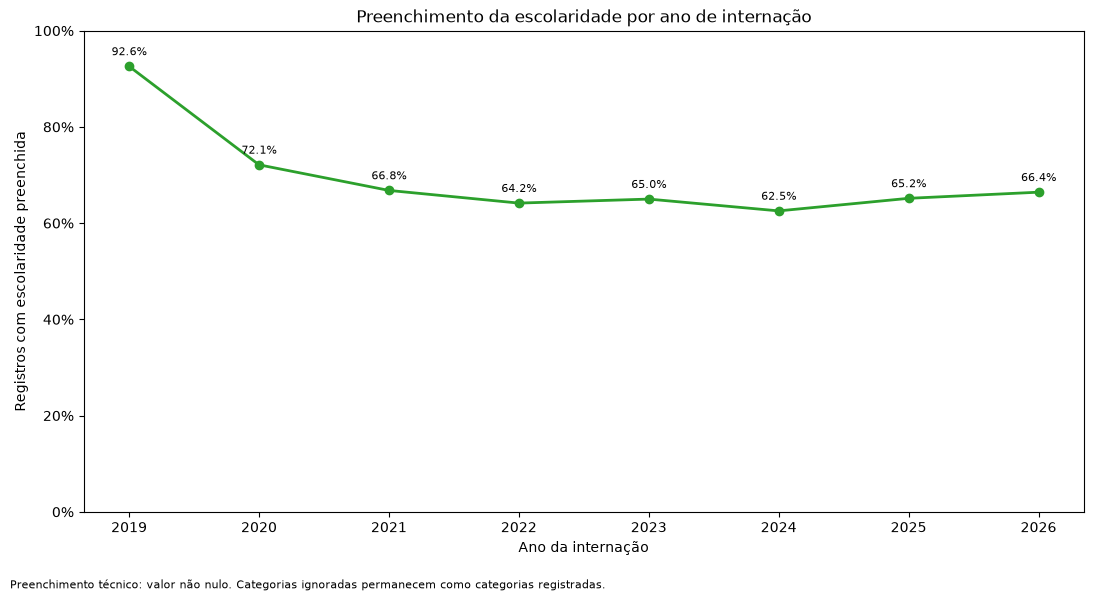

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_escolaridade_preenchimento_por_ano.png


In [50]:
figura_escolaridade, eixo_escolaridade = plt.subplots(
    figsize=(
        11,
        6,
    )
)

anos_escolaridade = (
    escolaridade_preenchimento_ano[
        "ano_internacao"
    ]
    .astype(int)
)

percentuais_escolaridade = (
    escolaridade_preenchimento_ano[
        "percentual_preenchido"
    ]
)

eixo_escolaridade.plot(
    anos_escolaridade,
    percentuais_escolaridade,
    color="tab:green",
    marker="o",
    linewidth=2,
)

eixo_escolaridade.set_title(
    "Preenchimento da escolaridade por ano de internação"
)

eixo_escolaridade.set_xlabel(
    "Ano da internação"
)

eixo_escolaridade.set_ylabel(
    "Registros com escolaridade preenchida"
)

eixo_escolaridade.set_xticks(
    anos_escolaridade
)

eixo_escolaridade.set_ylim(
    0,
    100,
)

eixo_escolaridade.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

for ano, percentual in zip(
    anos_escolaridade,
    percentuais_escolaridade,
):
    eixo_escolaridade.annotate(
        f"{percentual:.1f}%",
        (
            ano,
            percentual,
        ),
        textcoords="offset points",
        xytext=(
            0,
            8,
        ),
        ha="center",
        fontsize=8,
    )

figura_escolaridade.text(
    0.01,
    0.01,
    (
        "Preenchimento técnico: valor não nulo. "
        "Categorias ignoradas permanecem como categorias registradas."
    ),
    fontsize=8,
)

figura_escolaridade.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_escolaridade.savefig(
    CAMINHO_FIGURA_ESCOLARIDADE,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_ESCOLARIDADE,
)

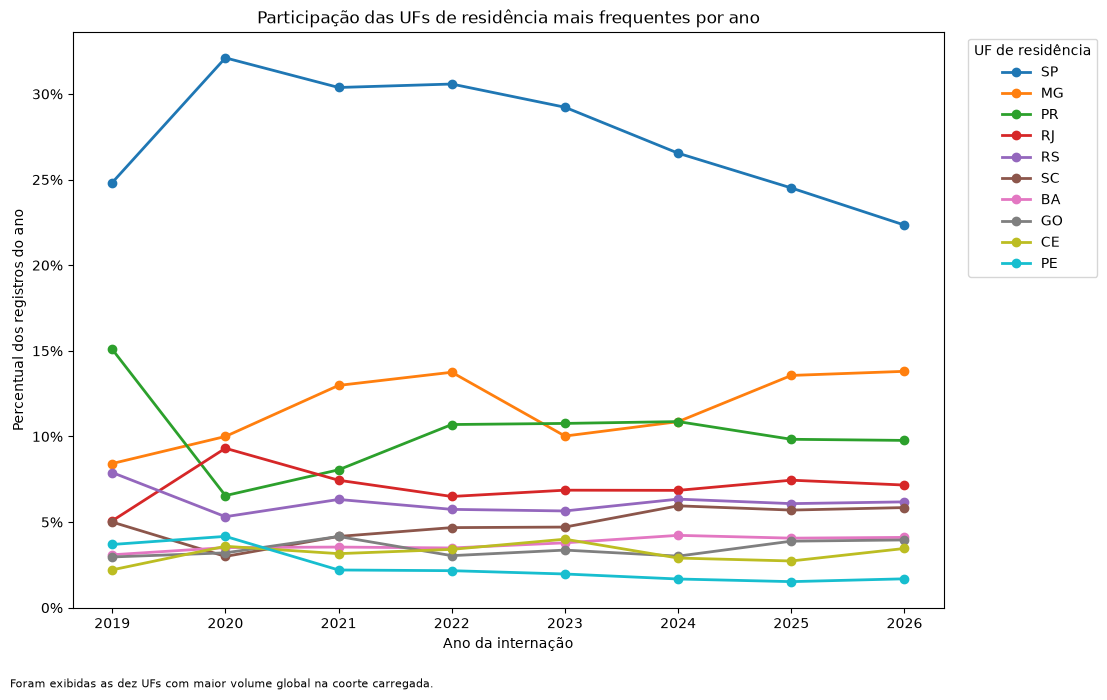

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_principais_uf_residencia.png


In [51]:
QUANTIDADE_UF_GRAFICO = 10

ufs_validas_resumo = (
    resumo_uf_residencia.loc[
        resumo_uf_residencia[
            "uf_residencia_categoria"
        ].ne(
            "Ausente ou inesperada"
        )
    ]
    .head(
        QUANTIDADE_UF_GRAFICO
    )
    .copy()
)

if ufs_validas_resumo.empty:
    raise ValueError(
        "Nenhuma UF válida foi encontrada para o gráfico."
    )

ufs_grafico = (
    ufs_validas_resumo[
        "uf_residencia_categoria"
    ]
    .tolist()
)

dados_uf_grafico = (
    uf_residencia_por_ano.loc[
        uf_residencia_por_ano[
            "uf_residencia_categoria"
        ].isin(
            ufs_grafico
        )
    ]
    .copy()
)

tabela_uf_grafico = (
    dados_uf_grafico.pivot(
        index="ano_internacao",
        columns="uf_residencia_categoria",
        values="percentual_ano",
    )
    .reindex(
        columns=ufs_grafico,
        fill_value=0,
    )
    .fillna(0)
)

figura_uf, eixo_uf = plt.subplots(
    figsize=(
        13,
        7,
    )
)

tabela_uf_grafico.plot(
    kind="line",
    marker="o",
    linewidth=2,
    ax=eixo_uf,
)

eixo_uf.set_title(
    "Participação das UFs de residência mais frequentes por ano"
)

eixo_uf.set_xlabel(
    "Ano da internação"
)

eixo_uf.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_uf.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_uf.legend(
    title="UF de residência",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

figura_uf.text(
    0.01,
    0.01,
    (
        "Foram exibidas as dez UFs com maior volume global "
        "na coorte carregada."
    ),
    fontsize=8,
)

figura_uf.tight_layout(
    rect=[
        0,
        0.04,
        0.86,
        1,
    ]
)

figura_uf.savefig(
    CAMINHO_FIGURA_UF,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_UF,
)

In [52]:
vacinacao_por_ano.to_csv(
    CAMINHO_VACINACAO_ANO,
    index=False,
    encoding="utf-8-sig",
)

escolaridade_por_ano.to_csv(
    CAMINHO_ESCOLARIDADE_ANO,
    index=False,
    encoding="utf-8-sig",
)

uf_residencia_por_ano.to_csv(
    CAMINHO_UF_RESIDENCIA_ANO,
    index=False,
    encoding="utf-8-sig",
)

resumo_uf_residencia.to_csv(
    CAMINHO_RESUMO_UF,
    index=False,
    encoding="utf-8-sig",
)

total_escolaridade = int(
    escolaridade_por_ano[
        "quantidade"
    ]
    .sum()
)

total_uf = int(
    uf_residencia_por_ano[
        "quantidade"
    ]
    .sum()
)

anos_contexto_observados = int(
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

linhas_vacinacao_esperadas = (
    len(
        COLUNAS_VACINACAO
    )
    * anos_contexto_observados
)

categorias_vacinacao_somam_total = (
    vacinacao_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        vacinacao_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

percentuais_vacinacao_validos = (
    vacinacao_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_escolaridade_validos = (
    escolaridade_por_ano[
        "percentual_ano"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_uf_validos = (
    uf_residencia_por_ano[
        "percentual_ano"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

verificacoes_contexto = {
    "vacinacao_por_ano_nao_vazia": (
        not vacinacao_por_ano.empty
    ),
    "escolaridade_por_ano_nao_vazia": (
        not escolaridade_por_ano.empty
    ),
    "uf_por_ano_nao_vazia": (
        not uf_residencia_por_ano.empty
    ),
    "uma_linha_por_vacina_e_ano": (
        len(
            vacinacao_por_ano
        )
        == linhas_vacinacao_esperadas
    ),
    "categorias_vacinacao_somam_total": (
        categorias_vacinacao_somam_total
    ),
    "total_escolaridade_igual_coorte": (
        total_escolaridade
        == len(
            coorte
        )
    ),
    "total_uf_igual_coorte": (
        total_uf
        == len(
            coorte
        )
    ),
    "percentuais_vacinacao_validos": (
        percentuais_vacinacao_validos
    ),
    "percentuais_escolaridade_validos": (
        percentuais_escolaridade_validos
    ),
    "percentuais_uf_validos": (
        percentuais_uf_validos
    ),
    "arquivo_vacinacao_criado": (
        CAMINHO_VACINACAO_ANO.exists()
    ),
    "arquivo_escolaridade_criado": (
        CAMINHO_ESCOLARIDADE_ANO.exists()
    ),
    "arquivo_uf_criado": (
        CAMINHO_UF_RESIDENCIA_ANO.exists()
    ),
    "arquivo_resumo_uf_criado": (
        CAMINHO_RESUMO_UF.exists()
    ),
    "figura_vacinacao_criada": (
        CAMINHO_FIGURA_VACINACAO.exists()
    ),
    "figura_escolaridade_criada": (
        CAMINHO_FIGURA_ESCOLARIDADE.exists()
    ),
    "figura_uf_criada": (
        CAMINHO_FIGURA_UF.exists()
    ),
}

verificacoes_contexto_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_contexto.keys()
        ),
        "resultado": list(
            verificacoes_contexto.values()
        ),
    }
)

display(
    verificacoes_contexto_df
)

if not all(
    verificacoes_contexto.values()
):
    falhas_contexto = [
        verificacao
        for verificacao, resultado
        in verificacoes_contexto.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de vacinação, escolaridade e geografia "
        "terminou com falhas: "
        f"{falhas_contexto}"
    )

print(
    "Análise de vacinação, escolaridade e geografia "
    "validada com sucesso."
)

,verificacao,resultado
0,vacinacao_por_ano_nao_vazia,True
1,escolaridade_por_ano_nao_vazia,True
2,uf_por_ano_nao_vazia,True
3,uma_linha_por_vacina_e_ano,True
4,categorias_vacinacao_somam_total,True
5,total_escolaridade_igual_coorte,True
6,total_uf_igual_coorte,True
7,percentuais_vacinacao_validos,True
8,percentuais_escolaridade_validos,True
9,percentuais_uf_validos,True


Análise de vacinação, escolaridade e geografia validada com sucesso.


In [53]:
ANO_INICIAL_TRIAGEM_TEMPORAL = 2019
ANO_FINAL_TRIAGEM_TEMPORAL = 2025

ANOS_TRIAGEM_TEMPORAL = list(
    range(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL + 1,
    )
)

CAMINHO_RUPTURAS_TEMPORAIS = (
    C.TABLES_DIR
    / "04_eda_rupturas_temporais.csv"
)

CAMINHO_RESUMO_RUPTURAS = (
    C.TABLES_DIR
    / "04_eda_resumo_rupturas_temporais.csv"
)

CAMINHO_FIGURA_RUPTURAS = (
    C.FIGURES_DIR
    / "04_eda_rupturas_temporais.png"
)

print(
    "Período utilizado na triagem temporal:",
    ANO_INICIAL_TRIAGEM_TEMPORAL,
    "a",
    ANO_FINAL_TRIAGEM_TEMPORAL,
)

print(
    "Tabela de rupturas:",
    CAMINHO_RUPTURAS_TEMPORAIS,
)

print(
    "Resumo de rupturas:",
    CAMINHO_RESUMO_RUPTURAS,
)

Período utilizado na triagem temporal: 2019 a 2025
Tabela de rupturas: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_rupturas_temporais.csv
Resumo de rupturas: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_resumo_rupturas_temporais.csv


In [54]:
def resumir_amplitude_temporal(
    dataframe: pd.DataFrame,
    coluna_indicador: str,
    coluna_valor: str,
    tipo_indicador: str,
    grupo_indicador: str,
    unidade: str,
    limite_destaque: float,
) -> pd.DataFrame:
    """Calcula mínimo, máximo e amplitude do indicador entre 2019 e 2025."""

    COLUNAS_OBRIGATORIAS = [
        "ano_internacao",
        coluna_indicador,
        coluna_valor,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_OBRIGATORIAS
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_periodo = (
        dataframe.loc[
            dataframe[
                "ano_internacao"
            ].isin(
                ANOS_TRIAGEM_TEMPORAL
            ),
            COLUNAS_OBRIGATORIAS,
        ]
        .copy()
    )

    dados_periodo[
        coluna_valor
    ] = pd.to_numeric(
        dados_periodo[
            coluna_valor
        ],
        errors="coerce",
    )

    dados_periodo = (
        dados_periodo.dropna(
            subset=[
                coluna_indicador,
                coluna_valor,
            ]
        )
    )

    if dados_periodo.empty:
        return pd.DataFrame(
            columns=[
                "tipo_indicador",
                "grupo_indicador",
                "indicador",
                "unidade",
                "ano_minimo",
                "valor_minimo",
                "ano_maximo",
                "valor_maximo",
                "amplitude",
                "limite_destaque",
                "flag_destaque",
                "quantidade_anos",
            ]
        )

    registros_resumo = []

    indicadores = (
        dados_periodo[
            coluna_indicador
        ]
        .drop_duplicates()
        .tolist()
    )

    for indicador in indicadores:
        dados_indicador = (
            dados_periodo.loc[
                dados_periodo[
                    coluna_indicador
                ].eq(
                    indicador
                )
            ]
            .sort_values(
                "ano_internacao"
            )
            .copy()
        )

        if dados_indicador.empty:
            continue

        indice_minimo = (
            dados_indicador[
                coluna_valor
            ]
            .idxmin()
        )

        indice_maximo = (
            dados_indicador[
                coluna_valor
            ]
            .idxmax()
        )

        valor_minimo = float(
            dados_indicador.loc[
                indice_minimo,
                coluna_valor,
            ]
        )

        valor_maximo = float(
            dados_indicador.loc[
                indice_maximo,
                coluna_valor,
            ]
        )

        ano_minimo = int(
            dados_indicador.loc[
                indice_minimo,
                "ano_internacao",
            ]
        )

        ano_maximo = int(
            dados_indicador.loc[
                indice_maximo,
                "ano_internacao",
            ]
        )

        amplitude = (
            valor_maximo
            - valor_minimo
        )

        registros_resumo.append(
            {
                "tipo_indicador": tipo_indicador,
                "grupo_indicador": grupo_indicador,
                "indicador": str(
                    indicador
                ),
                "unidade": unidade,
                "ano_minimo": ano_minimo,
                "valor_minimo": valor_minimo,
                "ano_maximo": ano_maximo,
                "valor_maximo": valor_maximo,
                "amplitude": amplitude,
                "limite_destaque": (
                    limite_destaque
                ),
                "flag_destaque": (
                    amplitude
                    >= limite_destaque
                ),
                "quantidade_anos": int(
                    dados_indicador[
                        "ano_internacao"
                    ]
                    .nunique()
                ),
            }
        )

    resultado = pd.DataFrame(
        registros_resumo
    )

    resultado = (
        resultado.sort_values(
            [
                "flag_destaque",
                "amplitude",
                "indicador",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    return resultado

In [55]:
volume_triagem = (
    resumo_temporal.loc[
        resumo_temporal[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "quantidade_registros",
        ],
    ]
    .copy()
)

total_volume_triagem = int(
    volume_triagem[
        "quantidade_registros"
    ]
    .sum()
)

if total_volume_triagem == 0:
    raise ValueError(
        "O período de triagem temporal não possui registros."
    )

volume_triagem[
    "percentual_periodo"
] = (
    volume_triagem[
        "quantidade_registros"
    ]
    .div(
        total_volume_triagem
    )
    .mul(100)
)

volume_triagem[
    "indicador"
] = (
    "Participação no volume do período"
)

desfecho_triagem = (
    alvo_por_ano.loc[
        alvo_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "percentual_obito_srag",
        ],
    ]
    .copy()
)

desfecho_triagem[
    "indicador"
] = (
    "Óbito por SRAG"
)

idade_triagem = (
    idade_por_ano.loc[
        idade_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "idade_mediana",
        ],
    ]
    .copy()
)

idade_triagem[
    "indicador"
] = (
    "Idade mediana"
)

display(
    volume_triagem
)

display(
    desfecho_triagem
)

display(
    idade_triagem
)

,ano_internacao,quantidade_registros,percentual_periodo,indicador
0,2019,43392,1.169349,Participação no volume do período
1,2020,974415,26.259013,Participação no volume do período
2,2021,1471091,39.643682,Participação no volume do período
3,2022,470323,12.674495,Participação no volume do período
4,2023,237976,6.413094,Participação no volume do período
5,2024,226749,6.110543,Participação no volume do período
6,2025,286837,7.729824,Participação no volume do período


alvo_obito_srag,ano_internacao,percentual_obito_srag,indicador
0,2019,11.997603,Óbito por SRAG
1,2020,27.924857,Óbito por SRAG
2,2021,28.138300,Óbito por SRAG
3,2022,18.083530,Óbito por SRAG
4,2023,9.445490,Óbito por SRAG
5,2024,8.215692,Óbito por SRAG
6,2025,7.244184,Óbito por SRAG


,ano_internacao,idade_mediana,indicador
0,2019,5.0,Idade mediana
1,2020,60.0,Idade mediana
2,2021,56.0,Idade mediana
3,2022,58.0,Idade mediana
4,2023,7.0,Idade mediana
5,2024,6.0,Idade mediana
6,2025,5.0,Idade mediana


In [56]:
ruptura_volume = (
    resumir_amplitude_temporal(
        dataframe=volume_triagem,
        coluna_indicador="indicador",
        coluna_valor="percentual_periodo",
        tipo_indicador="composicao",
        grupo_indicador="volume",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

ruptura_desfecho = (
    resumir_amplitude_temporal(
        dataframe=desfecho_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_obito_srag"
        ),
        tipo_indicador="desfecho",
        grupo_indicador="desfecho",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

ruptura_idade = (
    resumir_amplitude_temporal(
        dataframe=idade_triagem,
        coluna_indicador="indicador",
        coluna_valor="idade_mediana",
        tipo_indicador="demografia",
        grupo_indicador="idade",
        unidade="anos",
        limite_destaque=5.0,
    )
)

display(
    ruptura_volume
)

display(
    ruptura_desfecho
)

display(
    ruptura_idade
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,composicao,volume,Participação no volume do período,pontos_percentuais,2019,1.169349,2021,39.643682,38.474333,5.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,desfecho,desfecho,Óbito por SRAG,pontos_percentuais,2025,7.244184,2021,28.1383,20.894116,5.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,demografia,idade,Idade mediana,anos,2019,5.0,2020,60.0,55.0,5.0,True,7


In [57]:
preenchimento_triagem = (
    preenchimento_por_variavel_ano.loc[
        preenchimento_por_variavel_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "grupo",
            "percentual_preenchido",
        ],
    ]
    .copy()
)

preenchimento_triagem[
    "indicador"
] = (
    preenchimento_triagem[
        "nome_amigavel"
    ]
    .where(
        preenchimento_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        preenchimento_triagem[
            "coluna"
        ],
    )
)

ruptura_preenchimento = (
    resumir_amplitude_temporal(
        dataframe=preenchimento_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_preenchido"
        ),
        tipo_indicador="qualidade_dados",
        grupo_indicador="preenchimento",
        unidade="pontos_percentuais",
        limite_destaque=20.0,
    )
)

display(
    ruptura_preenchimento.head(30)
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,qualidade_dados,preenchimento,Recebeu vacina contra COVID-19?,pontos_percentuais,2019,1.338956,2025,99.993725,98.654768,20.0,True,7
1,qualidade_dados,preenchimento,Fadiga,pontos_percentuais,2019,0.523138,2025,82.583140,82.060002,20.0,True,7
2,qualidade_dados,preenchimento,Dor abdominal,pontos_percentuais,2019,0.274244,2025,81.050562,80.776318,20.0,True,7
3,qualidade_dados,preenchimento,Perda do olfato,pontos_percentuais,2019,0.269635,2025,80.455799,80.186164,20.0,True,7
4,qualidade_dados,preenchimento,Perda do paladar,pontos_percentuais,2019,0.267330,2025,80.336567,80.069237,20.0,True,7
5,qualidade_dados,preenchimento,Recebeu vacina contra influenza?,pontos_percentuais,2023,56.119945,2025,94.208906,38.088961,20.0,True,7
6,qualidade_dados,preenchimento,Escolaridade,pontos_percentuais,2024,62.544488,2019,92.593105,30.048617,20.0,True,7
7,qualidade_dados,preenchimento,Diarreia,pontos_percentuais,2022,68.500158,2019,97.607854,29.107696,20.0,True,7
8,qualidade_dados,preenchimento,Vomito,pontos_percentuais,2022,69.104211,2019,97.693123,28.588912,20.0,True,7
9,qualidade_dados,preenchimento,Dor de garganta,pontos_percentuais,2022,70.390136,2019,98.041114,27.650977,20.0,True,7


In [58]:
sintomas_triagem = (
    sintomas_por_ano.loc[
        sintomas_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

sintomas_triagem[
    "indicador"
] = (
    sintomas_triagem[
        "nome_amigavel"
    ]
    .where(
        sintomas_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        sintomas_triagem[
            "coluna"
        ],
    )
)

comorbidades_triagem = (
    comorbidades_por_ano.loc[
        comorbidades_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

comorbidades_triagem[
    "indicador"
] = (
    comorbidades_triagem[
        "nome_amigavel"
    ]
    .where(
        comorbidades_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        comorbidades_triagem[
            "coluna"
        ],
    )
)

ruptura_sintomas = (
    resumir_amplitude_temporal(
        dataframe=sintomas_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="clinico",
        grupo_indicador="sintomas",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

ruptura_comorbidades = (
    resumir_amplitude_temporal(
        dataframe=comorbidades_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="clinico",
        grupo_indicador="comorbidades",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

display(
    ruptura_sintomas
)

display(
    ruptura_comorbidades
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,clinico,sintomas,Fadiga,pontos_percentuais,2024,21.304499,2019,50.660793,29.356294,10.0,True,7
1,clinico,sintomas,Febre,pontos_percentuais,2022,61.496012,2019,88.735499,27.239487,10.0,True,7
2,clinico,sintomas,Desconforto respiratorio,pontos_percentuais,2022,64.007919,2019,85.090281,21.082361,10.0,True,7
3,clinico,sintomas,Apresentou outros sintomas?,pontos_percentuais,2019,25.142604,2021,46.125307,20.982703,10.0,True,7
4,clinico,sintomas,Tosse,pontos_percentuais,2020,76.130208,2019,93.388871,17.258662,10.0,True,7
5,clinico,sintomas,Saturacao de oxigenio abaixo de 95%?,pontos_percentuais,2025,62.081116,2021,77.043969,14.962853,10.0,True,7
6,clinico,sintomas,Perda do paladar,pontos_percentuais,2019,0.869565,2021,13.097523,12.227958,10.0,True,7
7,clinico,sintomas,Perda do olfato,pontos_percentuais,2019,0.869565,2021,12.842341,11.972776,10.0,True,7
8,clinico,sintomas,Dispneia,pontos_percentuais,2022,72.688406,2019,83.651963,10.963557,10.0,True,7
9,clinico,sintomas,Dor de garganta,pontos_percentuais,2025,13.372231,2021,23.293317,9.921086,10.0,False,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,clinico,comorbidades,Doenca cardiovascular cronica,pontos_percentuais,2019,27.887022,2021,62.538807,34.651785,10.0,True,7
1,clinico,comorbidades,Diabetes mellitus,pontos_percentuais,2019,19.549913,2020,46.408440,26.858528,10.0,True,7
2,clinico,comorbidades,Obesidade,pontos_percentuais,2019,4.112634,2021,22.640659,18.528025,10.0,True,7
3,clinico,comorbidades,Asma,pontos_percentuais,2021,8.815523,2023,22.982738,14.167215,10.0,True,7
4,clinico,comorbidades,Outro fator de risco?,pontos_percentuais,2019,47.272506,2022,59.841626,12.569119,10.0,True,7
5,clinico,comorbidades,Outra pneumopatia cronica,pontos_percentuais,2021,9.034147,2019,18.084402,9.050255,10.0,False,7
6,clinico,comorbidades,Doenca neurologica cronica,pontos_percentuais,2021,9.221022,2022,16.781076,7.560054,10.0,False,7
7,clinico,comorbidades,Doenca renal cronica,pontos_percentuais,2019,5.943627,2022,10.640829,4.697201,10.0,False,7
8,clinico,comorbidades,Imunodeficiencia ou imunodepressao,pontos_percentuais,2021,5.863559,2019,10.196031,4.332472,10.0,False,7
9,clinico,comorbidades,Sindrome de Down,pontos_percentuais,2020,0.724400,2019,3.731976,3.007577,10.0,False,7


In [59]:
vacinacao_triagem = (
    vacinacao_por_ano.loc[
        vacinacao_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

vacinacao_triagem[
    "indicador"
] = (
    vacinacao_triagem[
        "nome_amigavel"
    ]
    .where(
        vacinacao_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        vacinacao_triagem[
            "coluna"
        ],
    )
)

escolaridade_triagem = (
    escolaridade_preenchimento_ano.loc[
        escolaridade_preenchimento_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "percentual_preenchido",
        ],
    ]
    .copy()
)

escolaridade_triagem[
    "indicador"
] = (
    "Preenchimento da escolaridade"
)

ruptura_vacinacao = (
    resumir_amplitude_temporal(
        dataframe=vacinacao_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="contexto",
        grupo_indicador="vacinacao",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

ruptura_escolaridade = (
    resumir_amplitude_temporal(
        dataframe=escolaridade_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_preenchido"
        ),
        tipo_indicador="qualidade_dados",
        grupo_indicador="escolaridade",
        unidade="pontos_percentuais",
        limite_destaque=20.0,
    )
)

display(
    ruptura_vacinacao
)

display(
    ruptura_escolaridade
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,contexto,vacinacao,Recebeu vacina contra COVID-19?,pontos_percentuais,2019,15.644172,2022,61.623424,45.979252,10.0,True,7
1,contexto,vacinacao,Recebeu vacina contra influenza?,pontos_percentuais,2021,19.946312,2020,32.477324,12.531013,10.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,qualidade_dados,escolaridade,Preenchimento da escolaridade,pontos_percentuais,2024,62.544488,2019,92.593105,30.048617,20.0,True,7


In [60]:
ufs_triagem = (
    resumo_uf_residencia.loc[
        resumo_uf_residencia[
            "uf_residencia_categoria"
        ].ne(
            "Ausente ou inesperada"
        )
    ]
    .head(10)[
        "uf_residencia_categoria"
    ]
    .tolist()
)

uf_triagem = (
    uf_residencia_por_ano.loc[
        uf_residencia_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        )
        & uf_residencia_por_ano[
            "uf_residencia_categoria"
        ].isin(
            ufs_triagem
        ),
        [
            "ano_internacao",
            "uf_residencia_categoria",
            "percentual_ano",
        ],
    ]
    .copy()
)

uf_triagem = (
    pd.MultiIndex.from_product(
        [
            ANOS_TRIAGEM_TEMPORAL,
            ufs_triagem,
        ],
        names=[
            "ano_internacao",
            "uf_residencia_categoria",
        ],
    )
    .to_frame(
        index=False
    )
    .merge(
        uf_triagem,
        on=[
            "ano_internacao",
            "uf_residencia_categoria",
        ],
        how="left",
        validate="one_to_one",
    )
)

uf_triagem[
    "percentual_ano"
] = (
    uf_triagem[
        "percentual_ano"
    ]
    .fillna(0)
)

uf_triagem[
    "indicador"
] = (
    "UF "
    + uf_triagem[
        "uf_residencia_categoria"
    ]
    .astype("string")
)

ruptura_uf = (
    resumir_amplitude_temporal(
        dataframe=uf_triagem,
        coluna_indicador="indicador",
        coluna_valor="percentual_ano",
        tipo_indicador="territorio",
        grupo_indicador="uf_residencia",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

display(
    ruptura_uf
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,territorio,uf_residencia,UF PR,pontos_percentuais,2020,6.545568,2019,15.090339,8.544771,5.0,True,7
1,territorio,uf_residencia,UF SP,pontos_percentuais,2025,24.511134,2020,32.109009,7.597875,5.0,True,7
2,territorio,uf_residencia,UF MG,pontos_percentuais,2019,8.418603,2022,13.749487,5.330885,5.0,True,7
3,territorio,uf_residencia,UF RJ,pontos_percentuais,2019,5.074668,2020,9.311023,4.236354,5.0,False,7
4,territorio,uf_residencia,UF SC,pontos_percentuais,2020,2.995233,2024,5.949310,2.954077,5.0,False,7
5,territorio,uf_residencia,UF PE,pontos_percentuais,2025,1.522119,2020,4.165474,2.643355,5.0,False,7
6,territorio,uf_residencia,UF RS,pontos_percentuais,2020,5.313855,2019,7.893160,2.579305,5.0,False,7
7,territorio,uf_residencia,UF CE,pontos_percentuais,2019,2.210085,2023,4.000824,1.790739,5.0,False,7
8,territorio,uf_residencia,UF GO,pontos_percentuais,2019,2.963680,2021,4.159158,1.195478,5.0,False,7
9,territorio,uf_residencia,UF BA,pontos_percentuais,2019,3.090431,2024,4.225377,1.134946,5.0,False,7


In [61]:
TABELAS_RUPTURAS = [
    ruptura_volume,
    ruptura_desfecho,
    ruptura_idade,
    ruptura_preenchimento,
    ruptura_sintomas,
    ruptura_comorbidades,
    ruptura_vacinacao,
    ruptura_escolaridade,
    ruptura_uf,
]

rupturas_temporais = (
    pd.concat(
        TABELAS_RUPTURAS,
        ignore_index=True,
    )
)

rupturas_temporais[
    "periodo_avaliado"
] = (
    f"{ANO_INICIAL_TRIAGEM_TEMPORAL}-"
    f"{ANO_FINAL_TRIAGEM_TEMPORAL}"
)

rupturas_temporais[
    "ordem_destaque"
] = (
    rupturas_temporais[
        "amplitude"
    ]
    .div(
        rupturas_temporais[
            "limite_destaque"
        ]
    )
)

COLUNAS_RUPTURAS_TEMPORAIS = [
    "tipo_indicador",
    "grupo_indicador",
    "indicador",
    "unidade",
    "periodo_avaliado",
    "ano_minimo",
    "valor_minimo",
    "ano_maximo",
    "valor_maximo",
    "amplitude",
    "limite_destaque",
    "flag_destaque",
    "ordem_destaque",
    "quantidade_anos",
]

rupturas_temporais = (
    rupturas_temporais[
        COLUNAS_RUPTURAS_TEMPORAIS
    ]
    .sort_values(
        [
            "flag_destaque",
            "ordem_destaque",
            "grupo_indicador",
            "indicador",
        ],
        ascending=[
            False,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    rupturas_temporais.head(40)
)

,tipo_indicador,grupo_indicador,indicador,unidade,periodo_avaliado,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,ordem_destaque,quantidade_anos
0,demografia,idade,Idade mediana,anos,2019-2025,2019,5.000000,2020,60.000000,55.000000,5.0,True,11.000000,7
1,composicao,volume,Participação no volume do período,pontos_percentuais,2019-2025,2019,1.169349,2021,39.643682,38.474333,5.0,True,7.694867,7
2,qualidade_dados,preenchimento,Recebeu vacina contra COVID-19?,pontos_percentuais,2019-2025,2019,1.338956,2025,99.993725,98.654768,20.0,True,4.932738,7
3,contexto,vacinacao,Recebeu vacina contra COVID-19?,pontos_percentuais,2019-2025,2019,15.644172,2022,61.623424,45.979252,10.0,True,4.597925,7
4,desfecho,desfecho,Óbito por SRAG,pontos_percentuais,2019-2025,2025,7.244184,2021,28.138300,20.894116,5.0,True,4.178823,7
5,qualidade_dados,preenchimento,Fadiga,pontos_percentuais,2019-2025,2019,0.523138,2025,82.583140,82.060002,20.0,True,4.103000,7
6,qualidade_dados,preenchimento,Dor abdominal,pontos_percentuais,2019-2025,2019,0.274244,2025,81.050562,80.776318,20.0,True,4.038816,7
7,qualidade_dados,preenchimento,Perda do olfato,pontos_percentuais,2019-2025,2019,0.269635,2025,80.455799,80.186164,20.0,True,4.009308,7
8,qualidade_dados,preenchimento,Perda do paladar,pontos_percentuais,2019-2025,2019,0.267330,2025,80.336567,80.069237,20.0,True,4.003462,7
9,clinico,comorbidades,Doenca cardiovascular cronica,pontos_percentuais,2019-2025,2019,27.887022,2021,62.538807,34.651785,10.0,True,3.465179,7


In [62]:
resumo_rupturas_temporais = (
    rupturas_temporais.groupby(
        [
            "tipo_indicador",
            "grupo_indicador",
        ],
        dropna=False,
    )
    .agg(
        quantidade_indicadores=(
            "indicador",
            "size",
        ),
        quantidade_destaques=(
            "flag_destaque",
            "sum",
        ),
        maior_amplitude=(
            "amplitude",
            "max",
        ),
        amplitude_mediana=(
            "amplitude",
            "median",
        ),
    )
    .reset_index()
)

resumo_rupturas_temporais[
    "percentual_indicadores_destacados"
] = (
    resumo_rupturas_temporais[
        "quantidade_destaques"
    ]
    .div(
        resumo_rupturas_temporais[
            "quantidade_indicadores"
        ]
    )
    .mul(100)
)

resumo_rupturas_temporais = (
    resumo_rupturas_temporais
    .sort_values(
        [
            "quantidade_destaques",
            "maior_amplitude",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    resumo_rupturas_temporais
)

,tipo_indicador,grupo_indicador,quantidade_indicadores,quantidade_destaques,maior_amplitude,amplitude_mediana,percentual_indicadores_destacados
0,qualidade_dados,preenchimento,40,12,98.654768,14.153519,30.000000
1,clinico,sintomas,13,9,29.356294,12.227958,69.230769
2,clinico,comorbidades,13,5,34.651785,7.560054,38.461538
3,territorio,uf_residencia,10,3,8.544771,2.798716,30.000000
4,contexto,vacinacao,2,2,45.979252,29.255133,100.000000
5,demografia,idade,1,1,55.000000,55.000000,100.000000
6,composicao,volume,1,1,38.474333,38.474333,100.000000
7,qualidade_dados,escolaridade,1,1,30.048617,30.048617,100.000000
8,desfecho,desfecho,1,1,20.894116,20.894116,100.000000


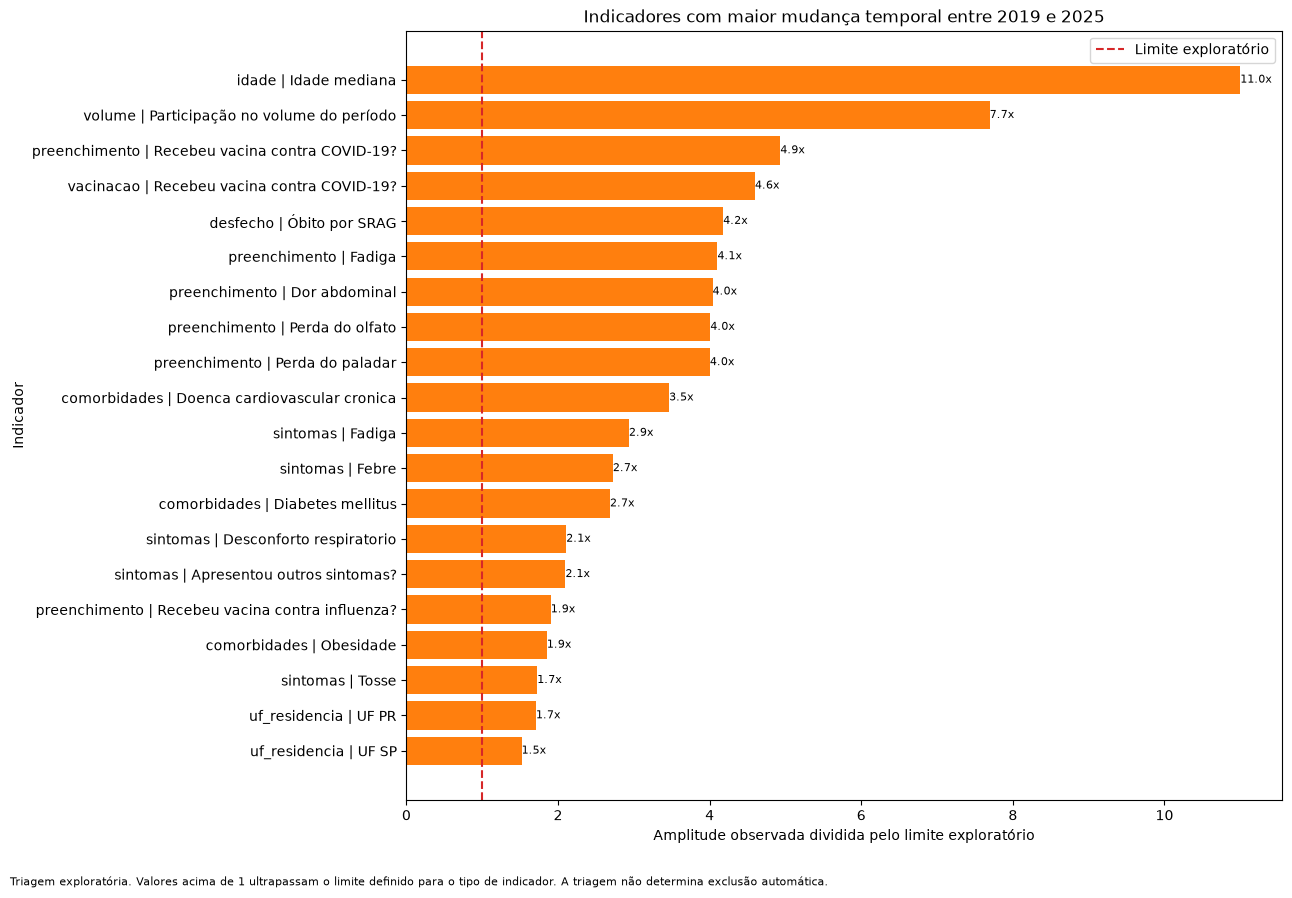

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_rupturas_temporais.png


In [63]:
QUANTIDADE_DESTAQUES_GRAFICO = 20

rupturas_para_grafico = (
    rupturas_temporais.loc[
        rupturas_temporais[
            "flag_destaque"
        ]
    ]
    .head(
        QUANTIDADE_DESTAQUES_GRAFICO
    )
    .copy()
)

if rupturas_para_grafico.empty:
    print(
        "Nenhum indicador ultrapassou os limites "
        "exploratórios definidos."
    )
else:
    rupturas_para_grafico[
        "rotulo_grafico"
    ] = (
        rupturas_para_grafico[
            "grupo_indicador"
        ]
        .astype("string")
        + " | "
        + rupturas_para_grafico[
            "indicador"
        ]
        .astype("string")
    )

    rupturas_para_grafico = (
        rupturas_para_grafico
        .sort_values(
            "ordem_destaque",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    figura_rupturas, eixo_rupturas = plt.subplots(
        figsize=(
            13,
            9,
        )
    )

    barras_rupturas = eixo_rupturas.barh(
        rupturas_para_grafico[
            "rotulo_grafico"
        ],
        rupturas_para_grafico[
            "ordem_destaque"
        ],
        color="tab:orange",
    )

    eixo_rupturas.axvline(
        x=1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label="Limite exploratório",
    )

    eixo_rupturas.set_title(
        "Indicadores com maior mudança temporal entre 2019 e 2025"
    )

    eixo_rupturas.set_xlabel(
        "Amplitude observada dividida pelo limite exploratório"
    )

    eixo_rupturas.set_ylabel(
        "Indicador"
    )

    eixo_rupturas.legend()

    for barra, valor in zip(
        barras_rupturas,
        rupturas_para_grafico[
            "ordem_destaque"
        ],
    ):
        eixo_rupturas.text(
            barra.get_width(),
            barra.get_y()
            + barra.get_height()
            / 2,
            f"{valor:.1f}x",
            va="center",
            ha="left",
            fontsize=8,
        )

    figura_rupturas.text(
        0.01,
        0.01,
        (
            "Triagem exploratória. Valores acima de 1 ultrapassam "
            "o limite definido para o tipo de indicador. "
            "A triagem não determina exclusão automática."
        ),
        fontsize=8,
    )

    figura_rupturas.tight_layout(
        rect=[
            0,
            0.04,
            1,
            1,
        ]
    )

    figura_rupturas.savefig(
        CAMINHO_FIGURA_RUPTURAS,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        CAMINHO_FIGURA_RUPTURAS,
    )

In [64]:
rupturas_temporais.to_csv(
    CAMINHO_RUPTURAS_TEMPORAIS,
    index=False,
    encoding="utf-8-sig",
)

resumo_rupturas_temporais.to_csv(
    CAMINHO_RESUMO_RUPTURAS,
    index=False,
    encoding="utf-8-sig",
)

grupos_esperados_rupturas = {
    "volume",
    "desfecho",
    "idade",
    "preenchimento",
    "sintomas",
    "comorbidades",
    "vacinacao",
    "escolaridade",
    "uf_residencia",
}

grupos_observados_rupturas = set(
    rupturas_temporais[
        "grupo_indicador"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

amplitudes_validas = (
    rupturas_temporais[
        "amplitude"
    ]
    .dropna()
    .ge(0)
    .all()
)

anos_minimos_validos = (
    rupturas_temporais[
        "ano_minimo"
    ]
    .dropna()
    .between(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL,
        inclusive="both",
    )
    .all()
)

anos_maximos_validos = (
    rupturas_temporais[
        "ano_maximo"
    ]
    .dropna()
    .between(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL,
        inclusive="both",
    )
    .all()
)

figura_rupturas_necessaria = (
    rupturas_temporais[
        "flag_destaque"
    ]
    .any()
)

if figura_rupturas_necessaria:
    figura_rupturas_valida = (
        CAMINHO_FIGURA_RUPTURAS.exists()
    )
else:
    figura_rupturas_valida = True

verificacoes_rupturas = {
    "tabela_rupturas_nao_vazia": (
        not rupturas_temporais.empty
    ),
    "resumo_rupturas_nao_vazio": (
        not resumo_rupturas_temporais.empty
    ),
    "todos_grupos_esperados_presentes": (
        grupos_esperados_rupturas
        .issubset(
            grupos_observados_rupturas
        )
    ),
    "amplitudes_nao_negativas": (
        amplitudes_validas
    ),
    "anos_minimos_dentro_periodo": (
        anos_minimos_validos
    ),
    "anos_maximos_dentro_periodo": (
        anos_maximos_validos
    ),
    "arquivo_rupturas_criado": (
        CAMINHO_RUPTURAS_TEMPORAIS.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_RUPTURAS.exists()
    ),
    "figura_rupturas_valida": (
        figura_rupturas_valida
    ),
}

verificacoes_rupturas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_rupturas.keys()
        ),
        "resultado": list(
            verificacoes_rupturas.values()
        ),
    }
)

display(
    verificacoes_rupturas_df
)

if not all(
    verificacoes_rupturas.values()
):
    falhas_rupturas = [
        verificacao
        for verificacao, resultado
        in verificacoes_rupturas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A consolidação temporal terminou com falhas: "
        f"{falhas_rupturas}"
    )

print(
    "Consolidação das mudanças temporais validada com sucesso."
)

,verificacao,resultado
0,tabela_rupturas_nao_vazia,True
1,resumo_rupturas_nao_vazio,True
2,todos_grupos_esperados_presentes,True
3,amplitudes_nao_negativas,True
4,anos_minimos_dentro_periodo,True
5,anos_maximos_dentro_periodo,True
6,arquivo_rupturas_criado,True
7,arquivo_resumo_criado,True
8,figura_rupturas_valida,True


Consolidação das mudanças temporais validada com sucesso.


In [65]:

import gc
import time

t0_base_desfecho = time.perf_counter()

COLUNAS_FIXAS_DESFECHO = [
    "ano_internacao",
    "alvo_obito_srag",
    "faixa_etaria",
    "sexo_categoria",
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

COLUNAS_ANALISE_DESFECHO = list(
    dict.fromkeys(
        COLUNAS_FIXAS_DESFECHO
        + list(COLUNAS_SINTOMAS)
        + list(COLUNAS_COMORBIDADES)
    )
)

colunas_desfecho_ausentes = [
    coluna
    for coluna in COLUNAS_ANALISE_DESFECHO
    if coluna not in coorte.columns
]

if colunas_desfecho_ausentes:
    raise KeyError(
        "A coorte não contém todas as colunas necessárias "
        "para a análise de desfecho. "
        f"Colunas ausentes: {colunas_desfecho_ausentes}"
    )

memoria_coorte_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

if "particao" not in coorte.columns:
    raise KeyError(
        "A coluna 'particao' não existe na coorte carregada. "
        "Confira a leitura da partição-mestra na célula 2."
    )

mascara_base_desfecho = (
    coorte["particao"]
    .eq("train_ref")
    .to_numpy(dtype=bool)
)

if not mascara_base_desfecho.any():
    raise ValueError(
        "Não há registros do bloco train_ref na coorte."
    )

base_analise_desfecho = (
    coorte.loc[
        mascara_base_desfecho,
        COLUNAS_ANALISE_DESFECHO,
    ]
    .reset_index(drop=True)
)

origem_analise_desfecho = "particao_treino"

del mascara_base_desfecho

if base_analise_desfecho.empty:
    raise ValueError(
        "A base selecionada para a análise "
        "do desfecho está vazia."
    )

alvo_valido = (
    base_analise_desfecho["alvo_obito_srag"]
    .isin([0, 1])
    .all()
)

if not alvo_valido:
    valores_invalidos_alvo = sorted(
        base_analise_desfecho.loc[
            ~base_analise_desfecho["alvo_obito_srag"].isin([0, 1]),
            "alvo_obito_srag",
        ]
        .drop_duplicates()
        .astype("string")
        .tolist()
    )

    raise ValueError(
        "A base da análise contém valores inválidos "
        "em 'alvo_obito_srag': "
        f"{valores_invalidos_alvo}"
    )

colunas_textuais_desfecho = (
    base_analise_desfecho
    .select_dtypes(
        include=[
            "object",
            "string",
        ]
    )
    .columns
    .tolist()
)

for coluna in colunas_textuais_desfecho:
    quantidade_categorias = (
        base_analise_desfecho[coluna]
        .nunique(dropna=False)
    )

    if quantidade_categorias <= 500:
        base_analise_desfecho[coluna] = (
            base_analise_desfecho[coluna]
            .astype("category")
        )

memoria_base_desfecho_mb = (
    base_analise_desfecho
    .memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

gc.collect()

print(
    "Origem da análise do desfecho:",
    origem_analise_desfecho,
)

print(
    "Registros utilizados:",
    len(base_analise_desfecho),
)

print(
    "Colunas utilizadas:",
    len(COLUNAS_ANALISE_DESFECHO),
)

print(
    "Óbitos por SRAG:",
    int(
        base_analise_desfecho["alvo_obito_srag"]
        .sum()
    ),
)

print(
    "Memória da coorte completa:",
    f"{memoria_coorte_mb:,.2f} MB",
)

print(
    "Memória da base enxuta de desfecho:",
    f"{memoria_base_desfecho_mb:,.2f} MB",
)

print(
    "Redução de memória:",
    f"{(
        1
        - memoria_base_desfecho_mb
        / memoria_coorte_mb
    ) * 100:,.2f}%",
)

print(
    "Tempo de preparação:",
    f"{time.perf_counter() - t0_base_desfecho:,.2f} s",
)

Origem da análise do desfecho: particao_treino
Registros utilizados: 556462
Colunas utilizadas: 35
Óbitos por SRAG: 46961
Memória da coorte completa: 599.64 MB
Memória da base enxuta de desfecho: 24.41 MB
Redução de memória: 95.93%
Tempo de preparação: 0.14 s


In [66]:
CAMINHO_OBITO_FAIXA_ETARIA = (
    C.TABLES_DIR
    / "04_eda_obito_faixa_etaria.csv"
)

CAMINHO_OBITO_NUMERO_COMORBIDADES = (
    C.TABLES_DIR
    / "04_eda_obito_numero_comorbidades.csv"
)

CAMINHO_OBITO_SINTOMAS = (
    C.TABLES_DIR
    / "04_eda_obito_sintomas.csv"
)

CAMINHO_OBITO_COMORBIDADES = (
    C.TABLES_DIR
    / "04_eda_obito_comorbidades.csv"
)

CAMINHO_AUSENCIA_DESFECHO = (
    C.TABLES_DIR
    / "04_eda_ausencia_por_desfecho.csv"
)

CAMINHO_RESUMO_DESFECHO = (
    C.TABLES_DIR
    / "04_eda_resumo_analise_desfecho.csv"
)

CAMINHO_FIGURA_OBITO_FAIXA_ETARIA = (
    C.FIGURES_DIR
    / "04_eda_obito_faixa_etaria.png"
)

CAMINHO_FIGURA_OBITO_COMORBIDADES = (
    C.FIGURES_DIR
    / "04_eda_obito_numero_comorbidades.png"
)

CAMINHO_FIGURA_OR_SINTOMAS = (
    C.FIGURES_DIR
    / "04_eda_odds_ratio_sintomas.png"
)

CAMINHO_FIGURA_OR_COMORBIDADES = (
    C.FIGURES_DIR
    / "04_eda_odds_ratio_comorbidades.png"
)

CAMINHO_FIGURA_AUSENCIA_DESFECHO = (
    C.FIGURES_DIR
    / "04_eda_ausencia_por_desfecho.png"
)

print(
    "Tabela de óbito por faixa etária:",
    CAMINHO_OBITO_FAIXA_ETARIA,
)

print(
    "Tabela de óbito por comorbidades:",
    CAMINHO_OBITO_NUMERO_COMORBIDADES,
)

print(
    "Tabela de óbito por sintomas:",
    CAMINHO_OBITO_SINTOMAS,
)

Tabela de óbito por faixa etária: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_obito_faixa_etaria.csv
Tabela de óbito por comorbidades: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_obito_numero_comorbidades.csv
Tabela de óbito por sintomas: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\04_eda_obito_sintomas.csv


In [67]:
def calcular_ic_wilson(
    quantidade_eventos: int,
    quantidade_total: int,
    nivel_confianca: float = 0.95,
) -> tuple:
    """Calcula o intervalo de confiança de Wilson para uma proporção."""

    if quantidade_total <= 0:
        return (
            np.nan,
            np.nan,
        )

    if nivel_confianca != 0.95:
        raise ValueError(
            "Esta implementação utiliza o valor crítico "
            "correspondente ao nível de confiança de 95%."
        )

    valor_z = 1.959963984540054

    proporcao = (
        quantidade_eventos
        / quantidade_total
    )

    z_quadrado = np.square(
        valor_z
    )

    denominador = (
        1
        + z_quadrado
        / quantidade_total
    )

    centro = (
        proporcao
        + z_quadrado
        / (
            2
            * quantidade_total
        )
    )

    componente_variancia = (
        proporcao
        * (
            1
            - proporcao
        )
        / quantidade_total
        + z_quadrado
        / (
            4
            * np.square(
                quantidade_total
            )
        )
    )

    margem = (
        valor_z
        * np.sqrt(
            componente_variancia
        )
    )

    limite_inferior = (
        (
            centro
            - margem
        )
        / denominador
    )

    limite_superior = (
        (
            centro
            + margem
        )
        / denominador
    )

    return (
        limite_inferior
        * 100,
        limite_superior
        * 100,
    )


def calcular_odds_ratio_bruta(
    obito_exposto: int,
    cura_exposto: int,
    obito_referencia: int,
    cura_referencia: int,
) -> tuple:
    """Calcula a razão de chances bruta e o IC de 95%."""

    celulas = np.array(
        [
            obito_exposto,
            cura_exposto,
            obito_referencia,
            cura_referencia,
        ],
        dtype="float64",
    )

    if np.any(
        celulas < 0
    ):
        raise ValueError(
            "As contagens da tabela dois por dois "
            "não podem ser negativas."
        )

    if np.any(
        celulas == 0
    ):
        celulas = (
            celulas
            + 0.5
        )

    obito_exposto_corrigido = (
        celulas[0]
    )

    cura_exposto_corrigido = (
        celulas[1]
    )

    obito_referencia_corrigido = (
        celulas[2]
    )

    cura_referencia_corrigido = (
        celulas[3]
    )

    odds_ratio = (
        obito_exposto_corrigido
        * cura_referencia_corrigido
        / (
            cura_exposto_corrigido
            * obito_referencia_corrigido
        )
    )

    erro_padrao_log = np.sqrt(
        1
        / obito_exposto_corrigido
        + 1
        / cura_exposto_corrigido
        + 1
        / obito_referencia_corrigido
        + 1
        / cura_referencia_corrigido
    )

    valor_z = 1.959963984540054

    limite_inferior = np.exp(
        np.log(
            odds_ratio
        )
        - valor_z
        * erro_padrao_log
    )

    limite_superior = np.exp(
        np.log(
            odds_ratio
        )
        + valor_z
        * erro_padrao_log
    )

    return (
        float(
            odds_ratio
        ),
        float(
            limite_inferior
        ),
        float(
            limite_superior
        ),
    )


def criar_tabela_obito_categorica(
    dataframe: pd.DataFrame,
    coluna_categoria: str,
    nome_categoria_saida: str,
) -> pd.DataFrame:
    """
    Calcula quantidade, proporção de óbito e intervalo de Wilson
    para cada categoria de uma variável.
    """

    if coluna_categoria not in dataframe.columns:
        raise KeyError(
            "A coluna não está disponível na base: "
            f"{coluna_categoria}"
        )

    tabela = (
        dataframe.groupby(
            coluna_categoria,
            dropna=False,
        )
        .agg(
            quantidade_total=(
                "alvo_obito_srag",
                "size",
            ),
            quantidade_obito_srag=(
                "alvo_obito_srag",
                "sum",
            ),
        )
        .reset_index()
        .rename(
            columns={
                coluna_categoria: (
                    nome_categoria_saida
                ),
            }
        )
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .sub(
            tabela[
                "quantidade_obito_srag"
            ]
        )
    )

    tabela[
        "percentual_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .div(
            tabela[
                "quantidade_total"
        ]
        )
        .mul(100)
    )

    intervalos = [
        calcular_ic_wilson(
            quantidade_eventos=int(
                linha[
                    "quantidade_obito_srag"
                ]
            ),
            quantidade_total=int(
                linha[
                    "quantidade_total"
                ]
            ),
        )
        for _, linha in tabela.iterrows()
    ]

    tabela[
        "ic95_inferior"
    ] = [
        intervalo[0]
        for intervalo in intervalos
    ]

    tabela[
        "ic95_superior"
    ] = [
        intervalo[1]
        for intervalo in intervalos
    ]

    tabela = (
        tabela.sort_values(
            "percentual_obito_srag",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    return tabela

In [68]:
if "faixa_etaria" not in base_analise_desfecho.columns:
    raise KeyError(
        "A coluna faixa_etaria não está disponível. "
        "Execute primeiro a seção demográfica."
    )

obito_faixa_etaria = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria="faixa_etaria",
        nome_categoria_saida="faixa_etaria",
    )
)

ORDEM_FAIXA_OBITO = (
    ROTULOS_FAIXA_ETARIA
    + [
        "Idade ausente ou inválida",
    ]
)

ordem_faixa_obito = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_FAIXA_OBITO
    )
}

obito_faixa_etaria[
    "ordem_faixa"
] = (
    obito_faixa_etaria[
        "faixa_etaria"
    ]
    .astype("string")
    .map(
        ordem_faixa_obito
    )
    .fillna(
        len(
            ordem_faixa_obito
        )
    )
)

obito_faixa_etaria = (
    obito_faixa_etaria
    .sort_values(
        "ordem_faixa"
    )
    .drop(
        columns=[
            "ordem_faixa",
        ]
    )
    .reset_index(drop=True)
)

display(
    obito_faixa_etaria
)

,faixa_etaria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,1-4,110612,1148,109464,1.037862,0.979815,1.099310
1,12-17,10789,382,10407,3.540643,3.208134,3.906224
2,18-39,31210,2697,28513,8.641461,8.334805,8.958297
3,40-59,45614,7107,38507,15.580743,15.250819,15.916463
4,5-11,59122,619,58503,1.046988,0.968063,1.132273
5,60-79,89732,18174,71558,20.253644,19.991965,20.517870
6,80+,61076,14790,46286,24.215731,23.877616,24.557090
7,<1,148302,2043,146259,1.377594,1.319518,1.438189
8,desconhecida,5,1,4,20.0,3.622411,62.446537


In [69]:
COLUNAS_CONTAGEM_COMORBIDADES = [
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

colunas_contagem_comorbidades_ausentes = [
    coluna
    for coluna in COLUNAS_CONTAGEM_COMORBIDADES
    if coluna not in base_analise_desfecho.columns
]

if colunas_contagem_comorbidades_ausentes:
    raise KeyError(
        "As colunas de contagem de comorbidades "
        "não estão disponíveis: "
        f"{colunas_contagem_comorbidades_ausentes}"
    )

numero_comorbidades = (
    base_analise_desfecho[
        "n_comorbidades_confirmadas"
    ]
    .astype("Int64")
)

condicoes_comorbidades = [
    numero_comorbidades.eq(0),
    numero_comorbidades.eq(1),
    numero_comorbidades.eq(2),
    numero_comorbidades.ge(3),
]

rotulos_comorbidades = [
    "Nenhuma comorbidade confirmada",
    "Uma comorbidade confirmada",
    "Duas comorbidades confirmadas",
    "Três ou mais comorbidades confirmadas",
]

base_analise_desfecho[
    "grupo_numero_comorbidades"
] = pd.Series(
    np.select(
        condicoes_comorbidades,
        rotulos_comorbidades,
        default=(
            "Número de comorbidades indisponível"
        ),
    ),
    index=base_analise_desfecho.index,
    dtype="string",
)

obito_numero_comorbidades = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria=(
            "grupo_numero_comorbidades"
        ),
        nome_categoria_saida=(
            "grupo_numero_comorbidades"
        ),
    )
)

ORDEM_NUMERO_COMORBIDADES = (
    rotulos_comorbidades
    + [
        "Número de comorbidades indisponível",
    ]
)

ordem_numero_comorbidades = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_NUMERO_COMORBIDADES
    )
}

obito_numero_comorbidades[
    "ordem_comorbidades"
] = (
    obito_numero_comorbidades[
        "grupo_numero_comorbidades"
    ]
    .map(
        ordem_numero_comorbidades
    )
    .fillna(
        len(
            ordem_numero_comorbidades
        )
    )
)

obito_numero_comorbidades = (
    obito_numero_comorbidades
    .sort_values(
        "ordem_comorbidades"
    )
    .drop(
        columns=[
            "ordem_comorbidades",
        ]
    )
    .reset_index(drop=True)
)

display(
    obito_numero_comorbidades
)

,grupo_numero_comorbidades,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,Nenhuma comorbidade confirmada,323229,11904,311325,3.682838,3.618458,3.748319
1,Uma comorbidade confirmada,132539,14489,118050,10.931877,10.765017,11.101001
2,Duas comorbidades confirmadas,64823,12148,52675,18.740262,18.441711,19.042517
3,Três ou mais comorbidades confirmadas,35871,8420,27451,23.473,23.037256,23.914426


In [70]:
def criar_tabela_obito_indicadores(
    dataframe: pd.DataFrame,
    colunas: list,
    grupo_indicador: str,
    nomes_amigaveis: dict,
) -> pd.DataFrame:
    """
    Calcula proporções de óbito e razão de chances bruta
    para respostas sim versus não.
    """

    registros = []

    for coluna in colunas:
        if coluna not in dataframe.columns:
            continue

        resposta = (
            normalizar_resposta_clinica(
                dataframe[
                    coluna
                ]
            )
        )

        dados_variavel = pd.DataFrame(
            {
                "resposta": resposta,
                "alvo_obito_srag": dataframe[
                    "alvo_obito_srag"
                ],
            }
        )

        dados_validos = (
            dados_variavel.loc[
                dados_variavel[
                    "resposta"
                ].isin(
                    [
                        "sim",
                        "nao",
                    ]
                )
            ]
            .copy()
        )

        quantidade_sim = int(
            dados_validos[
                "resposta"
            ]
            .eq("sim")
            .sum()
        )

        quantidade_nao = int(
            dados_validos[
                "resposta"
            ]
            .eq("nao")
            .sum()
        )

        obito_sim = int(
            dados_validos.loc[
                dados_validos[
                    "resposta"
                ].eq("sim"),
                "alvo_obito_srag",
            ]
            .sum()
        )

        obito_nao = int(
            dados_validos.loc[
                dados_validos[
                    "resposta"
                ].eq("nao"),
                "alvo_obito_srag",
            ]
            .sum()
        )

        cura_sim = (
            quantidade_sim
            - obito_sim
        )

        cura_nao = (
            quantidade_nao
            - obito_nao
        )

        percentual_obito_sim = (
            obito_sim
            / quantidade_sim
            * 100
            if quantidade_sim > 0
            else np.nan
        )

        percentual_obito_nao = (
            obito_nao
            / quantidade_nao
            * 100
            if quantidade_nao > 0
            else np.nan
        )

        ic_sim = calcular_ic_wilson(
            quantidade_eventos=obito_sim,
            quantidade_total=quantidade_sim,
        )

        ic_nao = calcular_ic_wilson(
            quantidade_eventos=obito_nao,
            quantidade_total=quantidade_nao,
        )

        if (
            quantidade_sim > 0
            and quantidade_nao > 0
        ):
            resultado_or = (
                calcular_odds_ratio_bruta(
                    obito_exposto=obito_sim,
                    cura_exposto=cura_sim,
                    obito_referencia=obito_nao,
                    cura_referencia=cura_nao,
                )
            )
        else:
            resultado_or = (
                np.nan,
                np.nan,
                np.nan,
            )

        quantidade_ignorado = int(
            dados_variavel[
                "resposta"
            ]
            .eq("ignorado")
            .sum()
        )

        quantidade_ausente = int(
            dados_variavel[
                "resposta"
            ]
            .eq("ausente")
            .sum()
        )

        quantidade_inesperado = int(
            dados_variavel[
                "resposta"
            ]
            .eq("inesperado")
            .sum()
        )

        registros.append(
            {
                "grupo_indicador": grupo_indicador,
                "coluna": coluna,
                "nome_amigavel": (
                    nomes_amigaveis.get(
                        coluna,
                        coluna,
                    )
                ),
                "quantidade_sim": quantidade_sim,
                "obito_sim": obito_sim,
                "cura_sim": cura_sim,
                "percentual_obito_sim": (
                    percentual_obito_sim
                ),
                "ic95_obito_sim_inferior": (
                    ic_sim[0]
                ),
                "ic95_obito_sim_superior": (
                    ic_sim[1]
                ),
                "quantidade_nao": quantidade_nao,
                "obito_nao": obito_nao,
                "cura_nao": cura_nao,
                "percentual_obito_nao": (
                    percentual_obito_nao
                ),
                "ic95_obito_nao_inferior": (
                    ic_nao[0]
                ),
                "ic95_obito_nao_superior": (
                    ic_nao[1]
                ),
                "odds_ratio_bruta": (
                    resultado_or[0]
                ),
                "ic95_or_inferior": (
                    resultado_or[1]
                ),
                "ic95_or_superior": (
                    resultado_or[2]
                ),
                "quantidade_ignorado": (
                    quantidade_ignorado
                ),
                "quantidade_ausente": (
                    quantidade_ausente
                ),
                "quantidade_inesperado": (
                    quantidade_inesperado
                ),
            }
        )

    resultado = pd.DataFrame(
        registros
    )

    resultado = (
        resultado.sort_values(
            [
                "odds_ratio_bruta",
                "coluna",
            ],
            ascending=[
                False,
                True,
            ],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    return resultado

In [71]:
obito_sintomas = (
    criar_tabela_obito_indicadores(
        dataframe=base_analise_desfecho,
        colunas=COLUNAS_SINTOMAS,
        grupo_indicador="sintomas",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

obito_comorbidades = (
    criar_tabela_obito_indicadores(
        dataframe=base_analise_desfecho,
        colunas=COLUNAS_COMORBIDADES,
        grupo_indicador="comorbidades",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

if obito_sintomas.empty:
    raise ValueError(
        "A tabela de óbito por sintomas está vazia."
    )

if obito_comorbidades.empty:
    raise ValueError(
        "A tabela de óbito por comorbidades está vazia."
    )

display(
    obito_sintomas
)

display(
    obito_comorbidades
)

,grupo_indicador,coluna,nome_amigavel,quantidade_sim,obito_sim,cura_sim,percentual_obito_sim,ic95_obito_sim_inferior,ic95_obito_sim_superior,quantidade_nao,...,cura_nao,percentual_obito_nao,ic95_obito_nao_inferior,ic95_obito_nao_superior,odds_ratio_bruta,ic95_or_inferior,ic95_or_superior,quantidade_ignorado,quantidade_ausente,quantidade_inesperado
0,sintomas,saturacao,Saturacao de oxigenio abaixo de 95%?,307448,34598,272850,11.253285,11.142062,11.365476,171255,...,163580,4.481621,4.384646,4.580637,2.702582,2.634596,2.772322,3264,74495,0
1,sintomas,dispneia,Dispneia,375282,38261,337021,10.195266,10.098864,10.292484,126086,...,120528,4.408102,4.296179,4.522804,2.461891,2.391776,2.534061,2394,52700,0
2,sintomas,fadiga,Fadiga,88210,10425,77785,11.818388,11.607011,12.033091,316484,...,292879,7.458513,7.367498,7.550561,1.662894,1.622864,1.703910,6606,145162,0
3,sintomas,desc_resp,Desconforto respiratorio,375709,35495,340214,9.447471,9.354360,9.541412,119405,...,112094,6.122859,5.988280,6.260262,1.599634,1.558483,1.641871,1872,59476,0
4,sintomas,perd_olft,Perda do olfato,6149,606,5543,9.855261,9.135146,10.625503,376840,...,345501,8.316262,8.228524,8.404849,1.205291,1.107461,1.311763,15143,158330,0
5,sintomas,perd_pala,Perda do paladar,6283,607,5676,9.660990,8.954958,10.416319,376086,...,344760,8.329478,8.241589,8.418218,1.176951,1.081591,1.280717,15264,158829,0
6,sintomas,dor_abd,Dor abdominal,29844,2690,27154,9.013537,8.693886,9.343738,363737,...,333776,8.236995,8.148090,8.326783,1.103614,1.058918,1.150197,8572,154309,0
7,sintomas,diarreia,Diarreia,45047,3998,41049,8.875175,8.616053,9.141310,386170,...,353611,8.431261,8.344039,8.519310,1.057779,1.022011,1.094798,4631,120614,0
8,sintomas,outro_sin,Apresentou outros sintomas?,152524,11358,141166,7.446697,7.316014,7.579523,260823,...,237709,8.861949,8.753487,8.971621,0.827451,0.808310,0.847046,7241,135874,0
9,sintomas,garganta,Dor de garganta,61025,4280,56745,7.013519,6.813598,7.218852,362153,...,330446,8.755139,8.663523,8.847630,0.786071,0.760450,0.812554,12965,120319,0


,grupo_indicador,coluna,nome_amigavel,quantidade_sim,obito_sim,cura_sim,percentual_obito_sim,ic95_obito_sim_inferior,ic95_obito_sim_superior,quantidade_nao,...,cura_nao,percentual_obito_nao,ic95_obito_nao_inferior,ic95_obito_nao_superior,odds_ratio_bruta,ic95_or_inferior,ic95_or_superior,quantidade_ignorado,quantidade_ausente,quantidade_inesperado
0,comorbidades,hepatica,Doenca hepatica cronica,3070,808,2262,26.319218,24.791774,27.905851,164140,...,139096,15.257707,15.084566,15.432474,1.983945,1.828765,2.152294,1544,387708,0
1,comorbidades,cardiopati,Doenca cardiovascular cronica,85084,17517,67567,20.587890,20.317531,20.860904,104716,...,91951,12.190114,11.993339,12.389663,1.867501,1.821616,1.914541,1112,365550,0
2,comorbidades,renal,Doenca renal cronica,12880,3070,9810,23.835404,23.107442,24.578967,156373,...,133147,14.852948,14.677549,15.030073,1.794016,1.718746,1.872582,1415,385794,0
3,comorbidades,diabetes,Diabetes mellitus,51867,10855,41012,20.928529,20.580596,21.280767,129099,...,111314,13.776249,13.589323,13.965331,1.656589,1.613394,1.700941,1142,374354,0
4,comorbidades,imunodepre,Imunodeficiencia ou imunodepressao,14857,3164,11693,21.296359,20.645508,21.962048,156447,...,133113,14.914955,14.739293,15.092340,1.543625,1.480629,1.609302,1594,383564,0
5,comorbidades,pneumopati,Outra pneumopatia cronica,29836,5971,23865,20.012736,19.562625,20.470569,143695,...,122635,14.656042,14.474126,14.839849,1.456940,1.411188,1.504176,1509,381422,0
6,comorbidades,obesidade,Obesidade,11559,2123,9436,18.366641,17.671300,19.083000,154783,...,131290,15.178023,15.000137,15.357638,1.257347,1.197121,1.320604,2302,387818,0
7,comorbidades,neurologic,Doenca neurologica cronica,26063,4698,21365,18.025553,17.563596,18.496935,147401,...,125252,15.026357,14.844851,15.209686,1.243485,1.201120,1.287345,1403,381595,0
8,comorbidades,out_morbi,Outro fator de risco?,95750,15788,79962,16.488773,16.255076,16.725158,90642,...,77809,14.157896,13.932463,14.386367,1.197140,1.167233,1.227814,1651,368419,0
9,comorbidades,hematologi,Doenca hematologica cronica,5304,750,4554,14.140271,13.228491,15.103957,162979,...,137849,15.419164,15.244653,15.595306,0.903399,0.835279,0.977073,1562,386617,0


In [72]:
COLUNAS_AUSENCIA_DESFECHO = list(
    dict.fromkeys(
        COLUNAS_SINTOMAS
        + COLUNAS_COMORBIDADES
        + COLUNAS_VACINACAO
        + [
            "cs_escol_n",
            "sg_uf",
            "nu_idade_n",
            "tp_idade",
        ]
    )
)

COLUNAS_AUSENCIA_DESFECHO = [
    coluna
    for coluna in COLUNAS_AUSENCIA_DESFECHO
    if coluna in base_analise_desfecho.columns
]

registros_ausencia_desfecho = []

for coluna in COLUNAS_AUSENCIA_DESFECHO:
    serie_ausente = (
        base_analise_desfecho[
            coluna
        ]
        .isna()
    )

    mascara_cura = (
        base_analise_desfecho[
            "alvo_obito_srag"
        ]
        .eq(0)
    )

    mascara_obito = (
        base_analise_desfecho[
            "alvo_obito_srag"
        ]
        .eq(1)
    )

    quantidade_cura = int(
        mascara_cura.sum()
    )

    quantidade_obito = int(
        mascara_obito.sum()
    )

    ausente_cura = int(
        (
            serie_ausente
            & mascara_cura
        )
        .sum()
    )

    ausente_obito = int(
        (
            serie_ausente
            & mascara_obito
        )
        .sum()
    )

    percentual_ausente_cura = (
        ausente_cura
        / quantidade_cura
        * 100
        if quantidade_cura > 0
        else np.nan
    )

    percentual_ausente_obito = (
        ausente_obito
        / quantidade_obito
        * 100
        if quantidade_obito > 0
        else np.nan
    )

    registros_ausencia_desfecho.append(
        {
            "coluna": coluna,
            "nome_amigavel": (
                nomes_amigaveis_dicionario.get(
                    coluna,
                    coluna,
                )
            ),
            "quantidade_cura": quantidade_cura,
            "ausente_cura": ausente_cura,
            "percentual_ausente_cura": (
                percentual_ausente_cura
            ),
            "quantidade_obito": quantidade_obito,
            "ausente_obito": ausente_obito,
            "percentual_ausente_obito": (
                percentual_ausente_obito
            ),
            "diferenca_pp_obito_menos_cura": (
                percentual_ausente_obito
                - percentual_ausente_cura
            ),
        }
    )

ausencia_por_desfecho = pd.DataFrame(
    registros_ausencia_desfecho
)

ausencia_por_desfecho[
    "diferenca_absoluta_pp"
] = (
    ausencia_por_desfecho[
        "diferenca_pp_obito_menos_cura"
    ]
    .abs()
)

ausencia_por_desfecho = (
    ausencia_por_desfecho
    .sort_values(
        [
            "diferenca_absoluta_pp",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    ausencia_por_desfecho.head(30)
)

,coluna,nome_amigavel,quantidade_cura,ausente_cura,percentual_ausente_cura,quantidade_obito,ausente_obito,percentual_ausente_obito,diferenca_pp_obito_menos_cura,diferenca_absoluta_pp
0,cardiopati,Doenca cardiovascular cronica,509501,349103,68.518609,46961,16447,35.022678,-33.495931,33.495931
1,diabetes,Diabetes mellitus,509501,356274,69.926065,46961,18080,38.500032,-31.426033,31.426033
2,out_morbi,Outro fator de risco?,509501,350416,68.776313,46961,18003,38.336066,-30.440246,30.440246
3,pneumopati,Outra pneumopatia cronica,509501,361836,71.017721,46961,19586,41.706948,-29.310773,29.310773
4,neurologic,Doenca neurologica cronica,509501,361808,71.012226,46961,19787,42.134963,-28.877263,28.877263
5,imunodepre,Imunodeficiencia ou imunodepressao,509501,363451,71.334698,46961,20113,42.829156,-28.505542,28.505542
6,renal,Doenca renal cronica,509501,365457,71.728417,46961,20337,43.306148,-28.422269,28.422269
7,hepatica,Doenca hepatica cronica,509501,366956,72.022626,46961,20752,44.189860,-27.832766,27.832766
8,hematologi,Doenca hematologica cronica,509501,365907,71.816738,46961,20710,44.100424,-27.716315,27.716315
9,obesidade,Obesidade,509501,366976,72.026551,46961,20842,44.381508,-27.645043,27.645043


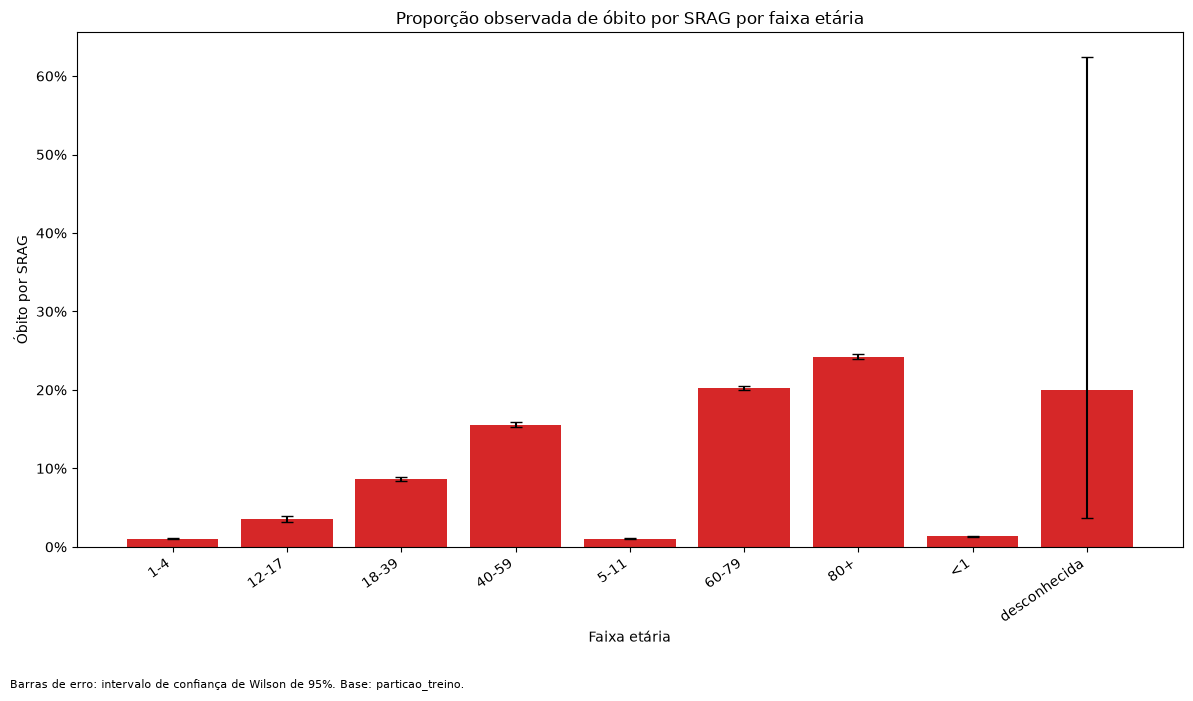

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_obito_faixa_etaria.png


In [73]:
dados_faixa_grafico = (
    obito_faixa_etaria.loc[
        obito_faixa_etaria[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

categorias_faixa = (
    dados_faixa_grafico[
        "faixa_etaria"
    ]
    .astype("string")
    .tolist()
)

percentuais_faixa = (
    dados_faixa_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_faixa = (
    dados_faixa_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_faixa_grafico[
            "ic95_inferior"
        ]
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_faixa = (
    dados_faixa_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_faixa_grafico[
            "percentual_obito_srag"
        ]
    )
    .astype(float)
    .to_numpy()
)

posicoes_faixa = np.arange(
    len(
        dados_faixa_grafico
    )
)

figura_obito_faixa, eixo_obito_faixa = plt.subplots(
    figsize=(
        12,
        7,
    )
)

eixo_obito_faixa.bar(
    posicoes_faixa,
    percentuais_faixa,
    color="tab:red",
)

eixo_obito_faixa.errorbar(
    posicoes_faixa,
    percentuais_faixa,
    yerr=[
        erros_inferiores_faixa,
        erros_superiores_faixa,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_faixa.set_title(
    "Proporção observada de óbito por SRAG por faixa etária"
)

eixo_obito_faixa.set_xlabel(
    "Faixa etária"
)

eixo_obito_faixa.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_faixa.set_xticks(
    posicoes_faixa
)

eixo_obito_faixa.set_xticklabels(
    categorias_faixa,
    rotation=35,
    ha="right",
)

eixo_obito_faixa.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

figura_obito_faixa.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        f"Base: {origem_analise_desfecho}."
    ),
    fontsize=8,
)

figura_obito_faixa.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_obito_faixa.savefig(
    CAMINHO_FIGURA_OBITO_FAIXA_ETARIA,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_OBITO_FAIXA_ETARIA,
)

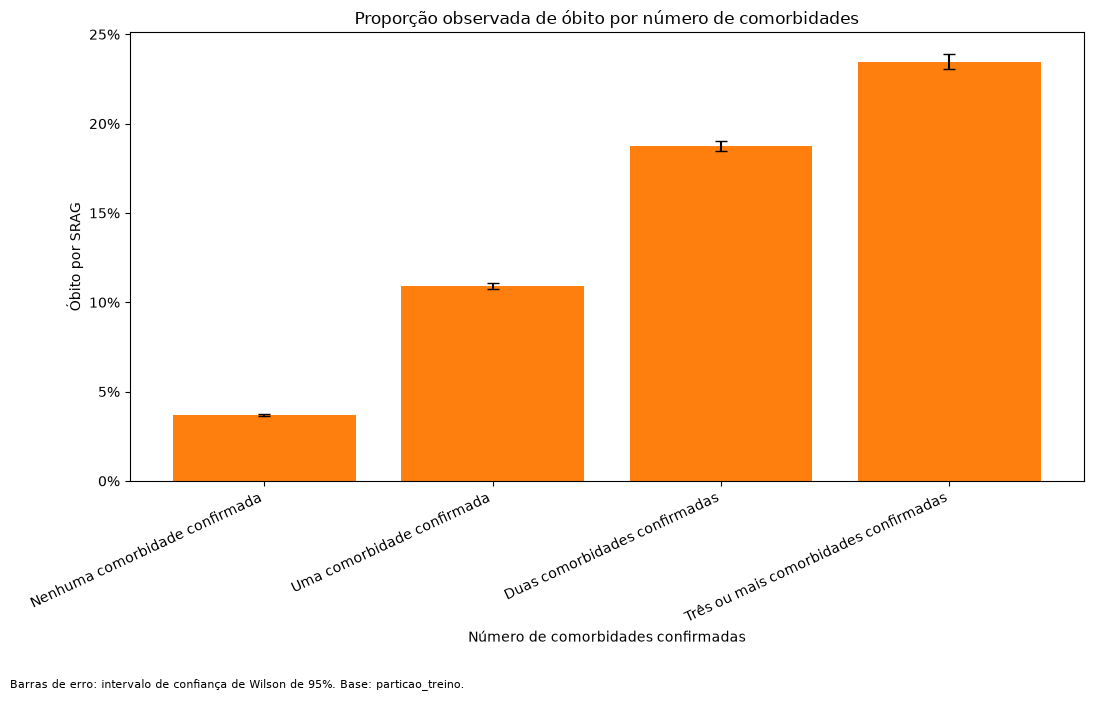

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_obito_numero_comorbidades.png


In [74]:
dados_comorbidades_grafico = (
    obito_numero_comorbidades.loc[
        obito_numero_comorbidades[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

categorias_comorbidades = (
    dados_comorbidades_grafico[
        "grupo_numero_comorbidades"
    ]
    .astype("string")
    .tolist()
)

percentuais_comorbidades = (
    dados_comorbidades_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_comorbidades = (
    dados_comorbidades_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_comorbidades_grafico[
            "ic95_inferior"
        ]
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_comorbidades = (
    dados_comorbidades_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_comorbidades_grafico[
            "percentual_obito_srag"
        ]
    )
    .astype(float)
    .to_numpy()
)

posicoes_comorbidades = np.arange(
    len(
        dados_comorbidades_grafico
    )
)

figura_obito_comorbidades, eixo_obito_comorbidades = plt.subplots(
    figsize=(
        11,
        7,
    )
)

eixo_obito_comorbidades.bar(
    posicoes_comorbidades,
    percentuais_comorbidades,
    color="tab:orange",
)

eixo_obito_comorbidades.errorbar(
    posicoes_comorbidades,
    percentuais_comorbidades,
    yerr=[
        erros_inferiores_comorbidades,
        erros_superiores_comorbidades,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_comorbidades.set_title(
    "Proporção observada de óbito por número de comorbidades"
)

eixo_obito_comorbidades.set_xlabel(
    "Número de comorbidades confirmadas"
)

eixo_obito_comorbidades.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_comorbidades.set_xticks(
    posicoes_comorbidades
)

eixo_obito_comorbidades.set_xticklabels(
    categorias_comorbidades,
    rotation=25,
    ha="right",
)

eixo_obito_comorbidades.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

figura_obito_comorbidades.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        f"Base: {origem_analise_desfecho}."
    ),
    fontsize=8,
)

figura_obito_comorbidades.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_obito_comorbidades.savefig(
    CAMINHO_FIGURA_OBITO_COMORBIDADES,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_OBITO_COMORBIDADES,
)

In [75]:
def criar_grafico_odds_ratio(
    tabela: pd.DataFrame,
    titulo: str,
    caminho_saida: Path,
) -> None:
    """
    Cria um gráfico de razão de chances bruta com IC de 95%.
    """

    dados_grafico = (
        tabela.dropna(
            subset=[
                "odds_ratio_bruta",
                "ic95_or_inferior",
                "ic95_or_superior",
            ]
        )
        .copy()
    )

    dados_grafico = (
        dados_grafico.loc[
            dados_grafico[
                "odds_ratio_bruta"
            ].gt(0)
            & dados_grafico[
                "ic95_or_inferior"
            ].gt(0)
            & dados_grafico[
                "ic95_or_superior"
            ].gt(0)
        ]
        .sort_values(
            "odds_ratio_bruta"
        )
        .reset_index(drop=True)
    )

    if dados_grafico.empty:
        raise ValueError(
            "Não existem razões de chances válidas "
            "para gerar o gráfico."
        )

    posicoes = np.arange(
        len(
            dados_grafico
        )
    )

    valores_or = (
        dados_grafico[
            "odds_ratio_bruta"
        ]
        .astype(float)
        .to_numpy()
    )

    erro_inferior = (
        dados_grafico[
            "odds_ratio_bruta"
        ]
        .sub(
            dados_grafico[
                "ic95_or_inferior"
            ]
        )
        .astype(float)
        .to_numpy()
    )

    erro_superior = (
        dados_grafico[
            "ic95_or_superior"
        ]
        .sub(
            dados_grafico[
                "odds_ratio_bruta"
            ]
        )
        .astype(float)
        .to_numpy()
    )

    rotulos = (
        dados_grafico[
            "nome_amigavel"
        ]
        .astype("string")
        .tolist()
    )

    figura, eixo = plt.subplots(
        figsize=(
            12,
            8,
        )
    )

    eixo.errorbar(
        valores_or,
        posicoes,
        xerr=[
            erro_inferior,
            erro_superior,
        ],
        fmt="o",
        color="tab:blue",
        ecolor="black",
        capsize=4,
    )

    eixo.axvline(
        x=1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
    )

    eixo.set_xscale(
        "log"
    )

    eixo.set_yticks(
        posicoes
    )

    eixo.set_yticklabels(
        rotulos
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Razão de chances bruta, escala logarítmica"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    figura.text(
        0.01,
        0.01,
        (
            "Comparação: resposta sim versus resposta não. "
            "Intervalo de confiança de 95%. "
            "Associação bruta, não ajustada e não causal."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.05,
            1,
            1,
        ]
    )

    figura.savefig(
        caminho_saida,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        caminho_saida,
    )

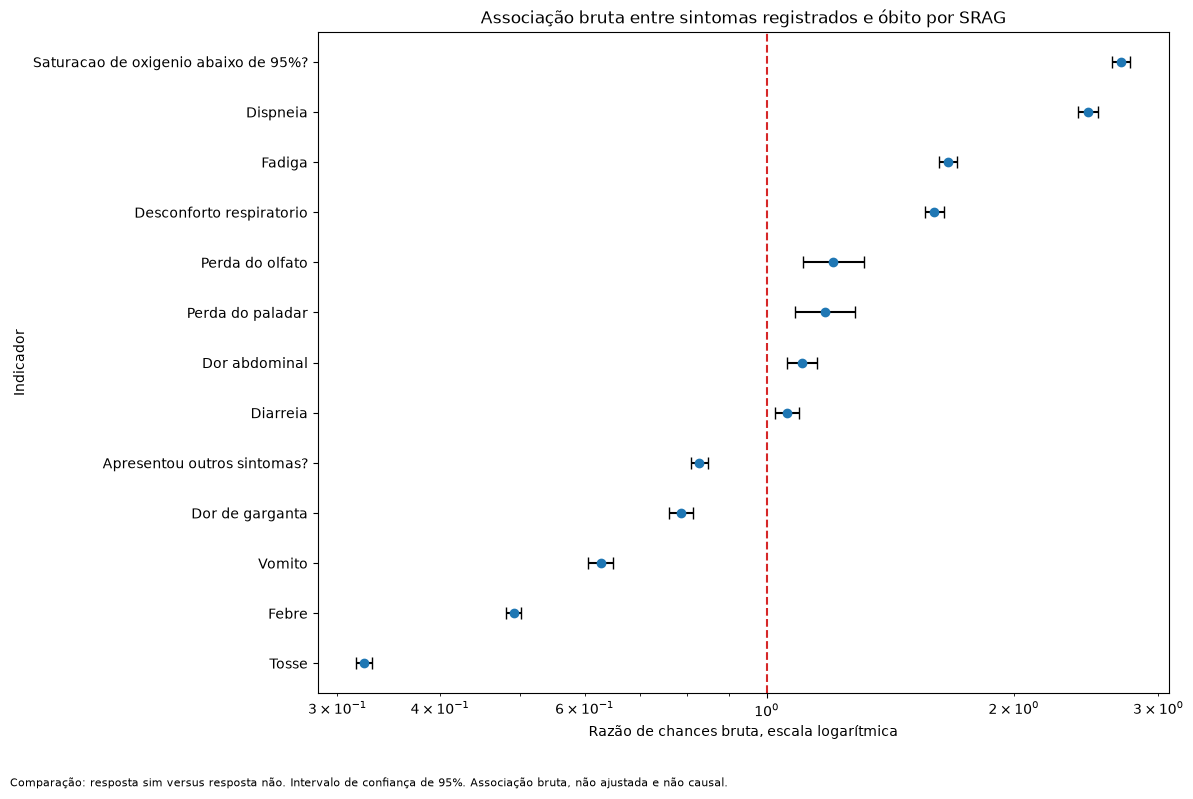

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_odds_ratio_sintomas.png


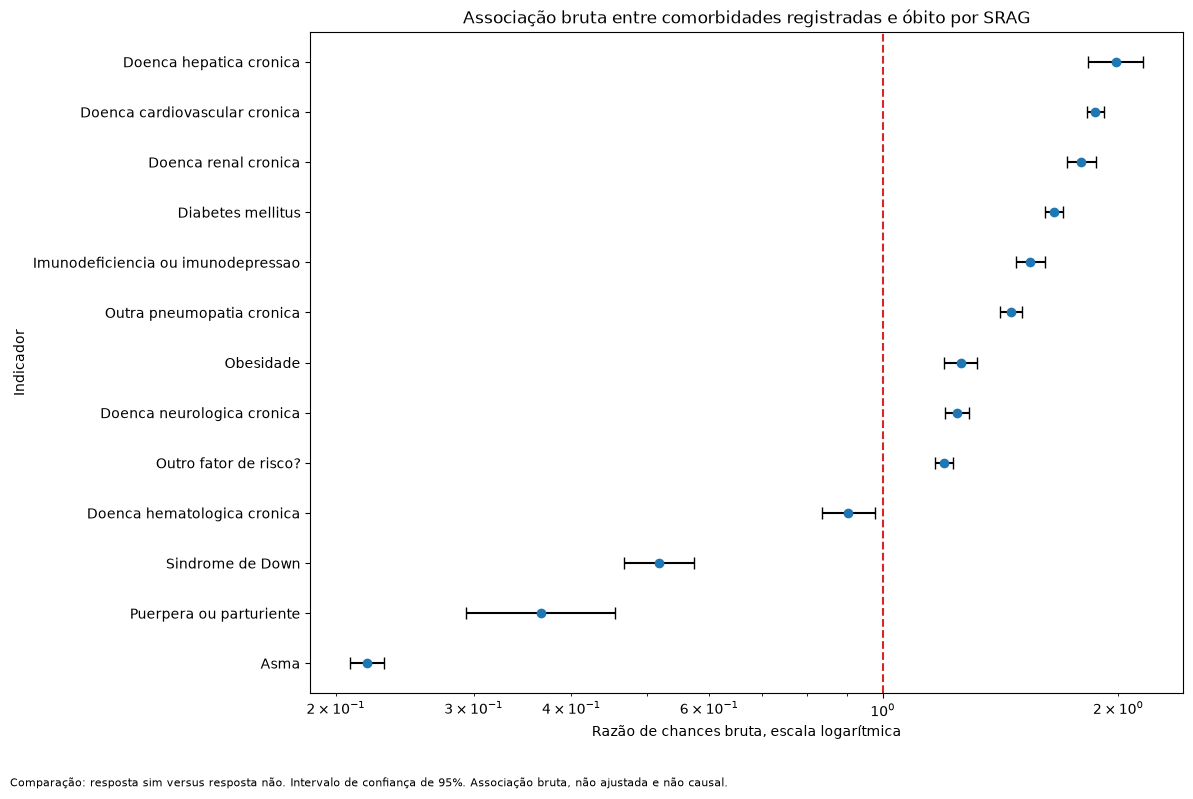

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_odds_ratio_comorbidades.png


In [76]:
criar_grafico_odds_ratio(
    tabela=obito_sintomas,
    titulo=(
        "Associação bruta entre sintomas registrados "
        "e óbito por SRAG"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_OR_SINTOMAS
    ),
)

criar_grafico_odds_ratio(
    tabela=obito_comorbidades,
    titulo=(
        "Associação bruta entre comorbidades registradas "
        "e óbito por SRAG"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_OR_COMORBIDADES
    ),
)

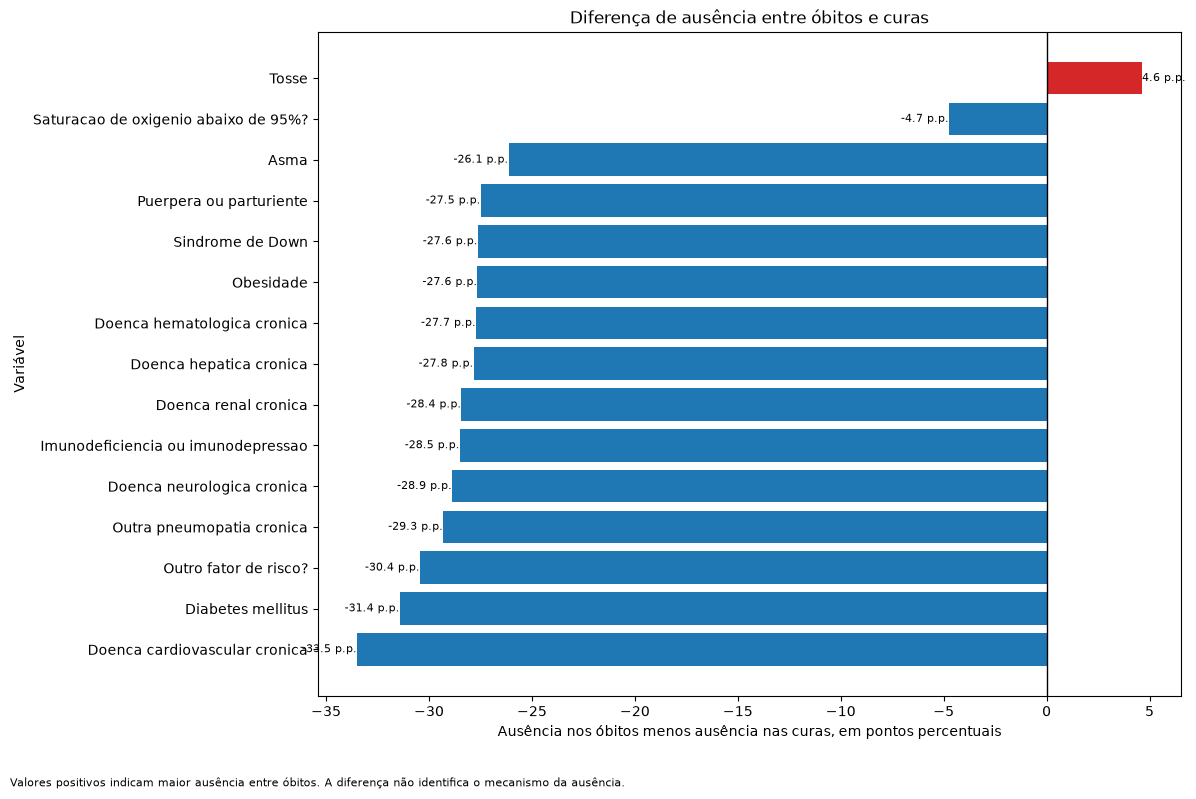

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_ausencia_por_desfecho.png


In [77]:
QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO = 15

ausencia_grafico = (
    ausencia_por_desfecho.head(
        QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO
    )
    .sort_values(
        "diferenca_pp_obito_menos_cura"
    )
    .copy()
)

figura_ausencia, eixo_ausencia = plt.subplots(
    figsize=(
        12,
        8,
    )
)

cores_ausencia = [
    (
        "tab:red"
        if diferenca > 0
        else "tab:blue"
    )
    for diferenca in ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ]
]

barras_ausencia = eixo_ausencia.barh(
    ausencia_grafico[
        "nome_amigavel"
    ],
    ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ],
    color=cores_ausencia,
)

eixo_ausencia.axvline(
    x=0,
    color="black",
    linewidth=1,
)

eixo_ausencia.set_title(
    "Diferença de ausência entre óbitos e curas"
)

eixo_ausencia.set_xlabel(
    "Ausência nos óbitos menos ausência nas curas, em pontos percentuais"
)

eixo_ausencia.set_ylabel(
    "Variável"
)

for barra, diferenca in zip(
    barras_ausencia,
    ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ],
):
    alinhamento = (
        "left"
        if diferenca >= 0
        else "right"
    )

    eixo_ausencia.text(
        diferenca,
        barra.get_y()
        + barra.get_height()
        / 2,
        f"{diferenca:.1f} p.p.",
        va="center",
        ha=alinhamento,
        fontsize=8,
    )

figura_ausencia.text(
    0.01,
    0.01,
    (
        "Valores positivos indicam maior ausência entre óbitos. "
        "A diferença não identifica o mecanismo da ausência."
    ),
    fontsize=8,
)

figura_ausencia.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_ausencia.savefig(
    CAMINHO_FIGURA_AUSENCIA_DESFECHO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_AUSENCIA_DESFECHO,
)

In [78]:
quantidade_base_desfecho = len(
    base_analise_desfecho
)

quantidade_obitos_desfecho = int(
    base_analise_desfecho[
        "alvo_obito_srag"
    ]
    .sum()
)

quantidade_curas_desfecho = (
    quantidade_base_desfecho
    - quantidade_obitos_desfecho
)

percentual_obito_global = (
    quantidade_obitos_desfecho
    / quantidade_base_desfecho
    * 100
)

ic_global_obito = calcular_ic_wilson(
    quantidade_eventos=(
        quantidade_obitos_desfecho
    ),
    quantidade_total=(
        quantidade_base_desfecho
    ),
)

resumo_analise_desfecho = pd.DataFrame(
    {
        "metrica": [
            "origem_analise",
            "quantidade_registros",
            "quantidade_curas",
            "quantidade_obitos_srag",
            "percentual_obito_srag",
            "ic95_obito_inferior",
            "ic95_obito_superior",
            "quantidade_sintomas_analisados",
            "quantidade_comorbidades_analisadas",
            "quantidade_variaveis_ausencia",
        ],
        "valor": [
            origem_analise_desfecho,
            quantidade_base_desfecho,
            quantidade_curas_desfecho,
            quantidade_obitos_desfecho,
            percentual_obito_global,
            ic_global_obito[0],
            ic_global_obito[1],
            len(
                obito_sintomas
            ),
            len(
                obito_comorbidades
            ),
            len(
                ausencia_por_desfecho
            ),
        ],
    }
)

display(
    resumo_analise_desfecho
)

,metrica,valor
0,origem_analise,particao_treino
1,quantidade_registros,556462
2,quantidade_curas,509501
3,quantidade_obitos_srag,46961
4,percentual_obito_srag,8.439211
5,ic95_obito_inferior,8.366461
6,ic95_obito_superior,8.512534
7,quantidade_sintomas_analisados,13
8,quantidade_comorbidades_analisadas,13
9,quantidade_variaveis_ausencia,26


In [79]:
obito_faixa_etaria.to_csv(
    CAMINHO_OBITO_FAIXA_ETARIA,
    index=False,
    encoding="utf-8-sig",
)

obito_numero_comorbidades.to_csv(
    CAMINHO_OBITO_NUMERO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

obito_sintomas.to_csv(
    CAMINHO_OBITO_SINTOMAS,
    index=False,
    encoding="utf-8-sig",
)

obito_comorbidades.to_csv(
    CAMINHO_OBITO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

ausencia_por_desfecho.to_csv(
    CAMINHO_AUSENCIA_DESFECHO,
    index=False,
    encoding="utf-8-sig",
)

resumo_analise_desfecho.to_csv(
    CAMINHO_RESUMO_DESFECHO,
    index=False,
    encoding="utf-8-sig",
)

percentuais_faixa_validos = (
    obito_faixa_etaria[
        "percentual_obito_srag"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_comorbidades_validos = (
    obito_numero_comorbidades[
        "percentual_obito_srag"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

odds_ratios_sintomas_validas = (
    obito_sintomas[
        "odds_ratio_bruta"
    ]
    .dropna()
    .gt(0)
    .all()
)

odds_ratios_comorbidades_validas = (
    obito_comorbidades[
        "odds_ratio_bruta"
    ]
    .dropna()
    .gt(0)
    .all()
)

verificacoes_desfecho = {
    "base_desfecho_nao_vazia": (
        not base_analise_desfecho.empty
    ),
    "cura_presente": (
        quantidade_curas_desfecho > 0
    ),
    "obito_presente": (
        quantidade_obitos_desfecho > 0
    ),
    "tabela_faixa_etaria_nao_vazia": (
        not obito_faixa_etaria.empty
    ),
    "tabela_numero_comorbidades_nao_vazia": (
        not obito_numero_comorbidades.empty
    ),
    "tabela_sintomas_nao_vazia": (
        not obito_sintomas.empty
    ),
    "tabela_comorbidades_nao_vazia": (
        not obito_comorbidades.empty
    ),
    "tabela_ausencia_nao_vazia": (
        not ausencia_por_desfecho.empty
    ),
    "percentuais_faixa_validos": (
        percentuais_faixa_validos
    ),
    "percentuais_comorbidades_validos": (
        percentuais_comorbidades_validos
    ),
    "odds_ratios_sintomas_positivas": (
        odds_ratios_sintomas_validas
    ),
    "odds_ratios_comorbidades_positivas": (
        odds_ratios_comorbidades_validas
    ),
    "arquivo_faixa_etaria_criado": (
        CAMINHO_OBITO_FAIXA_ETARIA.exists()
    ),
    "arquivo_numero_comorbidades_criado": (
        CAMINHO_OBITO_NUMERO_COMORBIDADES.exists()
    ),
    "arquivo_sintomas_criado": (
        CAMINHO_OBITO_SINTOMAS.exists()
    ),
    "arquivo_comorbidades_criado": (
        CAMINHO_OBITO_COMORBIDADES.exists()
    ),
    "arquivo_ausencia_criado": (
        CAMINHO_AUSENCIA_DESFECHO.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_DESFECHO.exists()
    ),
    "figura_faixa_etaria_criada": (
        CAMINHO_FIGURA_OBITO_FAIXA_ETARIA.exists()
    ),
    "figura_numero_comorbidades_criada": (
        CAMINHO_FIGURA_OBITO_COMORBIDADES.exists()
    ),
    "figura_or_sintomas_criada": (
        CAMINHO_FIGURA_OR_SINTOMAS.exists()
    ),
    "figura_or_comorbidades_criada": (
        CAMINHO_FIGURA_OR_COMORBIDADES.exists()
    ),
    "figura_ausencia_criada": (
        CAMINHO_FIGURA_AUSENCIA_DESFECHO.exists()
    ),
}

verificacoes_desfecho_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_desfecho.keys()
        ),
        "resultado": list(
            verificacoes_desfecho.values()
        ),
    }
)

display(
    verificacoes_desfecho_df
)

if not all(
    verificacoes_desfecho.values()
):
    falhas_desfecho = [
        verificacao
        for verificacao, resultado
        in verificacoes_desfecho.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise do desfecho terminou com falhas: "
        f"{falhas_desfecho}"
    )

print(
    "Análise de óbito validada com sucesso."
)

,verificacao,resultado
0,base_desfecho_nao_vazia,True
1,cura_presente,True
2,obito_presente,True
3,tabela_faixa_etaria_nao_vazia,True
4,tabela_numero_comorbidades_nao_vazia,True
5,tabela_sintomas_nao_vazia,True
6,tabela_comorbidades_nao_vazia,True
7,tabela_ausencia_nao_vazia,True
8,percentuais_faixa_validos,True
9,percentuais_comorbidades_validos,True


Análise de óbito validada com sucesso.


In [80]:
import seaborn as sns


def preparar_matriz_clinica_heatmap(
    tabela_clinica: pd.DataFrame,
    coluna_valor: str,
) -> tuple:
    """Transforma a tabela clínica longa em uma matriz variável por ano."""

    COLUNAS_NECESSARIAS = [
        "ano_internacao",
        "coluna",
        "nome_amigavel",
        coluna_valor,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in tabela_clinica.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela clínica não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_heatmap = (
        tabela_clinica[
            COLUNAS_NECESSARIAS
        ]
        .copy()
    )

    dados_heatmap[
        coluna_valor
    ] = pd.to_numeric(
        dados_heatmap[
            coluna_valor
        ],
        errors="coerce",
    )

    matriz_heatmap = (
        dados_heatmap.pivot(
            index="coluna",
            columns="ano_internacao",
            values=coluna_valor,
        )
        .sort_index(
            axis=1
        )
    )

    nomes_amigaveis_heatmap = (
        dados_heatmap[
            [
                "coluna",
                "nome_amigavel",
            ]
        ]
        .drop_duplicates(
            subset=[
                "coluna",
            ]
        )
        .set_index(
            "coluna"
        )[
            "nome_amigavel"
        ]
        .astype("string")
    )

    rotulos_linhas = []

    for coluna in matriz_heatmap.index:
        nome_amigavel = nomes_amigaveis_heatmap.get(
            coluna,
            coluna,
        )

        if pd.isna(
            nome_amigavel
        ):
            nome_amigavel = coluna

        nome_amigavel = str(
            nome_amigavel
        ).strip()

        if not nome_amigavel:
            nome_amigavel = coluna

        if nome_amigavel.lower() == coluna.lower():
            rotulo = nome_amigavel
        else:
            rotulo = (
                f"{nome_amigavel} ({coluna})"
            )

        rotulos_linhas.append(
            rotulo
        )

    matriz_heatmap.index = (
        rotulos_linhas
    )

    matriz_heatmap.columns = [
        int(
            ano
        )
        for ano in matriz_heatmap.columns
    ]

    return (
        matriz_heatmap,
        rotulos_linhas,
    )


def exibir_heatmap_percentual(
    matriz: pd.DataFrame,
    titulo: str,
    rotulo_escala: str,
    mapa_cores: str,
) -> None:
    """
    Exibe um heatmap percentual diretamente no notebook.
    """

    if matriz.empty:
        raise ValueError(
            "A matriz recebida para o heatmap está vazia."
        )

    valores_validos = (
        matriz.stack(
            future_stack=True
        )
        .dropna()
    )

    if valores_validos.empty:
        raise ValueError(
            "A matriz do heatmap não contém valores numéricos."
        )

    if not valores_validos.between(
        0,
        100,
        inclusive="both",
    ).all():
        raise ValueError(
            "O heatmap percentual contém valores "
            "fora do intervalo de zero a cem."
        )

    altura_figura = max(
        5,
        len(
            matriz
        )
        * 0.48,
    )

    figura, eixo = plt.subplots(
        figsize=(
            12,
            altura_figura,
        )
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".1f",
        cmap=mapa_cores,
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            "label": rotulo_escala,
        },
        annot_kws={
            "fontsize": 8,
        },
        ax=eixo,
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Ano da internação"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    eixo.set_xticklabels(
        eixo.get_xticklabels(),
        rotation=0,
    )

    eixo.set_yticklabels(
        eixo.get_yticklabels(),
        rotation=0,
    )

    figura.tight_layout()

    plt.show()

    plt.close(
        figura
    )

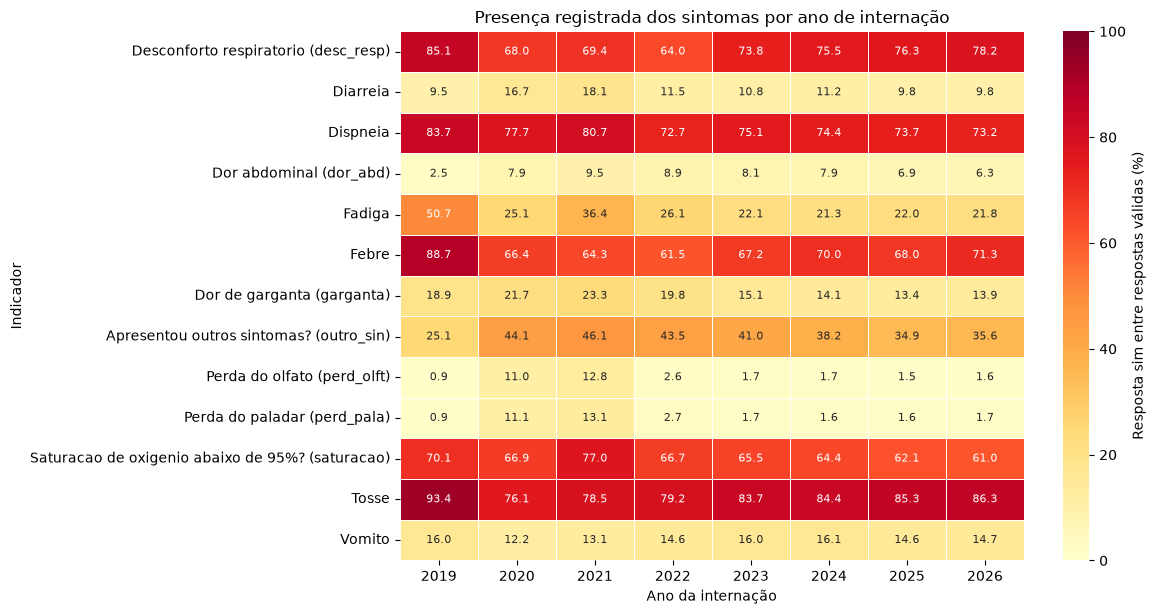

In [81]:
matriz_sintomas_presenca, rotulos_sintomas = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=sintomas_por_ano,
        coluna_valor="percentual_sim_validos",
    )
)

exibir_heatmap_percentual(
    matriz=matriz_sintomas_presenca,
    titulo=(
        "Presença registrada dos sintomas por ano de internação"
    ),
    rotulo_escala=(
        "Resposta sim entre respostas válidas (%)"
    ),
    mapa_cores="YlOrRd",
)

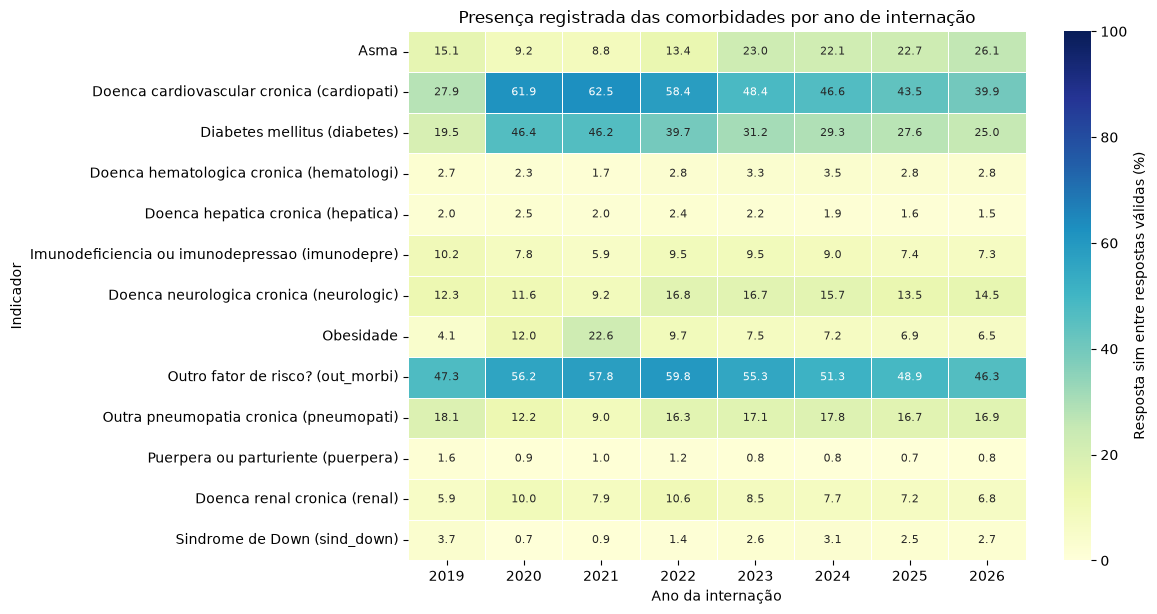

In [82]:
matriz_comorbidades_presenca, rotulos_comorbidades = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=comorbidades_por_ano,
        coluna_valor="percentual_sim_validos",
    )
)

exibir_heatmap_percentual(
    matriz=matriz_comorbidades_presenca,
    titulo=(
        "Presença registrada das comorbidades por ano de internação"
    ),
    rotulo_escala=(
        "Resposta sim entre respostas válidas (%)"
    ),
    mapa_cores="YlGnBu",
)

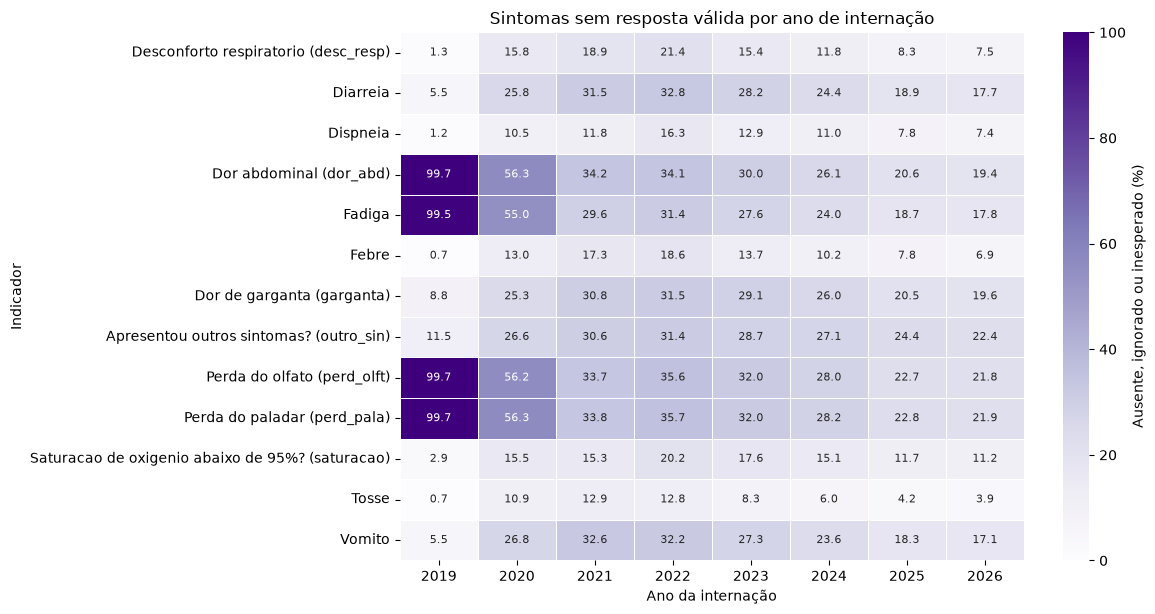

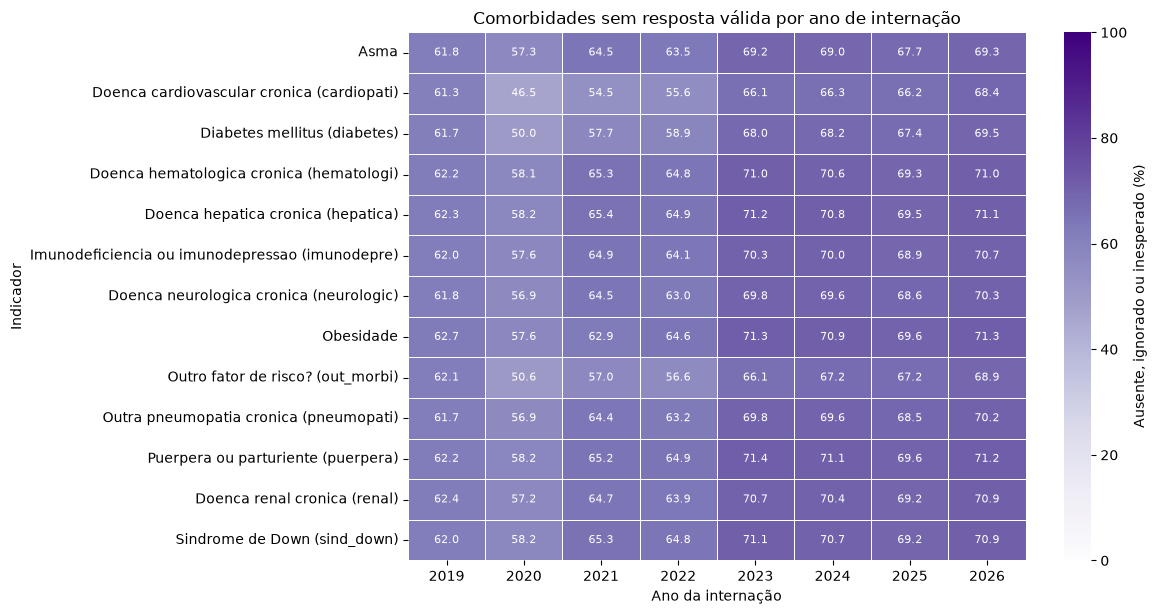

In [83]:
matriz_sintomas_sem_resposta, rotulos_sintomas_sem_resposta = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=sintomas_por_ano,
        coluna_valor=(
            "percentual_sem_resposta_valida"
        ),
    )
)

matriz_comorbidades_sem_resposta, rotulos_comorbidades_sem_resposta = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=comorbidades_por_ano,
        coluna_valor=(
            "percentual_sem_resposta_valida"
        ),
    )
)

exibir_heatmap_percentual(
    matriz=matriz_sintomas_sem_resposta,
    titulo=(
        "Sintomas sem resposta válida por ano de internação"
    ),
    rotulo_escala=(
        "Ausente, ignorado ou inesperado (%)"
    ),
    mapa_cores="Purples",
)

exibir_heatmap_percentual(
    matriz=matriz_comorbidades_sem_resposta,
    titulo=(
        "Comorbidades sem resposta válida por ano de internação"
    ),
    rotulo_escala=(
        "Ausente, ignorado ou inesperado (%)"
    ),
    mapa_cores="Purples",
)

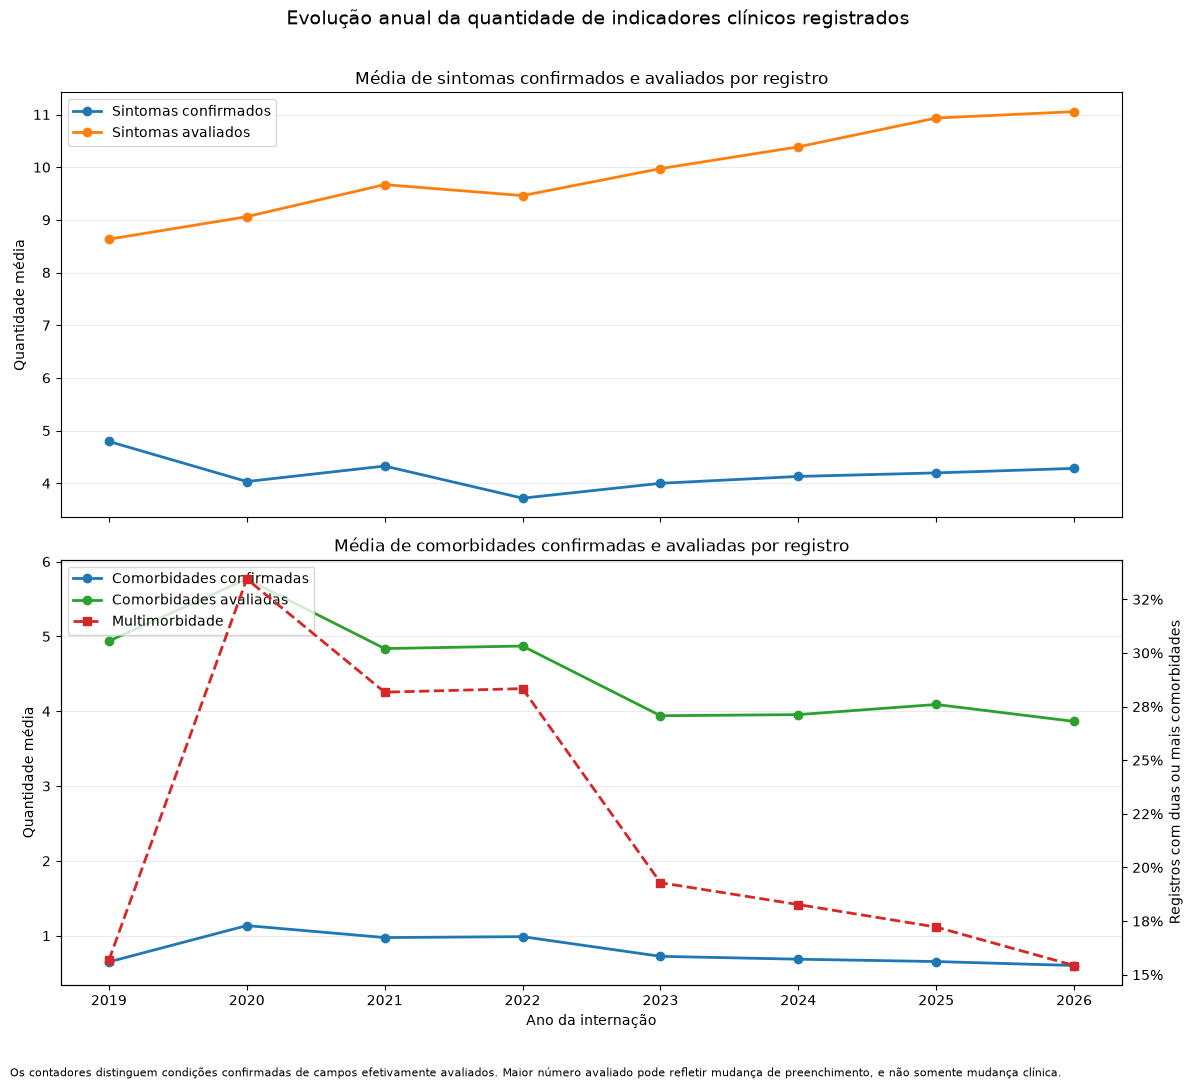

In [84]:
COLUNAS_CONTADORES_GRAFICO = [
    "ano_internacao",
    "sintomas_confirmados_media",
    "sintomas_avaliados_media",
    "comorbidades_confirmadas_media",
    "comorbidades_avaliadas_media",
    "percentual_multimorbidade",
]

colunas_contadores_ausentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_GRAFICO
    if coluna not in contadores_clinicos_por_ano.columns
]

if colunas_contadores_ausentes:
    raise KeyError(
        "A tabela de contadores clínicos não contém: "
        f"{colunas_contadores_ausentes}"
    )

dados_contadores_grafico = (
    contadores_clinicos_por_ano[
        COLUNAS_CONTADORES_GRAFICO
    ]
    .sort_values(
        "ano_internacao"
    )
    .copy()
)

anos_contadores = (
    dados_contadores_grafico[
        "ano_internacao"
    ]
    .astype(int)
    .to_numpy()
)

figura_contadores, eixos_contadores = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(
        12,
        11,
    ),
    sharex=True,
)

eixo_sintomas = (
    eixos_contadores[0]
)

eixo_sintomas.plot(
    anos_contadores,
    dados_contadores_grafico[
        "sintomas_confirmados_media"
    ],
    marker="o",
    linewidth=2,
    label="Sintomas confirmados",
)

eixo_sintomas.plot(
    anos_contadores,
    dados_contadores_grafico[
        "sintomas_avaliados_media"
    ],
    marker="o",
    linewidth=2,
    label="Sintomas avaliados",
)

eixo_sintomas.set_title(
    "Média de sintomas confirmados e avaliados por registro"
)

eixo_sintomas.set_ylabel(
    "Quantidade média"
)

eixo_sintomas.legend()

eixo_sintomas.grid(
    axis="y",
    alpha=0.25,
)

eixo_comorbidades = (
    eixos_contadores[1]
)

eixo_comorbidades.plot(
    anos_contadores,
    dados_contadores_grafico[
        "comorbidades_confirmadas_media"
    ],
    marker="o",
    linewidth=2,
    color="tab:blue",
    label="Comorbidades confirmadas",
)

eixo_comorbidades.plot(
    anos_contadores,
    dados_contadores_grafico[
        "comorbidades_avaliadas_media"
    ],
    marker="o",
    linewidth=2,
    color="tab:green",
    label="Comorbidades avaliadas",
)

eixo_comorbidades.set_title(
    "Média de comorbidades confirmadas e avaliadas por registro"
)

eixo_comorbidades.set_xlabel(
    "Ano da internação"
)

eixo_comorbidades.set_ylabel(
    "Quantidade média"
)

eixo_comorbidades.set_xticks(
    anos_contadores
)

eixo_comorbidades.legend(
    loc="upper left"
)

eixo_comorbidades.grid(
    axis="y",
    alpha=0.25,
)

eixo_multimorbidade = (
    eixo_comorbidades.twinx()
)

eixo_multimorbidade.plot(
    anos_contadores,
    dados_contadores_grafico[
        "percentual_multimorbidade"
    ],
    marker="s",
    linewidth=2,
    linestyle="--",
    color="tab:red",
    label="Multimorbidade",
)

eixo_multimorbidade.set_ylabel(
    "Registros com duas ou mais comorbidades"
)

eixo_multimorbidade.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

linhas_comorbidades, rotulos_comorbidades_grafico = (
    eixo_comorbidades.get_legend_handles_labels()
)

linhas_multimorbidade, rotulos_multimorbidade = (
    eixo_multimorbidade.get_legend_handles_labels()
)

eixo_comorbidades.legend(
    linhas_comorbidades
    + linhas_multimorbidade,
    rotulos_comorbidades_grafico
    + rotulos_multimorbidade,
    loc="upper left",
)

figura_contadores.suptitle(
    "Evolução anual da quantidade de indicadores clínicos registrados",
    fontsize=14,
)

figura_contadores.text(
    0.01,
    0.01,
    (
        "Os contadores distinguem condições confirmadas de campos "
        "efetivamente avaliados. Maior número avaliado pode refletir "
        "mudança de preenchimento, e não somente mudança clínica."
    ),
    fontsize=8,
)

figura_contadores.tight_layout(
    rect=[
        0,
        0.04,
        1,
        0.97,
    ]
)

plt.show()

plt.close(
    figura_contadores
)

In [85]:
def criar_tabela_obito_categoria_ano(
    dataframe: pd.DataFrame,
    coluna_categoria: str,
    nome_categoria_saida: str,
) -> pd.DataFrame:
    """Calcula quantidade, proporção de óbito e intervalo de confiança de Wilson por categoria e ano de internação."""

    COLUNAS_NECESSARIAS = [
        "ano_internacao",
        "alvo_obito_srag",
        coluna_categoria,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A base não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    tabela = (
        dataframe.groupby(
            [
                "ano_internacao",
                coluna_categoria,
            ],
            dropna=False,
        )
        .agg(
            quantidade_total=(
                "alvo_obito_srag",
                "size",
            ),
            quantidade_obito_srag=(
                "alvo_obito_srag",
                "sum",
            ),
        )
        .reset_index()
        .rename(
            columns={
                coluna_categoria: (
                    nome_categoria_saida
                ),
            }
        )
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .sub(
            tabela[
                "quantidade_obito_srag"
            ]
        )
    )

    tabela[
        "percentual_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .div(
            tabela[
                "quantidade_total"
            ]
            .replace(
                0,
                np.nan,
            )
        )
        .mul(100)
    )

    intervalos = []

    for _, linha in tabela.iterrows():
        intervalo = calcular_ic_wilson(
            quantidade_eventos=int(
                linha[
                    "quantidade_obito_srag"
                ]
            ),
            quantidade_total=int(
                linha[
                    "quantidade_total"
                ]
            ),
        )

        intervalos.append(
            intervalo
        )

    tabela[
        "ic95_inferior"
    ] = [
        intervalo[0]
        for intervalo in intervalos
    ]

    tabela[
        "ic95_superior"
    ] = [
        intervalo[1]
        for intervalo in intervalos
    ]

    tabela[
        "ano_internacao"
    ] = (
        tabela[
            "ano_internacao"
        ]
        .astype("Int64")
    )

    tabela[
        "quantidade_total"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .astype("int64")
    )

    tabela[
        "quantidade_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .astype("int64")
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_cura"
        ]
        .astype("int64")
    )

    percentuais_validos = (
        tabela[
            "percentual_obito_srag"
        ]
        .dropna()
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    )

    if not percentuais_validos:
        raise RuntimeError(
            "Foram produzidos percentuais de óbito "
            "fora do intervalo de 0% a 100%."
        )

    total_tabela = int(
        tabela[
            "quantidade_total"
        ]
        .sum()
    )

    if total_tabela != len(
        dataframe
    ):
        raise RuntimeError(
            "A soma dos denominadores da tabela por categoria "
            "e ano não corresponde ao total da base analisada."
        )

    tabela = (
        tabela.sort_values(
            [
                "ano_internacao",
                nome_categoria_saida,
            ]
        )
        .reset_index(drop=True)
    )

    return tabela

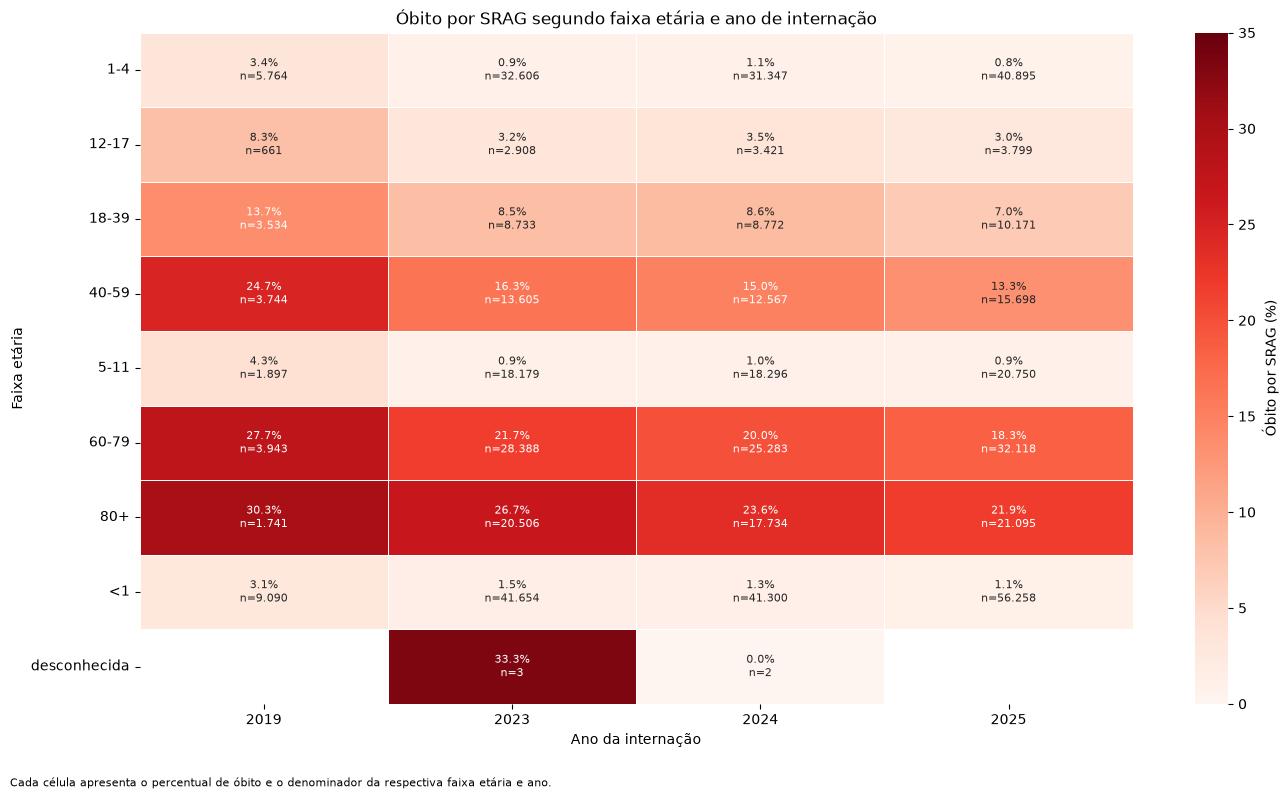

,ano_internacao,faixa_etaria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,1-4,5764,196,5568,3.400416,2.962694,3.900211
1,2019,12-17,661,55,606,8.320726,6.448334,10.674765
2,2019,18-39,3534,485,3049,13.723826,12.628665,14.897766
3,2019,40-59,3744,923,2821,24.652778,23.298688,26.058828
4,2019,5-11,1897,81,1816,4.2699,3.448747,5.275887
5,2019,60-79,3943,1092,2851,27.694649,26.320122,29.112595
6,2019,80+,1741,528,1213,30.327398,28.213431,32.527988
7,2019,<1,9090,284,8806,3.124312,2.785998,3.502230
8,2023,1-4,32606,293,32313,0.898608,0.801805,1.006978
9,2023,12-17,2908,93,2815,3.198074,2.617769,3.901867


In [86]:
if "faixa_etaria" not in base_analise_desfecho.columns:
    raise KeyError(
        "A coluna faixa_etaria não está disponível. "
        "Execute primeiro a seção demográfica."
    )

obito_faixa_etaria_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria="faixa_etaria",
        nome_categoria_saida="faixa_etaria",
    )
)

ordem_faixas_disponiveis = [
    faixa
    for faixa in ORDEM_FAIXA_OBITO
    if faixa in set(
        obito_faixa_etaria_ano[
            "faixa_etaria"
        ]
        .astype("string")
        .tolist()
    )
]

matriz_obito_faixa_etaria_ano = (
    obito_faixa_etaria_ano.pivot(
        index="faixa_etaria",
        columns="ano_internacao",
        values="percentual_obito_srag",
    )
    .reindex(
        ordem_faixas_disponiveis
    )
    .sort_index(
        axis=1
    )
)

matriz_n_faixa_etaria_ano = (
    obito_faixa_etaria_ano.pivot(
        index="faixa_etaria",
        columns="ano_internacao",
        values="quantidade_total",
    )
    .reindex(
        ordem_faixas_disponiveis
    )
    .reindex(
        columns=(
            matriz_obito_faixa_etaria_ano.columns
        )
    )
)

if matriz_obito_faixa_etaria_ano.empty:
    raise ValueError(
        "A matriz de óbito por faixa etária e ano está vazia."
    )

valores_obito_faixa = (
    matriz_obito_faixa_etaria_ano
    .stack(
        future_stack=True
    )
    .dropna()
)

if valores_obito_faixa.empty:
    raise ValueError(
        "A matriz não contém percentuais de óbito válidos."
    )

if not valores_obito_faixa.between(
    0,
    100,
    inclusive="both",
).all():
    raise RuntimeError(
        "A matriz contém percentuais fora "
        "do intervalo de 0% a 100%."
    )

if valores_obito_faixa.eq(0).all():
    raise RuntimeError(
        "Todos os percentuais de óbito ficaram iguais a zero. "
        "Verifique o cálculo de percentual_obito_srag."
    )

valor_maximo_observado = float(
    valores_obito_faixa.max()
)

limite_superior_escala = max(
    10.0,
    np.ceil(
        valor_maximo_observado
        / 5
    )
    * 5,
)

anotacoes_heatmap = (
    matriz_obito_faixa_etaria_ano
    .copy()
    .astype("object")
)

for faixa in matriz_obito_faixa_etaria_ano.index:
    for ano in matriz_obito_faixa_etaria_ano.columns:
        percentual = (
            matriz_obito_faixa_etaria_ano.loc[
                faixa,
                ano,
            ]
        )

        quantidade = (
            matriz_n_faixa_etaria_ano.loc[
                faixa,
                ano,
            ]
        )

        if pd.isna(
            percentual
        ):
            anotacao = ""
        else:
            percentual_formatado = (
                f"{float(percentual):.1f}%"
            )

            if pd.isna(
                quantidade
            ):
                anotacao = percentual_formatado
            else:
                quantidade_formatada = (
                    f"{int(quantidade):,}"
                    .replace(
                        ",",
                        ".",
                    )
                )

                anotacao = (
                    f"{percentual_formatado}\n"
                    f"n={quantidade_formatada}"
                )

        anotacoes_heatmap.loc[
            faixa,
            ano,
        ] = anotacao

matriz_obito_faixa_etaria_ano_plot = pd.DataFrame(
    matriz_obito_faixa_etaria_ano.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    ),
    index=matriz_obito_faixa_etaria_ano.index.copy(),
    columns=matriz_obito_faixa_etaria_ano.columns.copy(),
)

anotacoes_heatmap_plot = pd.DataFrame(
    anotacoes_heatmap.to_numpy(
        dtype=object,
        copy=True,
    ),
    index=anotacoes_heatmap.index.copy(),
    columns=anotacoes_heatmap.columns.copy(),
)

if (
    matriz_obito_faixa_etaria_ano_plot.shape
    != anotacoes_heatmap_plot.shape
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem dimensões diferentes."
    )

if not matriz_obito_faixa_etaria_ano_plot.index.equals(
    anotacoes_heatmap_plot.index
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem índices diferentes."
    )

if not matriz_obito_faixa_etaria_ano_plot.columns.equals(
    anotacoes_heatmap_plot.columns
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem colunas diferentes."
    )

valores_finitos_heatmap = (
    matriz_obito_faixa_etaria_ano_plot
    .to_numpy(
        dtype=np.float64,
        copy=False,
    )
)

mascara_valores_validos_heatmap = np.isfinite(
    valores_finitos_heatmap
)

if not mascara_valores_validos_heatmap.any():
    raise ValueError(
        "A matriz do heatmap não contém nenhum "
        "percentual numérico válido."
    )

valores_validos_heatmap = (
    valores_finitos_heatmap[
        mascara_valores_validos_heatmap
    ]
)

if not (
    (
        valores_validos_heatmap
        >= 0
    )
    & (
        valores_validos_heatmap
        <= 100
    )
).all():
    raise RuntimeError(
        "A matriz do heatmap contém percentuais "
        "fora do intervalo de 0% a 100%."
    )

mascara_heatmap = (
    matriz_obito_faixa_etaria_ano_plot
    .isna()
)

figura_obito_faixa_ano, eixo_obito_faixa_ano = plt.subplots(
    figsize=(
        14,
        8,
    )
)

sns.heatmap(
    matriz_obito_faixa_etaria_ano_plot,
    mask=mascara_heatmap,
    annot=anotacoes_heatmap_plot,
    fmt="",
    cmap="Reds",
    vmin=0,
    vmax=limite_superior_escala,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Óbito por SRAG (%)",
    },
    annot_kws={
        "fontsize": 8,
    },
    ax=eixo_obito_faixa_ano,
)

eixo_obito_faixa_ano.set_title(
    "Óbito por SRAG segundo faixa etária e ano de internação"
)

eixo_obito_faixa_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_faixa_ano.set_ylabel(
    "Faixa etária"
)

eixo_obito_faixa_ano.set_xticklabels(
    eixo_obito_faixa_ano.get_xticklabels(),
    rotation=0,
)

eixo_obito_faixa_ano.set_yticklabels(
    eixo_obito_faixa_ano.get_yticklabels(),
    rotation=0,
)

figura_obito_faixa_ano.text(
    0.01,
    0.01,
    (
        "Cada célula apresenta o percentual de óbito e o "
        "denominador da respectiva faixa etária e ano."
    ),
    fontsize=8,
)

figura_obito_faixa_ano.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_faixa_ano
)

display(
    obito_faixa_etaria_ano.head(30)
)

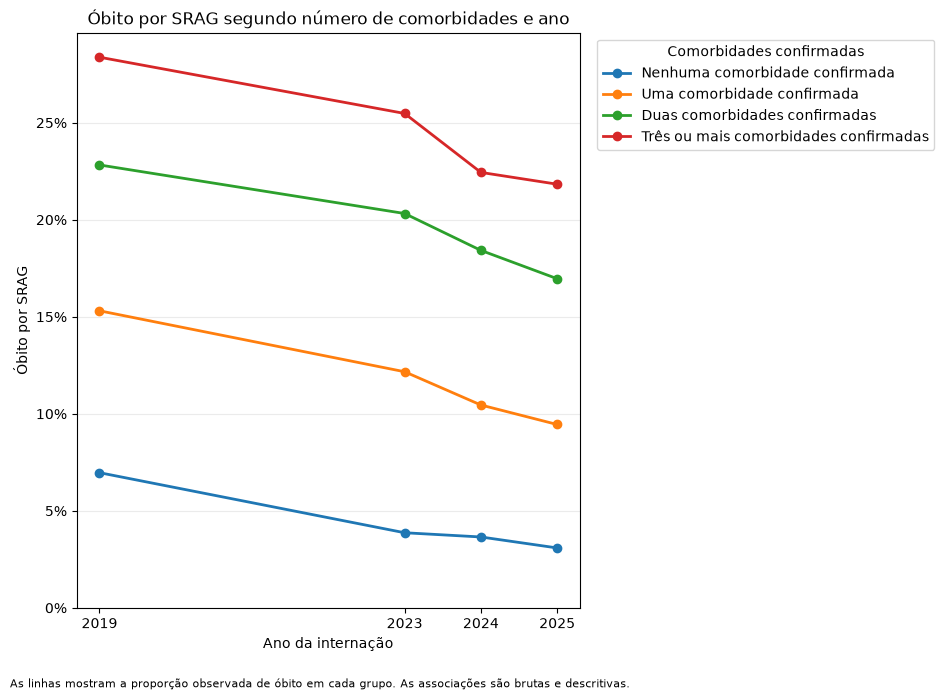

,ano_internacao,grupo_numero_comorbidades,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,Duas comorbidades confirmadas,3273,747,2526,22.823098,21.417623,24.292293
1,2019,Nenhuma comorbidade confirmada,17402,1212,16190,6.964717,6.595935,7.352494
2,2019,Três ou mais comorbidades confirmadas,1533,435,1098,28.375734,26.175224,30.684347
3,2019,Uma comorbidade confirmada,8166,1250,6916,15.307372,14.542760,16.104609
4,2023,Duas comorbidades confirmadas,20442,4154,16288,20.320908,19.774900,20.878068
5,2023,Nenhuma comorbidade confirmada,93502,3618,89884,3.869436,3.747698,3.994964
6,2023,Três ou mais comorbidades confirmadas,11705,2982,8723,25.476292,24.695062,26.273614
7,2023,Uma comorbidade confirmada,40933,4980,35953,12.166223,11.853089,12.486458
8,2024,Duas comorbidades confirmadas,18838,3470,15368,18.420214,17.873106,18.980200
9,2024,Nenhuma comorbidade confirmada,92265,3369,88896,3.651439,3.532328,3.774409


In [87]:
if (
    "grupo_numero_comorbidades"
    not in base_analise_desfecho.columns
):
    raise KeyError(
        "A coluna grupo_numero_comorbidades não está disponível. "
        "Execute primeiro a análise de óbito por comorbidades."
    )

obito_numero_comorbidades_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria=(
            "grupo_numero_comorbidades"
        ),
        nome_categoria_saida=(
            "grupo_numero_comorbidades"
        ),
    )
)

grupos_comorbidades_disponiveis = [
    grupo
    for grupo in ORDEM_NUMERO_COMORBIDADES
    if grupo in set(
        obito_numero_comorbidades_ano[
            "grupo_numero_comorbidades"
        ]
        .astype("string")
        .tolist()
    )
]

figura_obito_comorbidades_ano, eixo_obito_comorbidades_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

for grupo in grupos_comorbidades_disponiveis:
    dados_grupo = (
        obito_numero_comorbidades_ano.loc[
            obito_numero_comorbidades_ano[
                "grupo_numero_comorbidades"
            ]
            .astype("string")
            .eq(
                grupo
            )
        ]
        .sort_values(
            "ano_internacao"
        )
    )

    eixo_obito_comorbidades_ano.plot(
        dados_grupo[
            "ano_internacao"
        ]
        .astype(int),
        dados_grupo[
            "percentual_obito_srag"
        ],
        marker="o",
        linewidth=2,
        label=grupo,
    )

anos_comorbidades_obito = (
    obito_numero_comorbidades_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_obito_comorbidades_ano.set_title(
    "Óbito por SRAG segundo número de comorbidades e ano"
)

eixo_obito_comorbidades_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_comorbidades_ano.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_comorbidades_ano.set_xticks(
    anos_comorbidades_obito
)

eixo_obito_comorbidades_ano.set_ylim(
    bottom=0
)

eixo_obito_comorbidades_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_comorbidades_ano.legend(
    title="Comorbidades confirmadas",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_obito_comorbidades_ano.grid(
    axis="y",
    alpha=0.25,
)

figura_obito_comorbidades_ano.text(
    0.01,
    0.01,
    (
        "As linhas mostram a proporção observada de óbito em cada "
        "grupo. As associações são brutas e descritivas."
    ),
    fontsize=8,
)

figura_obito_comorbidades_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.8,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_comorbidades_ano
)

display(
    obito_numero_comorbidades_ano.head(20)
)

In [88]:
def exibir_letalidade_sim_nao(
    tabela: pd.DataFrame,
    titulo: str,
    quantidade_indicadores: int,
) -> pd.DataFrame:
    """Exibe a letalidade observada para respostas sim e não."""

    COLUNAS_NECESSARIAS = [
        "coluna",
        "nome_amigavel",
        "quantidade_sim",
        "percentual_obito_sim",
        "quantidade_nao",
        "percentual_obito_nao",
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in tabela.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_grafico = (
        tabela[
            COLUNAS_NECESSARIAS
        ]
        .dropna(
            subset=[
                "percentual_obito_sim",
                "percentual_obito_nao",
            ]
        )
        .copy()
    )

    dados_grafico[
        "diferenca_absoluta_pp"
    ] = (
        dados_grafico[
            "percentual_obito_sim"
        ]
        .sub(
            dados_grafico[
                "percentual_obito_nao"
            ]
        )
        .abs()
    )

    dados_grafico = (
        dados_grafico.sort_values(
            "diferenca_absoluta_pp",
            ascending=False,
        )
        .head(
            quantidade_indicadores
        )
        .sort_values(
            "diferenca_absoluta_pp",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    if dados_grafico.empty:
        raise ValueError(
            "Não existem indicadores válidos para o gráfico."
        )

    dados_grafico[
        "rotulo"
    ] = (
        dados_grafico[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
    )

    mascara_rotulo_vazio = (
        dados_grafico[
            "rotulo"
        ]
        .eq("")
        | dados_grafico[
            "rotulo"
        ]
        .isna()
    )

    dados_grafico.loc[
        mascara_rotulo_vazio,
        "rotulo",
    ] = dados_grafico.loc[
        mascara_rotulo_vazio,
        "coluna",
    ]

    posicoes = np.arange(
        len(
            dados_grafico
        )
    )

    altura_barra = 0.36

    figura, eixo = plt.subplots(
        figsize=(
            12,
            8,
        )
    )

    barras_sim = eixo.barh(
        posicoes
        + altura_barra
        / 2,
        dados_grafico[
            "percentual_obito_sim"
        ],
        height=altura_barra,
        color="tab:red",
        label="Resposta sim",
    )

    barras_nao = eixo.barh(
        posicoes
        - altura_barra
        / 2,
        dados_grafico[
            "percentual_obito_nao"
        ],
        height=altura_barra,
        color="tab:blue",
        label="Resposta não",
    )

    eixo.set_yticks(
        posicoes
    )

    eixo.set_yticklabels(
        dados_grafico[
            "rotulo"
        ]
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Óbito por SRAG"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    eixo.xaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )

    eixo.legend()

    eixo.grid(
        axis="x",
        alpha=0.25,
    )

    for barras in [
        barras_sim,
        barras_nao,
    ]:
        for barra in barras:
            valor = (
                barra.get_width()
            )

            eixo.text(
                valor,
                barra.get_y()
                + barra.get_height()
                / 2,
                f"{valor:.1f}%",
                va="center",
                ha="left",
                fontsize=8,
            )

    figura.text(
        0.01,
        0.01,
        (
            "Denominadores específicos de cada resposta estão "
            "disponíveis na tabela exibida abaixo do gráfico."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.04,
            1,
            1,
        ]
    )

    plt.show()

    plt.close(
        figura
    )

    return dados_grafico

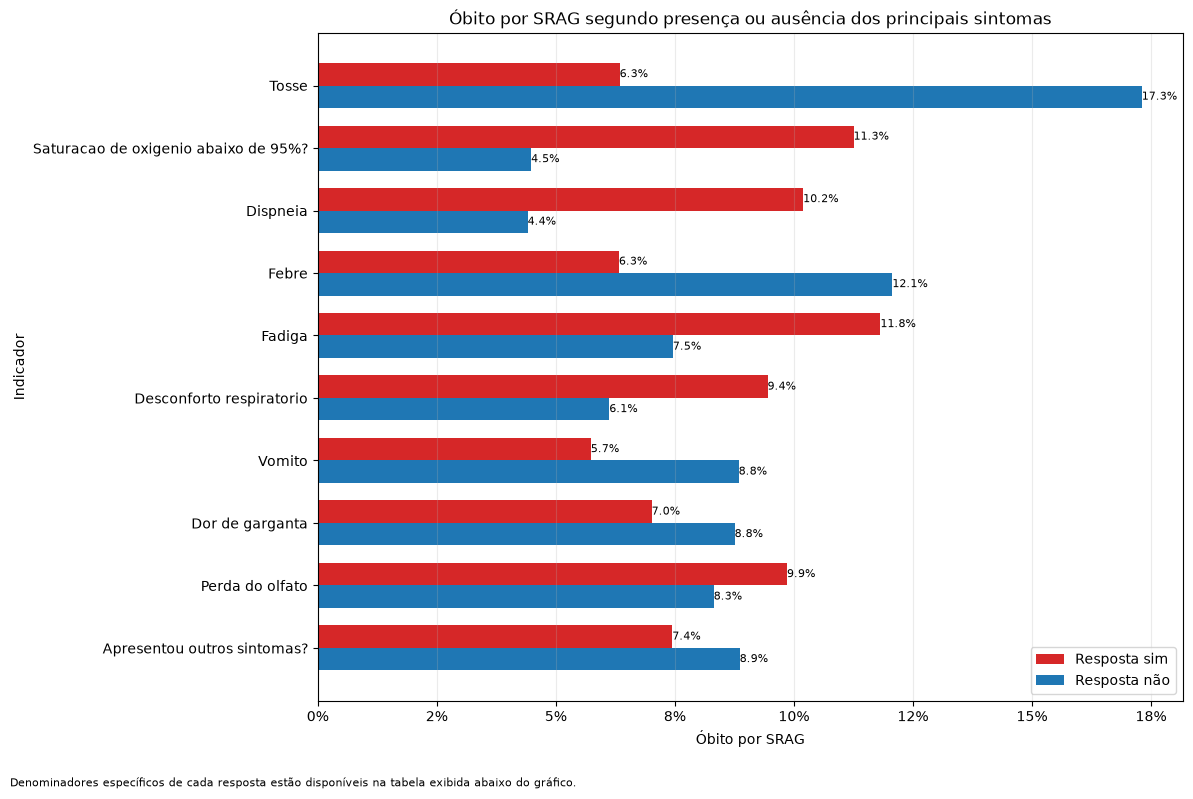

,coluna,rotulo,quantidade_sim,percentual_obito_sim,quantidade_nao,percentual_obito_nao,diferenca_absoluta_pp
0,outro_sin,Apresentou outros sintomas?,152524,7.446697,260823,8.861949,1.415252
1,perd_olft,Perda do olfato,6149,9.855261,376840,8.316262,1.538999
2,garganta,Dor de garganta,61025,7.013519,362153,8.755139,1.741620
3,vomito,Vomito,67719,5.735466,367421,8.840268,3.104802
4,desc_resp,Desconforto respiratorio,375709,9.447471,119405,6.122859,3.324612
5,fadiga,Fadiga,88210,11.818388,316484,7.458513,4.359875
6,febre,Febre,349702,6.325100,152051,12.068977,5.743877
7,dispneia,Dispneia,375282,10.195266,126086,4.408102,5.787164
8,saturacao,Saturacao de oxigenio abaixo de 95%?,307448,11.253285,171255,4.481621,6.771664
9,tosse,Tosse,446075,6.340862,78495,17.306835,10.965973


In [89]:
letalidade_sintomas_grafico = (
    exibir_letalidade_sim_nao(
        tabela=obito_sintomas,
        titulo=(
            "Óbito por SRAG segundo presença ou ausência "
            "dos principais sintomas"
        ),
        quantidade_indicadores=10,
    )
)

display(
    letalidade_sintomas_grafico[
        [
            "coluna",
            "rotulo",
            "quantidade_sim",
            "percentual_obito_sim",
            "quantidade_nao",
            "percentual_obito_nao",
            "diferenca_absoluta_pp",
        ]
    ]
)

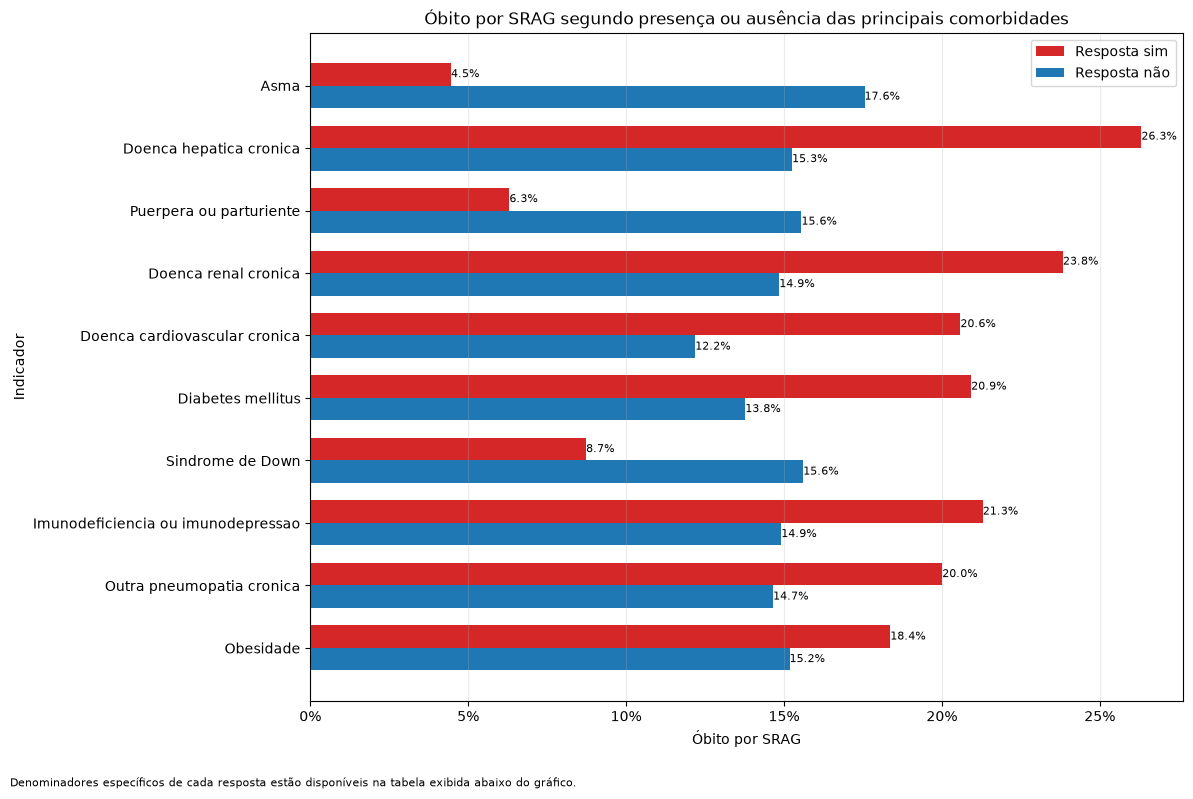

,coluna,rotulo,quantidade_sim,percentual_obito_sim,quantidade_nao,percentual_obito_nao,diferenca_absoluta_pp
0,obesidade,Obesidade,11559,18.366641,154783,15.178023,3.188617
1,pneumopati,Outra pneumopatia cronica,29836,20.012736,143695,14.656042,5.356694
2,imunodepre,Imunodeficiencia ou imunodepressao,14857,21.296359,156447,14.914955,6.381403
3,sind_down,Sindrome de Down,4683,8.733718,163565,15.609696,6.875979
4,diabetes,Diabetes mellitus,51867,20.928529,129099,13.776249,7.152280
5,cardiopati,Doenca cardiovascular cronica,85084,20.587890,104716,12.190114,8.397775
6,renal,Doenca renal cronica,12880,23.835404,156373,14.852948,8.982456
7,puerpera,Puerpera ou parturiente,1364,6.304985,164823,15.554261,9.249276
8,hepatica,Doenca hepatica cronica,3070,26.319218,164140,15.257707,11.061511
9,asma,Asma,39311,4.456768,137899,17.551251,13.094483


In [90]:
letalidade_comorbidades_grafico = (
    exibir_letalidade_sim_nao(
        tabela=obito_comorbidades,
        titulo=(
            "Óbito por SRAG segundo presença ou ausência "
            "das principais comorbidades"
        ),
        quantidade_indicadores=10,
    )
)

display(
    letalidade_comorbidades_grafico[
        [
            "coluna",
            "rotulo",
            "quantidade_sim",
            "percentual_obito_sim",
            "quantidade_nao",
            "percentual_obito_nao",
            "diferenca_absoluta_pp",
        ]
    ]
)

In [91]:
if "ORDEM_SEXO" not in globals():
    raise NameError(
        "A ordem centralizada das categorias de sexo não foi criada. "
        "Execute primeiro a seção demográfica."
    )

if not ORDEM_SEXO:
    raise ValueError(
        "A ordem centralizada das categorias de sexo está vazia."
    )

PALETA_SEXO = [
    "tab:blue",
    "tab:orange",
    "tab:gray",
    "tab:red",
    "tab:purple",
    "tab:brown",
]

if len(ORDEM_SEXO) > len(PALETA_SEXO):
    raise ValueError(
        "A quantidade de categorias de sexo excede a paleta disponível: "
        f"{len(ORDEM_SEXO)} categorias para {len(PALETA_SEXO)} cores."
    )

CORES_SEXO = {
    categoria: PALETA_SEXO[posicao]
    for posicao, categoria in enumerate(ORDEM_SEXO)
}

COLUNAS_SEXO_NECESSARIAS = [
    "sexo_categoria",
]

colunas_sexo_ausentes_coorte = [
    coluna
    for coluna in COLUNAS_SEXO_NECESSARIAS
    if coluna not in coorte.columns
]

if colunas_sexo_ausentes_coorte:
    raise KeyError(
        "A coorte não contém as colunas necessárias "
        "para os gráficos de sexo: "
        f"{colunas_sexo_ausentes_coorte}"
    )

colunas_sexo_ausentes_desfecho = [
    coluna
    for coluna in COLUNAS_SEXO_NECESSARIAS
    if coluna not in base_analise_desfecho.columns
]

if colunas_sexo_ausentes_desfecho:
    raise KeyError(
        "A base da análise do desfecho não contém "
        "as colunas necessárias para os gráficos de sexo: "
        f"{colunas_sexo_ausentes_desfecho}"
    )

categorias_observadas_coorte = set(
    coorte[
        "sexo_categoria"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

categorias_observadas_desfecho = set(
    base_analise_desfecho[
        "sexo_categoria"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

categorias_sexo_presentes_coorte = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in categorias_observadas_coorte
]

categorias_sexo_presentes_desfecho = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in categorias_observadas_desfecho
]

categorias_nao_previstas_coorte = sorted(
    categoria
    for categoria in categorias_observadas_coorte
    if categoria not in ORDEM_SEXO
)

categorias_nao_previstas_desfecho = sorted(
    categoria
    for categoria in categorias_observadas_desfecho
    if categoria not in ORDEM_SEXO
)

if categorias_nao_previstas_coorte:
    raise ValueError(
        "Foram encontradas categorias de sexo não previstas "
        "na coorte: "
        f"{categorias_nao_previstas_coorte}"
    )

if categorias_nao_previstas_desfecho:
    raise ValueError(
        "Foram encontradas categorias de sexo não previstas "
        "na base da análise do desfecho: "
        f"{categorias_nao_previstas_desfecho}"
    )

if not categorias_sexo_presentes_coorte:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na coorte."
    )

if not categorias_sexo_presentes_desfecho:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na base da análise do desfecho."
    )

print(
    "Categorias presentes na coorte:",
    categorias_sexo_presentes_coorte,
)

print(
    "Categorias presentes na análise do desfecho:",
    categorias_sexo_presentes_desfecho,
)

Categorias presentes na coorte: ['feminino', 'ignorado', 'masculino']
Categorias presentes na análise do desfecho: ['feminino', 'ignorado', 'masculino']


In [92]:
resumo_sexo_observado = (
    coorte.groupby(
        "sexo_categoria",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "sexo_categoria",
            "size",
        ),
    )
    .reset_index()
)

resumo_sexo_observado[
    "percentual_coorte"
] = (
    resumo_sexo_observado[
        "quantidade_registros"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

resumo_sexo_observado = (
    resumo_sexo_observado.sort_values(
        "quantidade_registros",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    resumo_sexo_observado
)

,sexo_categoria,quantidade_registros,percentual_coorte
0,masculino,2073315,53.370918
1,feminino,1810867,46.615027
2,ignorado,546,0.014055


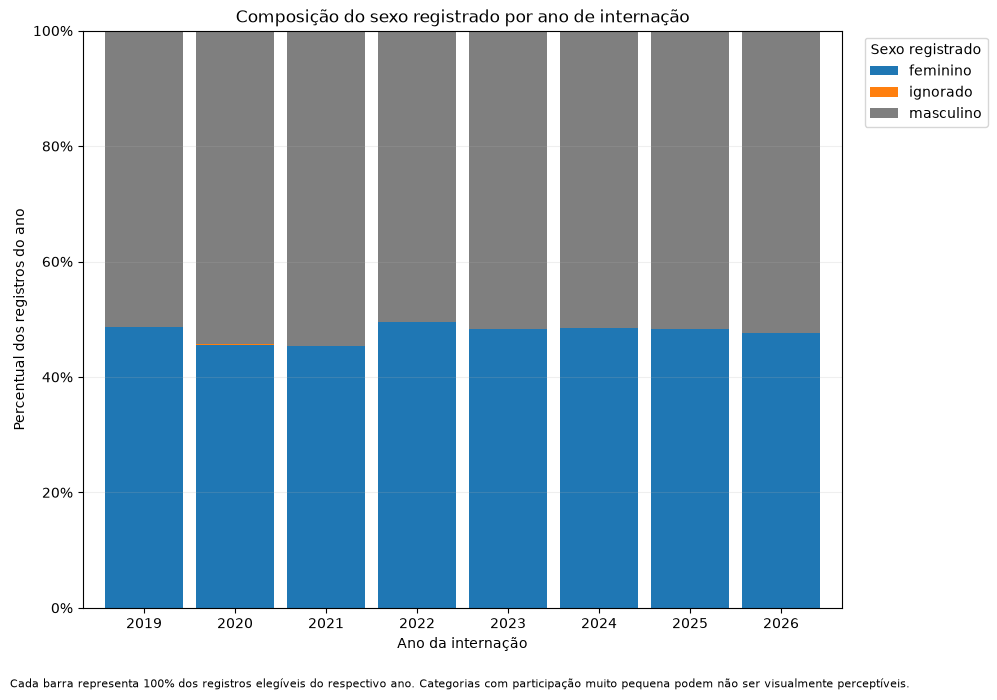

,ano_internacao,sexo_categoria,quantidade,percentual_ano
0,2019,feminino,21110,48.649521
1,2019,ignorado,12,0.027655
2,2019,masculino,22270,51.322824
3,2020,feminino,444414,45.608288
4,2020,ignorado,216,0.022167
5,2020,masculino,529785,54.369545
6,2021,feminino,666186,45.285166
7,2021,ignorado,175,0.011896
8,2021,masculino,804730,54.702938
9,2022,feminino,232830,49.504277


In [93]:
sexo_grafico = (
    sexo_por_ano.pivot(
        index="ano_internacao",
        columns="sexo_categoria",
        values="percentual_ano",
    )
    .reindex(
        columns=(
            categorias_sexo_presentes_coorte
        )
    )
    .fillna(0)
    .sort_index()
)

cores_composicao_sexo = [
    CORES_SEXO[
        categoria
    ]
    for categoria in sexo_grafico.columns
]

figura_sexo_ano, eixo_sexo_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

sexo_grafico.plot(
    kind="bar",
    stacked=True,
    width=0.85,
    color=cores_composicao_sexo,
    ax=eixo_sexo_ano,
)

eixo_sexo_ano.set_title(
    "Composição do sexo registrado por ano de internação"
)

eixo_sexo_ano.set_xlabel(
    "Ano da internação"
)

eixo_sexo_ano.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_sexo_ano.set_ylim(
    0,
    100,
)

eixo_sexo_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_sexo_ano.set_xticklabels(
    eixo_sexo_ano.get_xticklabels(),
    rotation=0,
)

eixo_sexo_ano.legend(
    title="Sexo registrado",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_sexo_ano.grid(
    axis="y",
    alpha=0.20,
)

figura_sexo_ano.text(
    0.01,
    0.01,
    (
        "Cada barra representa 100% dos registros elegíveis "
        "do respectivo ano. Categorias com participação muito "
        "pequena podem não ser visualmente perceptíveis."
    ),
    fontsize=8,
)

figura_sexo_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.84,
        1,
    ]
)

plt.show()

plt.close(
    figura_sexo_ano
)

display(
    sexo_por_ano.loc[
        sexo_por_ano[
            "sexo_categoria"
        ]
        .isin(
            categorias_sexo_presentes_coorte
        )
    ]
    .sort_values(
        [
            "ano_internacao",
            "sexo_categoria",
        ]
    )
    .reset_index(drop=True)
)

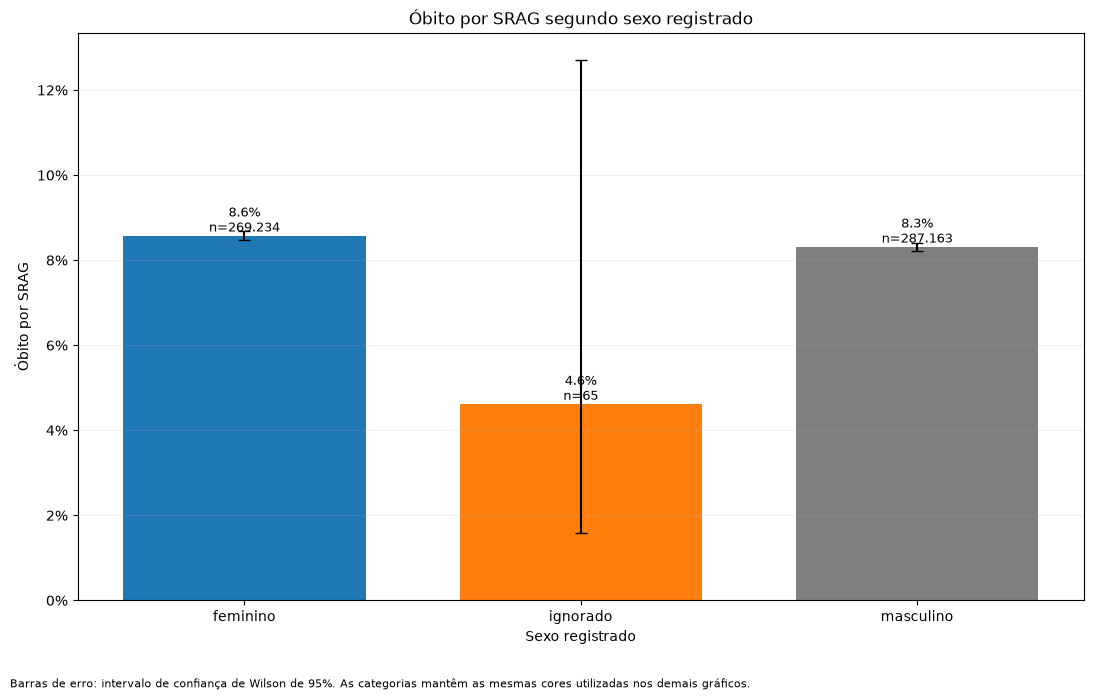

,sexo_categoria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,feminino,269234,23084,246150,8.573954,8.468788,8.680303
1,ignorado,65,3,62,4.615385,1.581984,12.713847
2,masculino,287163,23874,263289,8.313745,8.213322,8.415283


In [94]:
obito_por_sexo = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria="sexo_categoria",
        nome_categoria_saida="sexo_categoria",
    )
)

ordem_sexo_obito = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_SEXO
    )
}

obito_por_sexo[
    "ordem_sexo"
] = (
    obito_por_sexo[
        "sexo_categoria"
    ]
    .astype("string")
    .map(
        ordem_sexo_obito
    )
    .fillna(
        len(
            ordem_sexo_obito
        )
    )
)

obito_por_sexo = (
    obito_por_sexo.loc[
        obito_por_sexo[
            "sexo_categoria"
        ]
        .astype("string")
        .isin(
            categorias_sexo_presentes_desfecho
        )
    ]
    .sort_values(
        "ordem_sexo"
    )
    .drop(
        columns=[
            "ordem_sexo",
        ]
    )
    .reset_index(drop=True)
)

dados_obito_sexo_grafico = (
    obito_por_sexo.loc[
        obito_por_sexo[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

posicoes_sexo = np.arange(
    len(
        dados_obito_sexo_grafico
    )
)

percentuais_obito_sexo = (
    dados_obito_sexo_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_sexo = (
    dados_obito_sexo_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_obito_sexo_grafico[
            "ic95_inferior"
        ]
    )
    .clip(
        lower=0
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_sexo = (
    dados_obito_sexo_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_obito_sexo_grafico[
            "percentual_obito_srag"
        ]
    )
    .clip(
        lower=0
    )
    .astype(float)
    .to_numpy()
)

cores_obito_sexo = [
    CORES_SEXO[
        categoria
    ]
    for categoria in dados_obito_sexo_grafico[
        "sexo_categoria"
    ]
]

figura_obito_sexo, eixo_obito_sexo = plt.subplots(
    figsize=(
        11,
        7,
    )
)

barras_obito_sexo = eixo_obito_sexo.bar(
    posicoes_sexo,
    percentuais_obito_sexo,
    color=cores_obito_sexo,
    width=0.72,
)

eixo_obito_sexo.errorbar(
    posicoes_sexo,
    percentuais_obito_sexo,
    yerr=[
        erros_inferiores_sexo,
        erros_superiores_sexo,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_sexo.set_xticks(
    posicoes_sexo
)

eixo_obito_sexo.set_xticklabels(
    dados_obito_sexo_grafico[
        "sexo_categoria"
    ]
)

eixo_obito_sexo.set_title(
    "Óbito por SRAG segundo sexo registrado"
)

eixo_obito_sexo.set_xlabel(
    "Sexo registrado"
)

eixo_obito_sexo.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_sexo.set_ylim(
    bottom=0
)

eixo_obito_sexo.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_sexo.grid(
    axis="y",
    alpha=0.20,
)

for barra, percentual, quantidade in zip(
    barras_obito_sexo,
    percentuais_obito_sexo,
    dados_obito_sexo_grafico[
        "quantidade_total"
    ],
):
    quantidade_formatada = (
        f"{int(quantidade):,}"
        .replace(
            ",",
            ".",
        )
    )

    eixo_obito_sexo.text(
        barra.get_x()
        + barra.get_width()
        / 2,
        barra.get_height(),
        (
            f"{percentual:.1f}%\n"
            f"n={quantidade_formatada}"
        ),
        ha="center",
        va="bottom",
        fontsize=9,
    )

figura_obito_sexo.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        "As categorias mantêm as mesmas cores utilizadas "
        "nos demais gráficos."
    ),
    fontsize=8,
)

figura_obito_sexo.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_sexo
)

display(
    obito_por_sexo
)

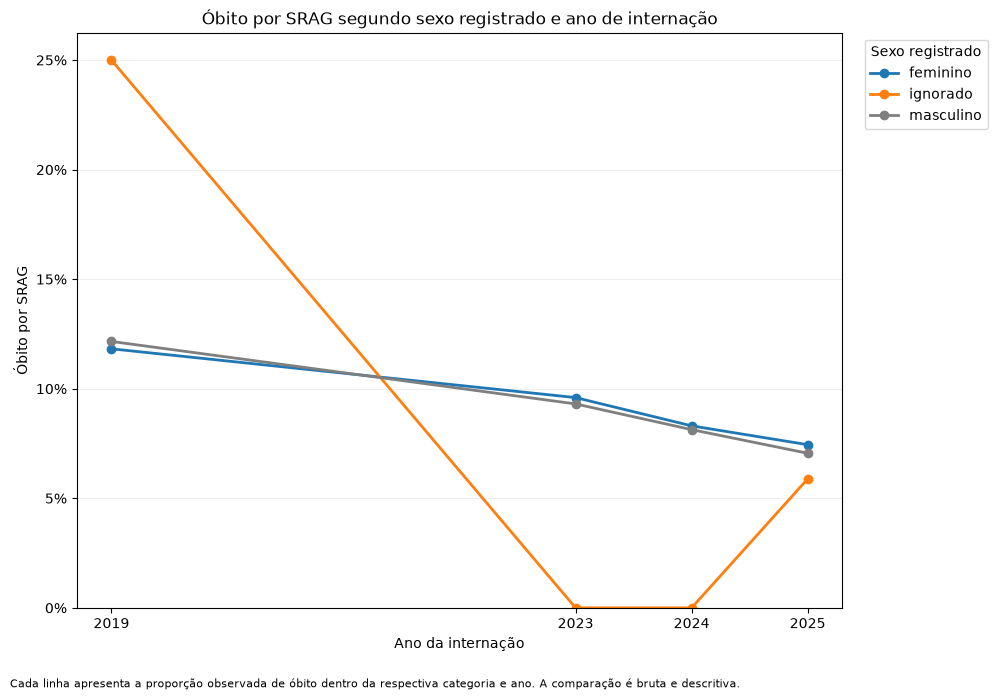

,ano_internacao,sexo_categoria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,feminino,14787,1748,13039,11.821194,1.131070e+01,12.351517
1,2019,ignorado,8,2,6,25.0,7.147921e+00,59.072457
2,2019,masculino,15579,1894,13685,12.157391,1.165354e+01,12.679900
3,2023,feminino,80489,7723,72766,9.5951,9.393554e+00,9.800503
4,2023,ignorado,14,0,14,0.0,2.177950e-15,21.531080
5,2023,masculino,86079,8011,78068,9.306567,9.114298e+00,9.502468
6,2024,feminino,76855,6383,70472,8.30525,8.112226e+00,8.502442
7,2024,ignorado,26,0,26,0.0,0.000000e+00,12.872892
8,2024,masculino,81841,6656,75185,8.132843,7.947534e+00,8.322082
9,2025,feminino,97103,7230,89873,7.445702,7.282266e+00,7.612504


In [95]:
COLUNAS_OBITO_SEXO_ANO_NECESSARIAS = [
    "ano_internacao",
    "sexo_categoria",
    "alvo_obito_srag",
]

colunas_obito_sexo_ano_ausentes = [
    coluna
    for coluna in COLUNAS_OBITO_SEXO_ANO_NECESSARIAS
    if coluna not in base_analise_desfecho.columns
]

if colunas_obito_sexo_ano_ausentes:
    raise KeyError(
        "A base da análise do desfecho não contém "
        "as colunas necessárias para calcular óbito "
        "por sexo e ano: "
        f"{colunas_obito_sexo_ano_ausentes}"
    )

if "categorias_sexo_presentes_desfecho" not in globals():
    raise NameError(
        "A lista categorias_sexo_presentes_desfecho "
        "não foi criada. Execute primeiro a célula de "
        "configuração das categorias de sexo."
    )

if not categorias_sexo_presentes_desfecho:
    raise ValueError(
        "Nenhuma categoria de sexo está disponível "
        "para a análise anual do desfecho."
    )

obito_sexo_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria="sexo_categoria",
        nome_categoria_saida="sexo_categoria",
    )
)

obito_sexo_ano = (
    obito_sexo_ano.loc[
        obito_sexo_ano[
            "sexo_categoria"
        ]
        .astype("string")
        .isin(
            categorias_sexo_presentes_desfecho
        )
    ]
    .copy()
)

ordem_sexo_ano = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_SEXO
    )
}

obito_sexo_ano[
    "ordem_sexo"
] = (
    obito_sexo_ano[
        "sexo_categoria"
    ]
    .astype("string")
    .map(
        ordem_sexo_ano
    )
    .fillna(
        len(
            ordem_sexo_ano
        )
    )
)

obito_sexo_ano = (
    obito_sexo_ano
    .sort_values(
        [
            "ano_internacao",
            "ordem_sexo",
        ]
    )
    .drop(
        columns=[
            "ordem_sexo",
        ]
    )
    .reset_index(drop=True)
)

if obito_sexo_ano.empty:
    raise ValueError(
        "A tabela de óbito por sexo e ano está vazia."
    )

percentuais_obito_sexo_ano_validos = (
    obito_sexo_ano[
        "percentual_obito_srag"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_obito_sexo_ano_validos:
    raise RuntimeError(
        "A tabela de óbito por sexo e ano contém "
        "percentuais fora do intervalo de 0% a 100%."
    )

categorias_obito_sexo_ano = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in set(
        obito_sexo_ano[
            "sexo_categoria"
        ]
        .astype("string")
        .tolist()
    )
]

if not categorias_obito_sexo_ano:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na tabela anual do desfecho."
    )

figura_obito_sexo_ano, eixo_obito_sexo_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

for categoria in categorias_obito_sexo_ano:
    dados_categoria = (
        obito_sexo_ano.loc[
            obito_sexo_ano[
                "sexo_categoria"
            ]
            .astype("string")
            .eq(
                categoria
            )
        ]
        .sort_values(
            "ano_internacao"
        )
        .copy()
    )

    if dados_categoria.empty:
        continue

    eixo_obito_sexo_ano.plot(
        dados_categoria[
            "ano_internacao"
        ]
        .astype(int),
        dados_categoria[
            "percentual_obito_srag"
        ],
        marker="o",
        linewidth=2,
        color=CORES_SEXO[
            categoria
        ],
        label=categoria,
    )

anos_obito_sexo = (
    obito_sexo_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_obito_sexo_ano.set_title(
    "Óbito por SRAG segundo sexo registrado e ano de internação"
)

eixo_obito_sexo_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_sexo_ano.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_sexo_ano.set_xticks(
    anos_obito_sexo
)

eixo_obito_sexo_ano.set_ylim(
    bottom=0
)

eixo_obito_sexo_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_sexo_ano.legend(
    title="Sexo registrado",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_obito_sexo_ano.grid(
    axis="y",
    alpha=0.20,
)

figura_obito_sexo_ano.text(
    0.01,
    0.01,
    (
        "Cada linha apresenta a proporção observada de óbito "
        "dentro da respectiva categoria e ano. "
        "A comparação é bruta e descritiva."
    ),
    fontsize=8,
)

figura_obito_sexo_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.84,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_sexo_ano
)

display(
    obito_sexo_ano
)

In [96]:
COLUNAS_SERIE_MENSAL_NECESSARIAS = [
    "dt_interna_convertida",
    "ano_internacao",
    "alvo_obito_srag",
]

colunas_serie_mensal_ausentes = [
    coluna
    for coluna in COLUNAS_SERIE_MENSAL_NECESSARIAS
    if coluna not in coorte.columns
]

if colunas_serie_mensal_ausentes:
    raise KeyError(
        "A coorte não contém as colunas necessárias "
        "para a análise mensal: "
        f"{colunas_serie_mensal_ausentes}"
    )


data_internacao_mensal_arrow = pd.to_datetime(
    coorte[
        "dt_interna_convertida"
    ],
    errors="coerce",
)

data_internacao_mensal = pd.Series(
    data_internacao_mensal_arrow.to_numpy(
        dtype="datetime64[ns]",
        na_value=np.datetime64("NaT","ns"),
        copy=False,
    ),
    index=coorte.index,
    name="dt_interna_convertida",
    dtype="datetime64[ns]",
)

del data_internacao_mensal_arrow

quantidade_datas_mensais_ausentes = int(
    data_internacao_mensal
    .isna()
    .sum()
)

if quantidade_datas_mensais_ausentes > 0:
    raise ValueError(
        "Existem datas de internação ausentes ou inválidas "
        "na coorte analítica: "
        f"{quantidade_datas_mensais_ausentes}"
    )

if not coorte[
    "alvo_obito_srag"
].isin(
    [
        0,
        1,
    ]
).all():
    raise ValueError(
        "A coluna alvo_obito_srag contém valores "
        "diferentes de zero e um."
    )

ano_data_internacao = (
    data_internacao_mensal
    .dt.year
    .astype("Int64")
)

ano_coorte = (
    pd.to_numeric(
        coorte[
            "ano_internacao"
        ],
        errors="coerce",
    )
    .astype("Int64")
)

mascara_ano_divergente = (
    ano_data_internacao.ne(
        ano_coorte
    )
)

quantidade_anos_divergentes = int(
    mascara_ano_divergente
    .fillna(True)
    .sum()
)

if quantidade_anos_divergentes > 0:
    raise RuntimeError(
        "O ano extraído de dt_interna_convertida diverge "
        "de ano_internacao em "
        f"{quantidade_anos_divergentes} registros."
    )

coorte[
    "mes_internacao"
] = (
    data_internacao_mensal
    .dt.month
    .astype("Int8")
)

coorte[
    "ano_mes_internacao"
] = (
    data_internacao_mensal
    .dt.to_period("M")
    .dt.to_timestamp()
)

if not coorte[
    "mes_internacao"
].between(
    1,
    12,
    inclusive="both",
).all():
    raise RuntimeError(
        "Foram identificados meses fora do intervalo "
        "de janeiro a dezembro."
    )

data_minima_internacao = (
    data_internacao_mensal.min()
)

data_maxima_internacao = (
    data_internacao_mensal.max()
)

primeiro_mes_observado = (
    data_minima_internacao
    .to_period("M")
    .to_timestamp()
)

ultimo_mes_observado = (
    data_maxima_internacao
    .to_period("M")
    .to_timestamp()
)

ultimo_dia_mes_maximo = (
    ultimo_mes_observado
    + pd.offsets.MonthEnd(0)
)

ultimo_mes_completo = (
    data_maxima_internacao.normalize()
    >= ultimo_dia_mes_maximo.normalize()
)

calendario_mensal = pd.DataFrame(
    {
        "ano_mes_internacao": pd.date_range(
            start=primeiro_mes_observado,
            end=ultimo_mes_observado,
            freq="MS",
        ),
    }
)

calendario_mensal[
    "ano_internacao"
] = (
    calendario_mensal[
        "ano_mes_internacao"
    ]
    .dt.year
    .astype("Int64")
)

calendario_mensal[
    "mes_internacao"
] = (
    calendario_mensal[
        "ano_mes_internacao"
    ]
    .dt.month
    .astype("Int8")
)

calendario_mensal[
    "mes_observado"
] = True

calendario_mensal[
    "mes_completo"
] = True

if not ultimo_mes_completo:
    calendario_mensal.loc[
        calendario_mensal[
            "ano_mes_internacao"
        ].eq(
            ultimo_mes_observado
        ),
        "mes_completo",
    ] = False

contagem_alvo_mensal = (
    coorte.groupby(
        [
            "ano_mes_internacao",
            "alvo_obito_srag",
        ],
        dropna=False,
    )
    .size()
    .unstack(
        fill_value=0
    )
)

contagem_alvo_mensal = (
    contagem_alvo_mensal.reindex(
        columns=[
            0,
            1,
        ],
        fill_value=0,
    )
    .rename(
        columns={
            0: "quantidade_cura",
            1: "quantidade_obito_srag",
        }
    )
    .reset_index()
)

serie_mensal = (
    calendario_mensal.merge(
        contagem_alvo_mensal,
        on="ano_mes_internacao",
        how="left",
        validate="one_to_one",
    )
)

COLUNAS_CONTAGEM_MENSAL = [
    "quantidade_cura",
    "quantidade_obito_srag",
]

for coluna in COLUNAS_CONTAGEM_MENSAL:
    serie_mensal[
        coluna
    ] = (
        pd.to_numeric(
            serie_mensal[
                coluna
            ],
            errors="coerce",
        )
        .fillna(0)
        .astype("int64")
    )

serie_mensal[
    "quantidade_registros"
] = (
    serie_mensal[
        "quantidade_cura"
    ]
    .add(
        serie_mensal[
            "quantidade_obito_srag"
        ]
    )
    .astype("int64")
)

serie_mensal[
    "percentual_cura"
] = (
    serie_mensal[
        "quantidade_cura"
    ]
    .div(
        serie_mensal[
            "quantidade_registros"
        ]
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

serie_mensal[
    "percentual_obito_srag"
] = (
    serie_mensal[
        "quantidade_obito_srag"
    ]
    .div(
        serie_mensal[
            "quantidade_registros"
        ]
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

serie_mensal[
    "rotulo_ano_mes"
] = (
    serie_mensal[
        "ano_mes_internacao"
    ]
    .dt.strftime(
        "%Y-%m"
    )
)

serie_mensal = (
    serie_mensal[
        [
            "ano_mes_internacao",
            "rotulo_ano_mes",
            "ano_internacao",
            "mes_internacao",
            "mes_observado",
            "mes_completo",
            "quantidade_registros",
            "quantidade_cura",
            "quantidade_obito_srag",
            "percentual_cura",
            "percentual_obito_srag",
        ]
    ]
    .sort_values(
        "ano_mes_internacao"
    )
    .reset_index(drop=True)
)

total_registros_serie_mensal = int(
    serie_mensal[
        "quantidade_registros"
    ]
    .sum()
)

if total_registros_serie_mensal != len(
    coorte
):
    raise RuntimeError(
        "A soma mensal dos registros não corresponde "
        "ao total da coorte."
    )

total_obitos_serie_mensal = int(
    serie_mensal[
        "quantidade_obito_srag"
    ]
    .sum()
)

total_obitos_coorte = int(
    coorte[
        "alvo_obito_srag"
    ]
    .sum()
)

if total_obitos_serie_mensal != total_obitos_coorte:
    raise RuntimeError(
        "A soma mensal dos óbitos não corresponde "
        "ao total de óbitos da coorte."
    )

percentuais_mensais_validos = (
    serie_mensal[
        "percentual_obito_srag"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_mensais_validos:
    raise RuntimeError(
        "A série mensal contém percentuais de óbito "
        "fora do intervalo de 0% a 100%."
    )

meses_sem_registros = (
    serie_mensal.loc[
        serie_mensal[
            "quantidade_registros"
        ].eq(0),
        "rotulo_ano_mes",
    ]
    .tolist()
)

print(
    "Primeiro mês observado:",
    primeiro_mes_observado.strftime(
        "%Y-%m"
    ),
)

print(
    "Último mês observado:",
    ultimo_mes_observado.strftime(
        "%Y-%m"
    ),
)

print(
    "Data máxima de internação:",
    data_maxima_internacao.strftime(
        "%Y-%m-%d"
    ),
)

print(
    "Último mês está completo:",
    bool(
        ultimo_mes_completo
    ),
)

print(
    "Quantidade de meses no calendário:",
    len(
        serie_mensal
    ),
)

print(
    "Meses sem registros:",
    len(
        meses_sem_registros
    ),
)

if meses_sem_registros:
    print(
        "Lista de meses sem registros:",
        meses_sem_registros,
    )

display(
    serie_mensal
)

Primeiro mês observado: 2019-01
Último mês observado: 2026-09
Data máxima de internação: 2026-09-25
Último mês está completo: False
Quantidade de meses no calendário: 93
Meses sem registros: 0


,ano_mes_internacao,rotulo_ano_mes,ano_internacao,mes_internacao,mes_observado,mes_completo,quantidade_registros,quantidade_cura,quantidade_obito_srag,percentual_cura,percentual_obito_srag
0,2019-01-01,2019-01,2019,1,True,True,1072,906,166,84.514925,15.485075
1,2019-02-01,2019-02,2019,2,True,True,1698,1494,204,87.985866,12.014134
2,2019-03-01,2019-03,2019,3,True,True,3787,3459,328,91.338791,8.661209
3,2019-04-01,2019-04,2019,4,True,True,5550,4987,563,89.855856,10.144144
4,2019-05-01,2019-05,2019,5,True,True,7505,6627,878,88.301133,11.698867
...,...,...,...,...,...,...,...,...,...,...,...
88,2026-05-01,2026-05,2026,5,True,True,31055,29557,1498,95.176300,4.823700
89,2026-06-01,2026-06,2026,6,True,True,30477,28983,1494,95.097943,4.902057
90,2026-07-01,2026-07,2026,7,True,True,23134,21930,1204,94.795539,5.204461
91,2026-08-01,2026-08,2026,8,True,True,14301,13545,756,94.713656,5.286344


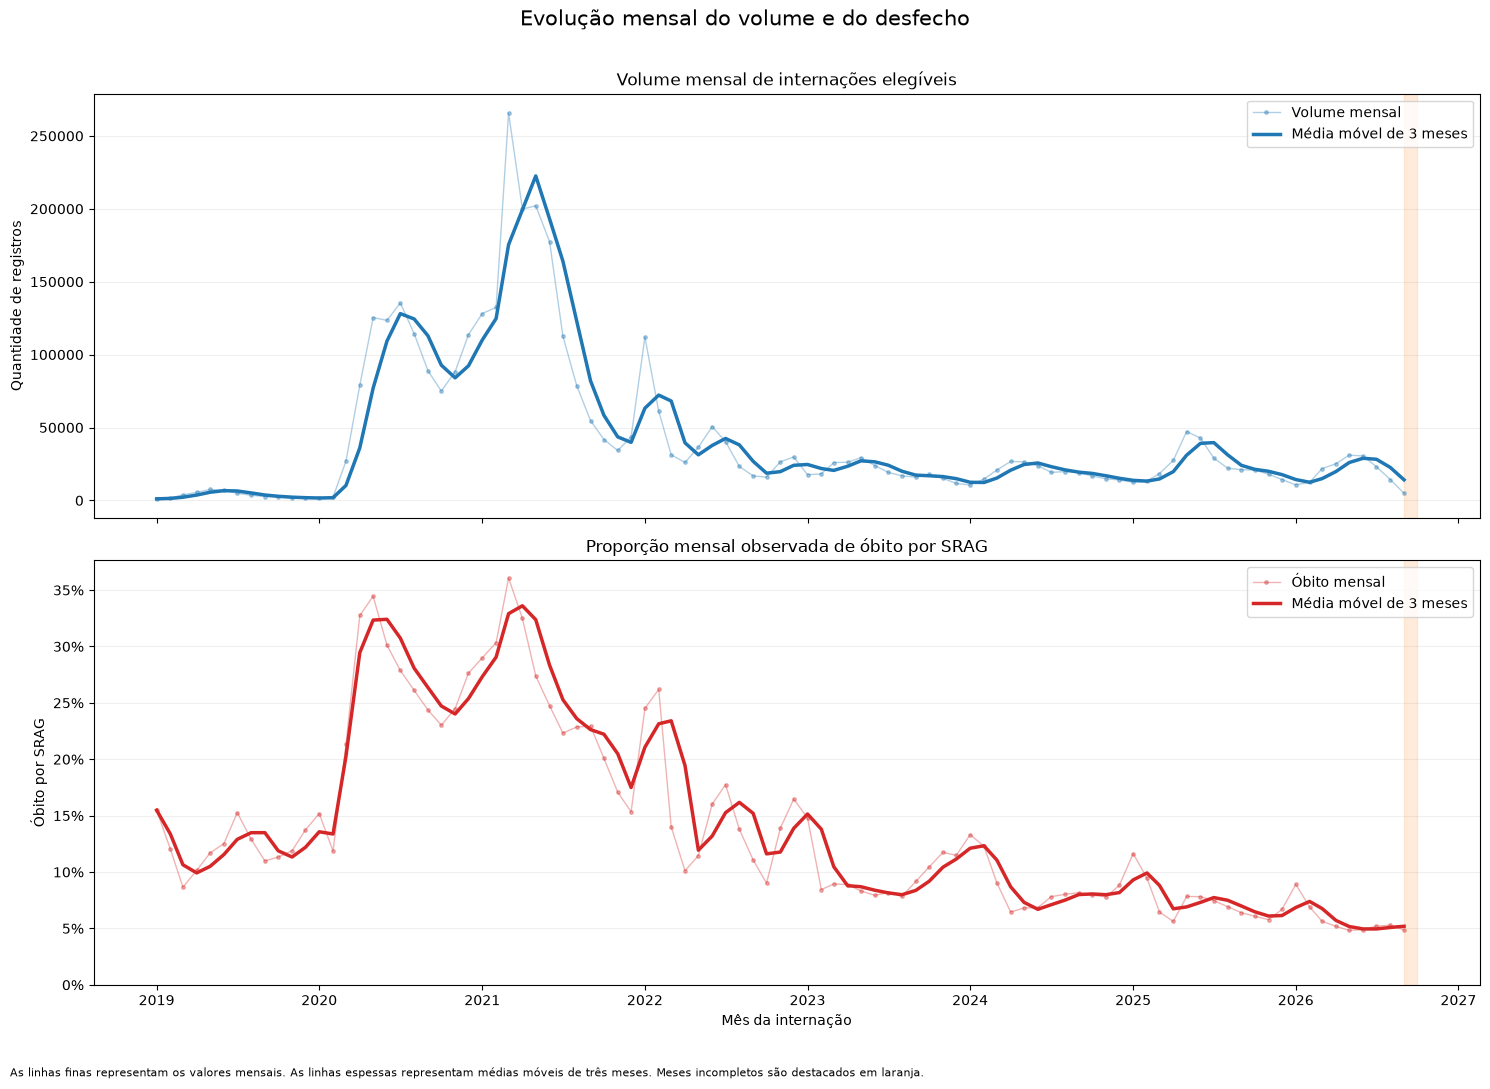

,ano_mes_internacao,mes_completo,quantidade_registros,volume_media_movel_3_meses,percentual_obito_srag,obito_media_movel_3_meses
0,2019-01-01,True,1072,1072.000000,15.485075,15.485075
1,2019-02-01,True,1698,1385.000000,12.014134,13.357401
2,2019-03-01,True,3787,2185.666667,8.661209,10.645112
3,2019-04-01,True,5550,3678.333333,10.144144,9.922972
4,2019-05-01,True,7505,5614.000000,11.698867,10.503503
...,...,...,...,...,...,...
88,2026-05-01,True,31055,26000.333333,4.823700,5.167882
89,2026-06-01,True,30477,28898.333333,4.902057,4.956457
90,2026-07-01,True,23134,28222.000000,5.204461,4.955945
91,2026-08-01,True,14301,22637.333333,5.286344,5.085994


In [97]:
from matplotlib.ticker import FuncFormatter

JANELA_MEDIA_MOVEL_MESES = 3

if "serie_mensal" not in globals():
    raise NameError(
        "A tabela serie_mensal não foi criada. "
        "Execute primeiro a célula de construção da série mensal."
    )

COLUNAS_SERIE_GRAFICO_NECESSARIAS = [
    "ano_mes_internacao",
    "mes_completo",
    "quantidade_registros",
    "quantidade_obito_srag",
    "percentual_obito_srag",
]

colunas_serie_grafico_ausentes = [
    coluna
    for coluna in COLUNAS_SERIE_GRAFICO_NECESSARIAS
    if coluna not in serie_mensal.columns
]

if colunas_serie_grafico_ausentes:
    raise KeyError(
        "A série mensal não contém as colunas necessárias: "
        f"{colunas_serie_grafico_ausentes}"
    )

serie_mensal_grafico = (
    serie_mensal[
        COLUNAS_SERIE_GRAFICO_NECESSARIAS
    ]
    .copy()
    .sort_values(
        "ano_mes_internacao"
    )
    .reset_index(drop=True)
)

serie_mensal_grafico[
    "ano_mes_internacao"
] = pd.to_datetime(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    errors="coerce",
)

if serie_mensal_grafico[
    "ano_mes_internacao"
].isna().any():
    raise ValueError(
        "A série mensal contém referências mensais inválidas."
    )

serie_mensal_grafico[
    "quantidade_registros"
] = pd.to_numeric(
    serie_mensal_grafico[
        "quantidade_registros"
    ],
    errors="coerce",
)

serie_mensal_grafico[
    "quantidade_obito_srag"
] = pd.to_numeric(
    serie_mensal_grafico[
        "quantidade_obito_srag"
    ],
    errors="coerce",
)

if serie_mensal_grafico[
    [
        "quantidade_registros",
        "quantidade_obito_srag",
    ]
].isna().any().any():
    raise ValueError(
        "A série mensal contém contagens não numéricas."
    )

serie_mensal_grafico[
    "volume_media_movel_3_meses"
] = (
    serie_mensal_grafico[
        "quantidade_registros"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .mean()
)

obitos_moveis_3_meses = (
    serie_mensal_grafico[
        "quantidade_obito_srag"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .sum()
)

registros_moveis_3_meses = (
    serie_mensal_grafico[
        "quantidade_registros"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .sum()
)

serie_mensal_grafico[
    "obito_media_movel_3_meses"
] = (
    obitos_moveis_3_meses
    .div(
        registros_moveis_3_meses
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

percentuais_moveis_validos = (
    serie_mensal_grafico[
        "obito_media_movel_3_meses"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_moveis_validos:
    raise RuntimeError(
        "A média móvel do óbito contém valores "
        "fora do intervalo de 0% a 100%."
    )

meses_incompletos = (
    serie_mensal_grafico.loc[
        serie_mensal_grafico[
            "mes_completo"
        ].eq(False),
        "ano_mes_internacao",
    ]
    .tolist()
)

figura_serie_mensal, eixos_serie_mensal = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(
        15,
        11,
    ),
    sharex=True,
)

eixo_volume_mensal = eixos_serie_mensal[0]

eixo_volume_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "quantidade_registros"
    ],
    color="tab:blue",
    linewidth=1,
    marker="o",
    markersize=2.5,
    alpha=0.35,
    label="Volume mensal",
)

eixo_volume_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "volume_media_movel_3_meses"
    ],
    color="tab:blue",
    linewidth=2.5,
    label="Média móvel de 3 meses",
)

eixo_volume_mensal.set_title(
    "Volume mensal de internações elegíveis"
)

eixo_volume_mensal.set_ylabel(
    "Quantidade de registros"
)

eixo_volume_mensal.ticklabel_format(
    style="plain",
    axis="y",
)

eixo_volume_mensal.grid(
    axis="y",
    alpha=0.20,
)

eixo_volume_mensal.legend(
    loc="upper right"
)

eixo_obito_mensal = eixos_serie_mensal[1]

eixo_obito_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "percentual_obito_srag"
    ],
    color="tab:red",
    linewidth=1,
    marker="o",
    markersize=2.5,
    alpha=0.35,
    label="Óbito mensal",
)

eixo_obito_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "obito_media_movel_3_meses"
    ],
    color="tab:red",
    linewidth=2.5,
    label="Média móvel de 3 meses",
)

eixo_obito_mensal.set_title(
    "Proporção mensal observada de óbito por SRAG"
)

eixo_obito_mensal.set_xlabel(
    "Mês da internação"
)

eixo_obito_mensal.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_mensal.set_ylim(
    bottom=0
)

eixo_obito_mensal.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicao: f"{valor:.0f}%"
    )
)

eixo_obito_mensal.grid(
    axis="y",
    alpha=0.20,
)

eixo_obito_mensal.legend(
    loc="upper right"
)

for mes_incompleto in meses_incompletos:
    inicio_mes_incompleto = pd.Timestamp(
        mes_incompleto
    )

    fim_mes_incompleto = (
        inicio_mes_incompleto
        + pd.offsets.MonthEnd(1)
    )

    eixo_volume_mensal.axvspan(
        inicio_mes_incompleto,
        fim_mes_incompleto,
        color="tab:orange",
        alpha=0.15,
    )

    eixo_obito_mensal.axvspan(
        inicio_mes_incompleto,
        fim_mes_incompleto,
        color="tab:orange",
        alpha=0.15,
    )

figura_serie_mensal.suptitle(
    "Evolução mensal do volume e do desfecho",
    fontsize=15,
)

figura_serie_mensal.text(
    0.01,
    0.01,
    (
        "As linhas finas representam os valores mensais. "
        "As linhas espessas representam médias móveis de três meses. "
        "Meses incompletos são destacados em laranja."
    ),
    fontsize=8,
)

figura_serie_mensal.tight_layout(
    rect=(
        0.0,
        0.04,
        1.0,
        0.97,
    )
)

plt.show()

plt.close(
    figura_serie_mensal
)

display(
    serie_mensal_grafico[
        [
            "ano_mes_internacao",
            "mes_completo",
            "quantidade_registros",
            "volume_media_movel_3_meses",
            "percentual_obito_srag",
            "obito_media_movel_3_meses",
        ]
    ]
)

In [98]:
ORDEM_MESES = [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
]

ROTULOS_MESES = [
    "Jan",
    "Fev",
    "Mar",
    "Abr",
    "Mai",
    "Jun",
    "Jul",
    "Ago",
    "Set",
    "Out",
    "Nov",
    "Dez",
]

COLUNAS_MATRIZES_MENSAIS_NECESSARIAS = [
    "ano_internacao",
    "mes_internacao",
    "mes_completo",
    "quantidade_registros",
    "quantidade_obito_srag",
    "percentual_obito_srag",
]

colunas_matrizes_mensais_ausentes = [
    coluna
    for coluna in COLUNAS_MATRIZES_MENSAIS_NECESSARIAS
    if coluna not in serie_mensal.columns
]

if colunas_matrizes_mensais_ausentes:
    raise KeyError(
        "A série mensal não contém as colunas necessárias: "
        f"{colunas_matrizes_mensais_ausentes}"
    )

dados_matrizes_mensais = (
    serie_mensal[
        COLUNAS_MATRIZES_MENSAIS_NECESSARIAS
    ]
    .copy()
)

dados_matrizes_mensais[
    "ano_internacao"
] = pd.to_numeric(
    dados_matrizes_mensais[
        "ano_internacao"
    ],
    errors="coerce",
).astype("Int64")

dados_matrizes_mensais[
    "mes_internacao"
] = pd.to_numeric(
    dados_matrizes_mensais[
        "mes_internacao"
    ],
    errors="coerce",
).astype("Int64")

if dados_matrizes_mensais[
    [
        "ano_internacao",
        "mes_internacao",
    ]
].isna().any().any():
    raise ValueError(
        "A série mensal contém ano ou mês inválido."
    )

if not dados_matrizes_mensais[
    "mes_internacao"
].between(
    1,
    12,
    inclusive="both",
).all():
    raise RuntimeError(
        "A série mensal contém mês fora do intervalo "
        "de janeiro a dezembro."
    )

matriz_volume_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="quantidade_registros",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_obito_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="percentual_obito_srag",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_denominador_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="quantidade_registros",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_mes_completo_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="mes_completo",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_volume_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_obito_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_denominador_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_mes_completo_ano_mes.columns = (
    ROTULOS_MESES
)

if matriz_volume_ano_mes.empty:
    raise ValueError(
        "A matriz mensal de volume está vazia."
    )

if matriz_obito_ano_mes.empty:
    raise ValueError(
        "A matriz mensal de óbito está vazia."
    )

valores_obito_mensais = (
    matriz_obito_ano_mes
    .stack()
    .dropna()
)

if valores_obito_mensais.empty:
    raise ValueError(
        "A matriz mensal de óbito não possui "
        "percentuais válidos."
    )

percentuais_obito_validos = (
    valores_obito_mensais.ge(0)
    & valores_obito_mensais.le(100)
).all()

if not bool(percentuais_obito_validos):
    raise RuntimeError(
        "A matriz mensal de óbito contém percentuais "
        "fora do intervalo de 0% a 100%."
    )

print(
    "Dimensão da matriz de volume:",
    matriz_volume_ano_mes.shape,
)

print(
    "Dimensão da matriz de óbito:",
    matriz_obito_ano_mes.shape,
)

display(
    matriz_volume_ano_mes
)

display(
    matriz_obito_ano_mes
)

Dimensão da matriz de volume: (8, 12)
Dimensão da matriz de óbito: (8, 12)


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano_internacao,,,,,,,,,,,,
2019,1072.0,1698.0,3787.0,5550.0,7505.0,6973.0,4933.0,3546.0,2668.0,2313.0,1716.0,1631.0
2020,1620.0,2327.0,26899.0,78875.0,125425.0,123497.0,135429.0,114420.0,88942.0,75004.0,88288.0,113689.0
2021,128189.0,132364.0,265742.0,199837.0,202076.0,177460.0,112548.0,78665.0,54719.0,41756.0,34240.0,43495.0
2022,112040.0,61181.0,31285.0,26035.0,36483.0,50628.0,40340.0,23277.0,16811.0,15952.0,26455.0,29836.0
2023,17640.0,18156.0,25970.0,26174.0,29323.0,23935.0,19246.0,16855.0,15947.0,17977.0,15104.0,11649.0
2024,10603.0,14624.0,20801.0,26779.0,26355.0,23877.0,19266.0,19747.0,19148.0,16685.0,14864.0,14000.0
2025,12443.0,13284.0,18446.0,27454.0,47247.0,42742.0,28964.0,22090.0,21066.0,20824.0,17988.0,14289.0
2026,10647.0,12434.0,21783.0,25163.0,31055.0,30477.0,23134.0,14301.0,4951.0,NaN,NaN,NaN


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano_internacao,,,,,,,,,,,,
2019,15.485075,12.014134,8.661209,10.144144,11.698867,12.519719,15.264545,12.915962,10.982009,11.327281,11.888112,13.733906
2020,15.185185,11.860765,21.309342,32.746751,34.450867,30.118950,27.876600,26.109946,24.373187,23.020106,24.491437,27.636799
2021,28.996248,30.342087,36.073711,32.494983,27.386231,24.746422,22.314035,22.865315,22.931706,20.078552,17.082360,15.335096
2022,24.512674,26.189503,14.013105,10.113309,11.460132,16.026705,17.746653,13.786141,11.070133,9.008275,13.883954,16.466685
2023,14.801587,8.443490,8.944936,8.879040,8.317703,7.938166,8.178323,7.849303,9.161598,10.446682,11.751854,11.477380
2024,13.316986,12.294858,9.042834,6.452818,6.818441,6.839218,7.816879,8.026536,8.167955,7.965238,7.797363,8.835714
2025,11.637065,9.447456,6.456684,5.620310,7.833302,7.816667,7.464439,6.926211,6.389443,6.084326,5.776073,6.690461
2026,8.903917,6.908477,5.637424,5.186186,4.823700,4.902057,5.204461,5.286344,4.867703,NaN,NaN,NaN


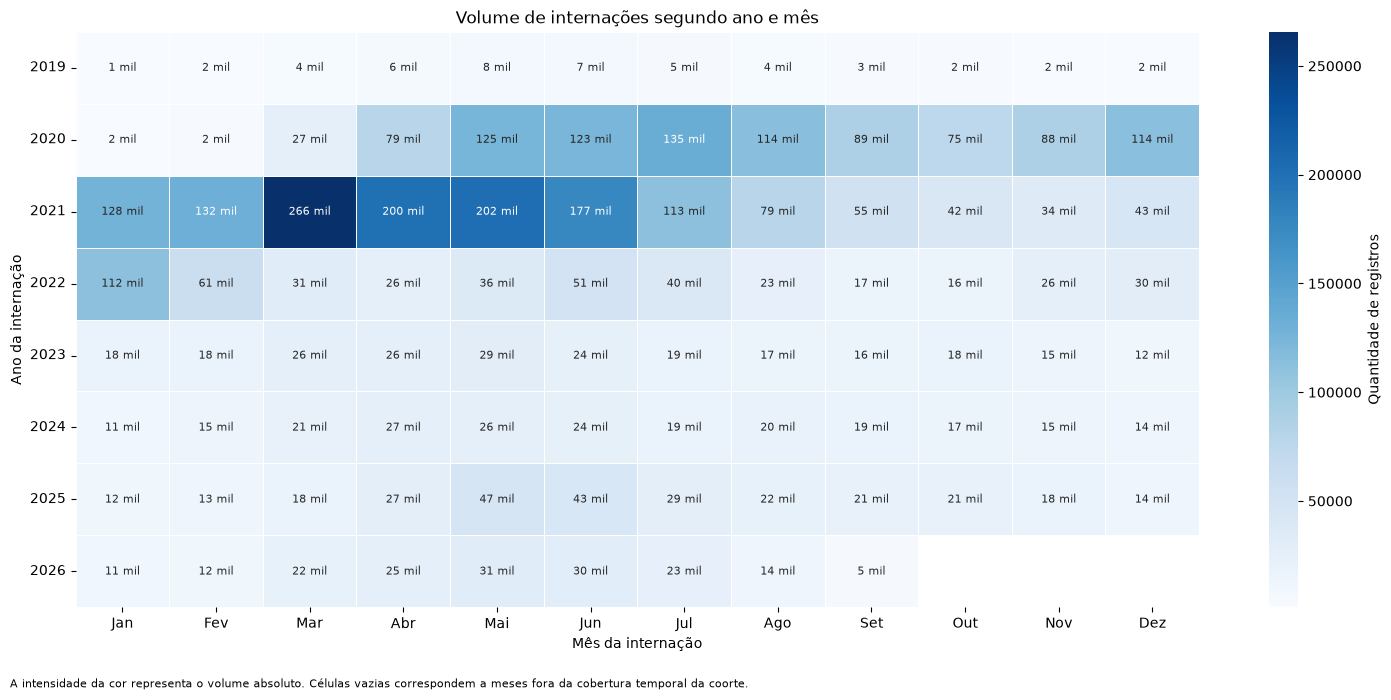

In [99]:
anotacoes_volume_ano_mes = (
    matriz_volume_ano_mes
    .copy()
    .astype("object")
)

for ano in matriz_volume_ano_mes.index:
    for mes in matriz_volume_ano_mes.columns:
        quantidade = matriz_volume_ano_mes.loc[ano, mes]

        if np.asarray(pd.isna(quantidade)).any():
            anotacao = ""
        else:
            quantidade_inteira = int(
                np.asarray(quantidade).item()
            )

            if quantidade_inteira >= 1_000_000:
                anotacao = f"{quantidade_inteira / 1_000_000:.1f} mi"
            elif quantidade_inteira >= 1_000:
                anotacao = f"{quantidade_inteira / 1_000:.0f} mil"
            else:
                anotacao = str(quantidade_inteira)

        anotacoes_volume_ano_mes.loc[ano, mes] = anotacao


figura_heatmap_volume, eixo_heatmap_volume = plt.subplots(
    figsize=(15, 7)
)

sns.heatmap(
    matriz_volume_ano_mes,
    annot=anotacoes_volume_ano_mes,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Quantidade de registros"},
    annot_kws={"fontsize": 8},
    ax=eixo_heatmap_volume,
)

eixo_heatmap_volume.set_title(
    "Volume de internações segundo ano e mês"
)
eixo_heatmap_volume.set_xlabel("Mês da internação")
eixo_heatmap_volume.set_ylabel("Ano da internação")
eixo_heatmap_volume.set_xticklabels(
    eixo_heatmap_volume.get_xticklabels(),
    rotation=0,
)
eixo_heatmap_volume.set_yticklabels(
    eixo_heatmap_volume.get_yticklabels(),
    rotation=0,
)

figura_heatmap_volume.text(
    0.01,
    0.01,
    (
        "A intensidade da cor representa o volume absoluto. "
        "Células vazias correspondem a meses fora da cobertura "
        "temporal da coorte."
    ),
    fontsize=8,
)

figura_heatmap_volume.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()
plt.close(figura_heatmap_volume)

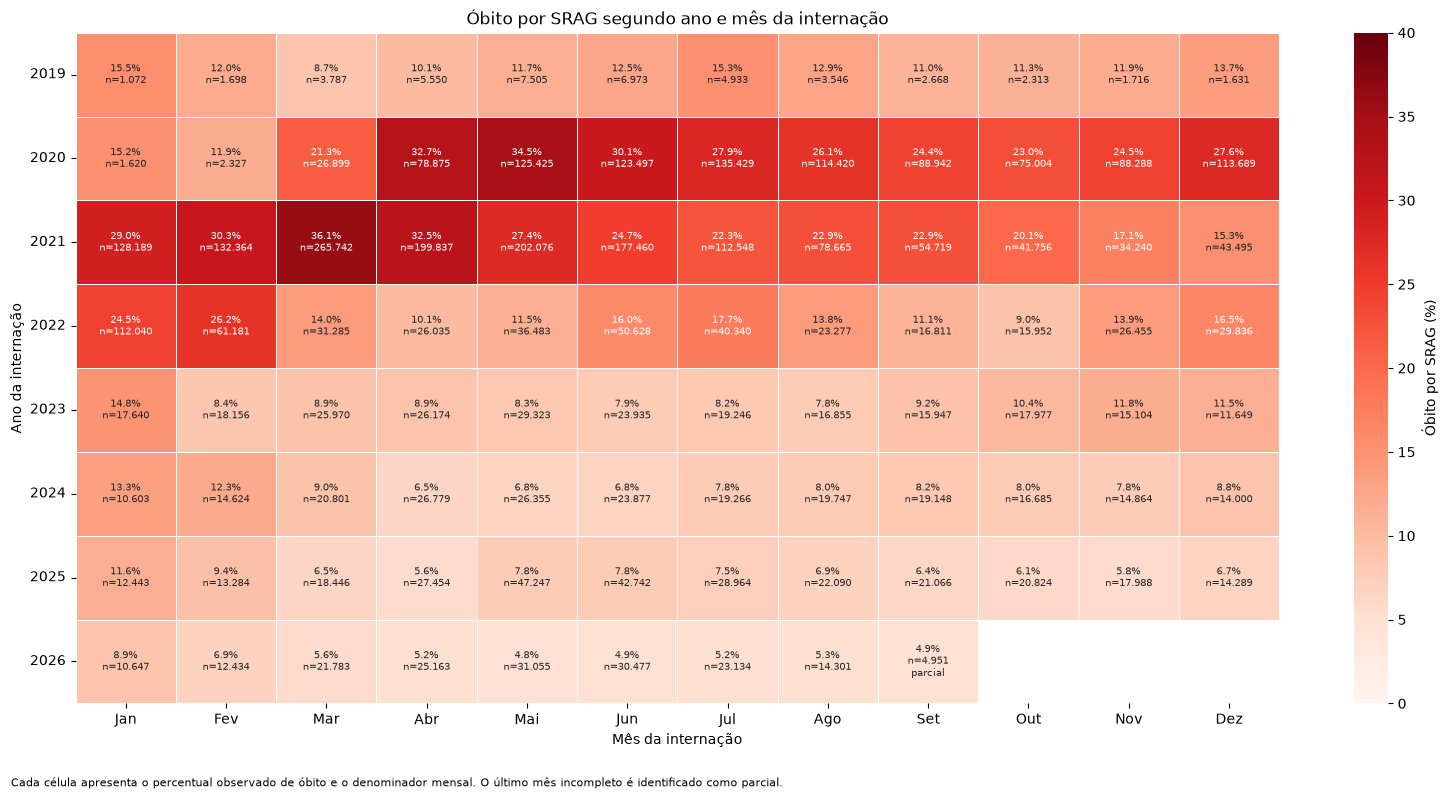

In [100]:
valor_maximo_obito_mensal = float(
    valores_obito_mensais.max()
)

limite_superior_escala_obito = max(
    10.0,
    float(
        np.ceil(
            valor_maximo_obito_mensal
            / 5
        )
        * 5
    ),
)

anotacoes_obito_ano_mes = (
    matriz_obito_ano_mes
    .copy()
    .astype("object")
)

for ano in matriz_obito_ano_mes.index:
    for mes in matriz_obito_ano_mes.columns:
        percentual = (
            matriz_obito_ano_mes.loc[
                ano,
                mes,
            ]
        )

        denominador = (
            matriz_denominador_ano_mes.loc[
                ano,
                mes,
            ]
        )

        mes_completo = (
            matriz_mes_completo_ano_mes.loc[
                ano,
                mes,
            ]
        )

        if pd.isna(
            percentual
        ):
            anotacao = ""
        else:
            percentual_formatado = (
                f"{float(percentual):.1f}%"
            )

            if pd.isna(
                denominador
            ):
                anotacao = percentual_formatado
            else:
                denominador_formatado = (
                    f"{int(denominador):,}"
                    .replace(
                        ",",
                        ".",
                    )
                )

                anotacao = (
                    f"{percentual_formatado}\n"
                    f"n={denominador_formatado}"
                )

                if (
                    not pd.isna(
                        mes_completo
                    )
                    and not bool(
                        mes_completo
                    )
                ):
                    anotacao = (
                        f"{anotacao}\n"
                        "parcial"
                    )

        anotacoes_obito_ano_mes.loc[
            ano,
            mes,
        ] = anotacao

figura_heatmap_obito, eixo_heatmap_obito = plt.subplots(
    figsize=(
        16,
        8,
    )
)

sns.heatmap(
    matriz_obito_ano_mes,
    annot=anotacoes_obito_ano_mes,
    fmt="",
    cmap="Reds",
    vmin=0,
    vmax=limite_superior_escala_obito,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Óbito por SRAG (%)",
    },
    annot_kws={
        "fontsize": 7,
    },
    ax=eixo_heatmap_obito,
)

eixo_heatmap_obito.set_title(
    "Óbito por SRAG segundo ano e mês da internação"
)

eixo_heatmap_obito.set_xlabel(
    "Mês da internação"
)

eixo_heatmap_obito.set_ylabel(
    "Ano da internação"
)

eixo_heatmap_obito.set_xticklabels(
    eixo_heatmap_obito.get_xticklabels(),
    rotation=0,
)

eixo_heatmap_obito.set_yticklabels(
    eixo_heatmap_obito.get_yticklabels(),
    rotation=0,
)

figura_heatmap_obito.text(
    0.01,
    0.01,
    (
        "Cada célula apresenta o percentual observado de óbito "
        "e o denominador mensal. O último mês incompleto é "
        "identificado como parcial."
    ),
    fontsize=8,
)

figura_heatmap_obito.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_heatmap_obito
)

In [101]:
memoria_antes_liberacao_gb = memoria_processo_gb()
if "coorte" in globals():
    del coorte
gc.collect()
try:
    import pyarrow as pa
    pa.default_memory_pool().release_unused()
except Exception:
    pass
print(
    "Memória do kernel antes e depois de liberar a coorte:",
    f"{memoria_antes_liberacao_gb:.2f} GB ->",
    f"{memoria_processo_gb():.2f} GB",
)

from itertools import combinations

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.stats import chi2_contingency, f_oneway, kruskal
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import KNeighborsClassifier

from src.dados import load_supervised_artifact
from src.features import construir_preprocessador_clustering

NS_SEMENTE = 42
NS_TAMANHO_AMOSTRA = 80_000
NS_TAMANHO_SUBAMOSTRA = 10_000
NS_COMPONENTES_SVD = 40
NS_VARIANCIA_ALVO = 0.90
NS_K_KMEANS = range(2, 11)
NS_K_HCA = range(2, 11)
NS_K_MINIMO_DESCRICAO = 3
NS_LIMITE_CLUSTER_PEQUENO = 1.0
NS_CANDIDATOS_POR_METODO = 3
NS_REPETICOES_ESTABILIDADE = 5
NS_N_INIT = 10
NS_MAX_ITER = 200
NS_TAMANHO_LOTE = 2_048
NS_N_INIT_FINAL = 30
NS_MAX_ITER_FINAL = 300

NS_PASTA_FINAL = C.OUTPUTS_DIR / "final"
for ns_pasta in (C.TABLES_DIR, C.FIGURES_DIR, NS_PASTA_FINAL):
    ns_pasta.mkdir(parents=True, exist_ok=True)


def ns_renumerar_por_tamanho(rotulos):
    """Numera os grupos de 0 em diante, do maior para o menor, para o número ter sempre o mesmo sentido."""
    tamanhos = pd.Series(rotulos).value_counts().sort_index()
    ordem = tamanhos.sort_values(ascending=False, kind="stable").index
    mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
    return pd.Series(rotulos).map(mapa).to_numpy(dtype=int)


def ns_candidatos_kmeans(diagnostico):
    """Candidatos a k: maior silhueta, cotovelo e os melhores por silhueta, entre os sem grupo muito pequeno."""
    elegiveis = diagnostico.loc[diagnostico["menor_cluster_pct"] >= NS_LIMITE_CLUSTER_PEQUENO]
    if elegiveis.empty:
        elegiveis = diagnostico.copy()
    por_silhueta = elegiveis.sort_values(["silhueta", "k"], ascending=[False, True])
    k_silhueta = int(por_silhueta["k"].iloc[0])
    ordenado = elegiveis.sort_values("k").reset_index(drop=True)
    anterior = ordenado["inercia_por_registro"].shift(1)
    ordenado["reducao_inercia_pct"] = 100 * (anterior - ordenado["inercia_por_registro"]) / anterior
    reducoes = ordenado.dropna(subset=["reducao_inercia_pct"])
    if reducoes.empty:
        k_cotovelo = k_silhueta
    else:
        k_cotovelo = int(reducoes.sort_values(["reducao_inercia_pct", "k"], ascending=[False, True])["k"].iloc[0])
    melhores = por_silhueta["k"].head(NS_CANDIDATOS_POR_METODO).astype(int).tolist()
    return sorted(dict.fromkeys([k_silhueta, k_cotovelo] + melhores))


def ns_maior_salto(tabela, k_minimo):
    """k de maior salto de distância entre fusões, entre os cortes sem grupo muito pequeno."""
    elegiveis = tabela.loc[(tabela["k"] >= k_minimo) & (tabela["menor_cluster_pct"] >= NS_LIMITE_CLUSTER_PEQUENO)]
    if elegiveis.empty:
        elegiveis = tabela.loc[tabela["k"] >= k_minimo]
    return int(elegiveis.sort_values(["salto_distancia", "k"], ascending=[False, True])["k"].iloc[0])


def ns_perfil_grupos(base, rotulos, numericas, categoricas):
    """Uma linha por variável: teste de associação com o grupo, tamanho do efeito e amplitude entre grupos."""
    grupos = np.asarray(rotulos)
    linhas = []
    for coluna in categoricas:
        texto = base[coluna].astype("string").str.strip()
        ausente = (texto.isna() | texto.eq("")).to_numpy(dtype=bool)
        sim = texto.isin(["1", "1.0"]).to_numpy(dtype=bool)
        valores = np.where(ausente, "AUSENTE", texto.fillna("").to_numpy(dtype=object))
        tabela = pd.crosstab(valores, grupos)
        qui2, p_qui2 = chi2_contingency(tabela, correction=False)[:2]
        menor = min(tabela.shape) - 1
        efeito = float(np.sqrt(qui2 / (tabela.to_numpy().sum() * menor))) if menor > 0 else float("nan")
        pct_ausente = pd.Series(ausente).groupby(grupos).mean() * 100
        pct_sim = pd.Series(sim).groupby(grupos).mean() * 100
        linhas.append({
            "variavel": coluna, "tipo": "categorica", "medida": "V_de_Cramer", "efeito": efeito,
            "teste": "qui_quadrado", "estatistica": float(qui2), "p_valor": float(p_qui2),
            "eta2_por_postos": np.nan, "p_kruskal": np.nan,
            "pct_ausente_amostra": float(ausente.mean() * 100),
            "amplitude_pct_ausente": float(pct_ausente.max() - pct_ausente.min()),
            "amplitude_pct_sim": float(pct_sim.max() - pct_sim.min()),
            "media_minima": np.nan, "media_maxima": np.nan,
        })
    for coluna in numericas:
        serie = pd.to_numeric(base[coluna], errors="coerce").reset_index(drop=True)
        por_grupo = [dados.dropna().to_numpy(dtype=float) for _, dados in serie.groupby(grupos)]
        por_grupo = [dados for dados in por_grupo if dados.size]
        n, k = sum(dados.size for dados in por_grupo), len(por_grupo)
        estatistica_f = p_anova = eta2 = estatistica_h = p_kruskal = float("nan")
        if k >= 2 and n > k:
            todos = np.concatenate(por_grupo)
            media_geral = todos.mean()
            soma_total = float(((todos - media_geral) ** 2).sum())
            soma_entre = float(sum(d.size * (d.mean() - media_geral) ** 2 for d in por_grupo))
            if soma_total > 0:
                estatistica_f, p_anova = (float(v) for v in f_oneway(*por_grupo))
                eta2 = soma_entre / soma_total
                estatistica_h, p_kruskal = (float(v) for v in kruskal(*por_grupo))
        eta2_postos = max(0.0, (estatistica_h - k + 1) / (n - k)) if not np.isnan(estatistica_h) else float("nan")
        medias = serie.groupby(grupos).mean()
        linhas.append({
            "variavel": coluna, "tipo": "numerica", "medida": "eta2_ANOVA", "efeito": eta2,
            "teste": "ANOVA_um_fator", "estatistica": estatistica_f, "p_valor": p_anova,
            "eta2_por_postos": eta2_postos, "p_kruskal": p_kruskal,
            "pct_ausente_amostra": float(serie.isna().mean() * 100),
            "amplitude_pct_ausente": np.nan, "amplitude_pct_sim": np.nan,
            "media_minima": float(medias.min()), "media_maxima": float(medias.max()),
        })
    return pd.DataFrame(linhas).sort_values("efeito", ascending=False, ignore_index=True)

Memória do kernel antes e depois de liberar a coorte: 1.82 GB -> 1.00 GB


In [102]:
ns_inicio = time.perf_counter()

with open(ROOT_DIR / "data" / "analytical" / "manifesto_supervisionado.json", encoding="utf-8") as ns_arquivo:
    ns_manifesto = json.load(ns_arquivo)

NS_NUMERICAS = list(ns_manifesto["numeric_columns"])
NS_CATEGORICAS = list(ns_manifesto["categorical_columns"])

ns_treino, _ = load_supervised_artifact(
    ROOT_DIR,
    expected_kind="final",
    partitions=("train_ref",),
    columns=["id_registro", "ano_internacao", *NS_NUMERICAS, *NS_CATEGORICAS],
)

if len(ns_treino) < NS_TAMANHO_AMOSTRA:
    raise ValueError(
        f"O bloco train_ref tem {len(ns_treino)} fichas, menos que a amostra pedida ({NS_TAMANHO_AMOSTRA})."
    )

ns_amostra = ns_treino.sample(n=NS_TAMANHO_AMOSTRA, random_state=NS_SEMENTE).reset_index(drop=True)
print("Fichas em train_ref:", len(ns_treino), "| fichas na amostra:", len(ns_amostra))

with open(ROOT_DIR / "data" / "analytical" / "manifesto_particao.json", encoding="utf-8") as ns_arquivo_particao:
    NS_ANOS_TREINO = {int(ano) for ano in json.load(ns_arquivo_particao)["blocos"]["train_ref"]["anos"]}
ns_anos_amostra = {int(ano) for ano in ns_amostra["ano_internacao"].dropna().unique()}
if ns_anos_amostra - NS_ANOS_TREINO or ns_amostra["ano_internacao"].isna().any():
    raise ValueError(
        f"A amostra tem fichas fora dos anos do train_ref: {sorted(ns_anos_amostra - NS_ANOS_TREINO)}."
    )
print("Anos das fichas da amostra:", sorted(ns_anos_amostra), "| anos do bloco train_ref:", sorted(NS_ANOS_TREINO))
del ns_treino
gc.collect()

ns_preprocessador = construir_preprocessador_clustering(NS_NUMERICAS, NS_CATEGORICAS)
ns_matriz = ns_preprocessador.fit_transform(ns_amostra[NS_NUMERICAS + NS_CATEGORICAS])
ns_colunas_onehot = ns_matriz.shape[1]
print("Colunas depois do one-hot:", ns_colunas_onehot, "| valores não nulos:", ns_matriz.nnz)
print("Peso aplicado às numéricas:", round(ns_preprocessador.peso_numericas_, 3), "| variância média de uma categórica:", round(ns_preprocessador.variancia_media_categorica_, 3))

ns_svd = TruncatedSVD(n_components=NS_COMPONENTES_SVD, random_state=NS_SEMENTE)
ns_projecao = ns_svd.fit_transform(ns_matriz)
ns_variancia_acumulada = np.cumsum(ns_svd.explained_variance_ratio_)
ns_alcancou = np.flatnonzero(ns_variancia_acumulada >= NS_VARIANCIA_ALVO)
ns_n_componentes = int(ns_alcancou[0]) + 1 if ns_alcancou.size else NS_COMPONENTES_SVD
ns_projecao = ns_projecao[:, :ns_n_componentes]
del ns_matriz
gc.collect()

ns_gerador = np.random.default_rng(NS_SEMENTE)
ns_indices_sub = np.sort(ns_gerador.choice(len(ns_projecao), size=NS_TAMANHO_SUBAMOSTRA, replace=False))

print(
    "Componentes usados:", ns_n_componentes,
    "| variância acumulada:", round(float(ns_variancia_acumulada[ns_n_componentes - 1]), 3),
    "| variância acumulada com 40:", round(float(ns_variancia_acumulada[-1]), 3),
)
print("Tempo da preparação:", f"{time.perf_counter() - ns_inicio:.1f} s", "| memória:", f"{memoria_processo_gb():.2f} GB")

Fichas em train_ref: 556462 | fichas na amostra: 80000
Anos das fichas da amostra: [2019, 2023, 2024, 2025] | anos do bloco train_ref: [2019, 2023, 2024, 2025]
Colunas depois do one-hot: 122 | valores não nulos: 2400000
Peso aplicado às numéricas: 0.336 | variância média de uma categórica: 0.113
Componentes usados: 26 | variância acumulada: 0.904 | variância acumulada com 40: 0.965
Tempo da preparação: 3.3 s | memória: 1.38 GB


,metodo,k,silhueta,inercia_por_registro,menor_cluster_pct,ari_sementes_medio,ari_sementes_minimo,pontuacao_diagnostica,candidato,salto_distancia,escolhido
0,kmeans,2,0.3951,1.8153,30.3275,1.0000,0.9999,3.0,True,NaN,True
1,kmeans,3,0.2956,1.4879,22.7987,0.9996,0.9994,6.0,True,NaN,False
2,kmeans,4,0.2224,1.4253,16.2675,0.6893,0.6173,9.0,True,NaN,False
3,kmeans,5,0.1398,1.3642,14.7725,NaN,NaN,NaN,False,NaN,False
4,kmeans,6,0.1105,1.3308,10.9825,NaN,NaN,NaN,False,NaN,False
5,kmeans,7,0.1053,1.2928,10.9425,NaN,NaN,NaN,False,NaN,False
6,kmeans,8,0.1048,1.2746,5.7412,NaN,NaN,NaN,False,NaN,False
7,kmeans,9,0.1037,1.2284,7.4375,NaN,NaN,NaN,False,NaN,False
8,kmeans,10,0.1057,1.2165,4.9238,NaN,NaN,NaN,False,NaN,False


Candidatos a k: [2, 3, 4]
k escolhido no K-Means: 2
Tamanho dos grupos: {0: 55738, 1: 24262}


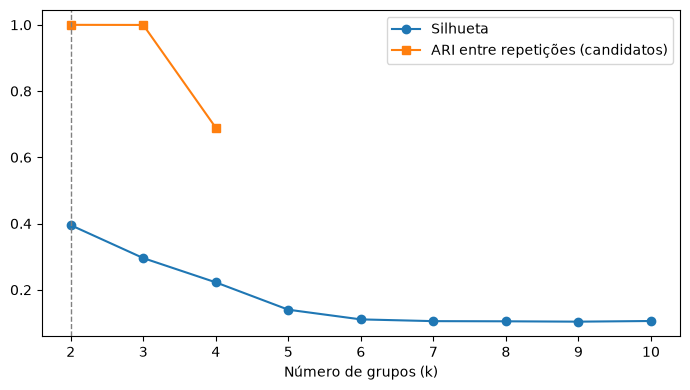

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_ns_onehot_kmeans.png
Tempo do K-Means: 16.3 s | memória: 1.39 GB


In [103]:
ns_inicio = time.perf_counter()
ns_rotulos_por_k = {}
ns_linhas_diagnostico = []

for ns_k in NS_K_KMEANS:
    ns_modelo = MiniBatchKMeans(
        n_clusters=ns_k, n_init=NS_N_INIT, max_iter=NS_MAX_ITER, batch_size=NS_TAMANHO_LOTE,
        random_state=NS_SEMENTE + ns_k,
    )
    ns_rotulos = ns_modelo.fit_predict(ns_projecao)
    ns_rotulos_por_k[ns_k] = ns_rotulos
    ns_tamanhos = pd.Series(ns_rotulos).value_counts()
    ns_linhas_diagnostico.append({
        "metodo": "kmeans",
        "k": ns_k,
        "silhueta": float(silhouette_score(ns_projecao[ns_indices_sub], ns_rotulos[ns_indices_sub])),
        "inercia_por_registro": float(ns_modelo.inertia_ / len(ns_projecao)),
        "menor_cluster_pct": float(100 * ns_tamanhos.min() / len(ns_rotulos)),
    })

ns_diagnostico = pd.DataFrame(ns_linhas_diagnostico)
ns_candidatos = ns_candidatos_kmeans(ns_diagnostico)

ns_linhas_estabilidade = []
for ns_k in ns_candidatos:
    ns_repeticoes = []
    ns_pequeno = False
    for ns_repeticao in range(NS_REPETICOES_ESTABILIDADE):
        ns_modelo = MiniBatchKMeans(
            n_clusters=ns_k, n_init=NS_N_INIT, max_iter=NS_MAX_ITER, batch_size=NS_TAMANHO_LOTE,
            random_state=NS_SEMENTE + ns_k * 100 + ns_repeticao,
        )
        ns_rotulos = ns_modelo.fit_predict(ns_projecao)
        ns_repeticoes.append(ns_rotulos)
        ns_pequeno = ns_pequeno or (100 * pd.Series(ns_rotulos).value_counts().min() / len(ns_rotulos) < NS_LIMITE_CLUSTER_PEQUENO)
    ns_aris = [adjusted_rand_score(a, b) for a, b in combinations(ns_repeticoes, 2)]
    ns_linhas_estabilidade.append({
        "k": ns_k,
        "ari_sementes_medio": float(np.mean(ns_aris)),
        "ari_sementes_minimo": float(np.min(ns_aris)),
        "alguma_repeticao_cluster_pequeno": bool(ns_pequeno),
    })
    del ns_repeticoes
    gc.collect()

ns_estabilidade = pd.DataFrame(ns_linhas_estabilidade).merge(
    ns_diagnostico[["k", "silhueta", "menor_cluster_pct"]], on="k", validate="one_to_one"
)
ns_estabilidade["elegivel"] = ~ns_estabilidade["alguma_repeticao_cluster_pequeno"]
ns_estabilidade["posicao_silhueta"] = ns_estabilidade["silhueta"].rank(method="min", ascending=False)
ns_estabilidade["posicao_estabilidade"] = ns_estabilidade["ari_sementes_medio"].rank(method="min", ascending=False)
ns_estabilidade["posicao_tamanho_minimo"] = ns_estabilidade["menor_cluster_pct"].rank(method="min", ascending=False)
ns_estabilidade["pontuacao_diagnostica"] = (
    ns_estabilidade["posicao_silhueta"] + ns_estabilidade["posicao_estabilidade"] + ns_estabilidade["posicao_tamanho_minimo"]
)
ns_estabilidade = ns_estabilidade.sort_values(
    ["elegivel", "pontuacao_diagnostica", "k"], ascending=[False, True, True], ignore_index=True
)
NS_K_ESCOLHIDO_KMEANS = int(ns_estabilidade["k"].iloc[0])

ns_modelo_final = MiniBatchKMeans(
    n_clusters=NS_K_ESCOLHIDO_KMEANS, n_init=NS_N_INIT_FINAL, max_iter=NS_MAX_ITER_FINAL,
    batch_size=NS_TAMANHO_LOTE, random_state=NS_SEMENTE,
)
ns_rotulos_kmeans = ns_renumerar_por_tamanho(ns_modelo_final.fit_predict(ns_projecao))

ns_tabela_kmeans = ns_diagnostico.merge(
    ns_estabilidade[["k", "ari_sementes_medio", "ari_sementes_minimo", "pontuacao_diagnostica"]], on="k", how="left"
)
ns_tabela_kmeans["candidato"] = ns_tabela_kmeans["k"].isin(ns_candidatos)
ns_tabela_kmeans["salto_distancia"] = np.nan
ns_tabela_kmeans["escolhido"] = ns_tabela_kmeans["k"].eq(NS_K_ESCOLHIDO_KMEANS)

display(ns_tabela_kmeans.round(4))
print("Candidatos a k:", ns_candidatos)
print("k escolhido no K-Means:", NS_K_ESCOLHIDO_KMEANS)
print("Tamanho dos grupos:", pd.Series(ns_rotulos_kmeans).value_counts().sort_index().to_dict())

ns_figura, ns_eixo = plt.subplots(figsize=(7, 4))
ns_eixo.plot(ns_tabela_kmeans["k"], ns_tabela_kmeans["silhueta"], marker="o", label="Silhueta")
ns_candidatas = ns_tabela_kmeans.loc[ns_tabela_kmeans["candidato"]]
ns_eixo.plot(ns_candidatas["k"], ns_candidatas["ari_sementes_medio"], marker="s", label="ARI entre repetições (candidatos)")
ns_eixo.axvline(NS_K_ESCOLHIDO_KMEANS, color="gray", linestyle="--", linewidth=1)
ns_eixo.set_xlabel("Número de grupos (k)")
ns_eixo.set_xticks(list(NS_K_KMEANS))
ns_eixo.legend()
ns_figura.tight_layout()
NS_FIGURA_KMEANS = C.FIGURES_DIR / "04_eda_ns_onehot_kmeans.png"
ns_figura.savefig(NS_FIGURA_KMEANS, dpi=150, bbox_inches="tight")
plt.show()
plt.close(ns_figura)
print("Figura salva em:", NS_FIGURA_KMEANS)
print("Tempo do K-Means:", f"{time.perf_counter() - ns_inicio:.1f} s", "| memória:", f"{memoria_processo_gb():.2f} GB")

,metodo,k,silhueta,salto_distancia,menor_cluster_pct,ari_com_kmeans_mesmo_k,escolhido,nivel_de_descricao,ari_sementes_medio,ari_sementes_minimo
0,hca,2,0.3948,77.6977,30.36,0.9984,True,False,NaN,NaN
1,hca,3,0.2934,42.1360,22.01,0.9788,False,True,NaN,NaN
2,hca,4,0.2195,12.3719,21.13,0.6994,False,False,NaN,NaN
3,hca,5,0.1269,0.6215,7.62,0.5440,False,False,NaN,NaN
4,hca,6,0.0959,0.4121,7.62,0.4772,False,False,NaN,NaN
5,hca,7,0.0991,1.1320,1.75,0.5446,False,False,NaN,NaN
6,hca,8,0.0960,0.7648,1.75,0.5579,False,False,NaN,NaN
7,hca,9,0.1002,1.0214,1.75,0.5294,False,False,NaN,NaN
8,hca,10,0.0898,1.0166,1.75,0.5780,False,False,NaN,NaN


k do corte principal do hierárquico (maior salto): 2
k do nível de descrição (maior salto entre os cortes com pelo menos 3 grupos): 3
Concordância com o K-Means no k escolhido do K-Means: 0.9984
Tamanho dos grupos do corte principal (80 mil): {0: 55732, 1: 24268}
Tamanho dos grupos do nível de descrição (80 mil): {0: 37771, 1: 24268, 2: 17961}


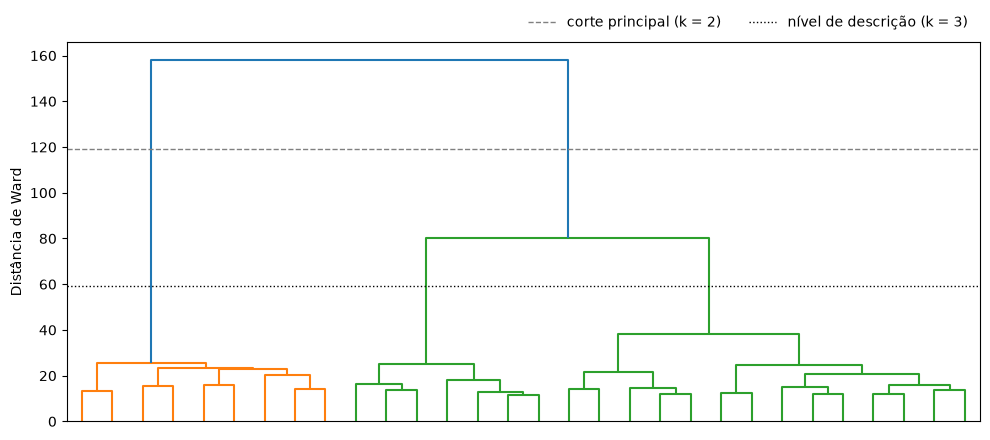

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\04_eda_ns_onehot_dendrograma.png
Tempo do agrupamento hierárquico: 17.6 s | memória: 1.39 GB


In [104]:
ns_inicio = time.perf_counter()

ns_n_sub = len(ns_indices_sub)
ns_ligacao = linkage(ns_projecao[ns_indices_sub], method="ward")

ns_linhas_hca = []
for ns_k in NS_K_HCA:
    ns_corte = fcluster(ns_ligacao, ns_k, criterion="maxclust")
    ns_linhas_hca.append({
        "metodo": "hca",
        "k": ns_k,
        "silhueta": float(silhouette_score(ns_projecao[ns_indices_sub], ns_corte)),
        "salto_distancia": float(ns_ligacao[ns_n_sub - ns_k, 2] - ns_ligacao[ns_n_sub - ns_k - 1, 2]),
        "menor_cluster_pct": float(100 * pd.Series(ns_corte).value_counts().min() / ns_n_sub),
        "ari_com_kmeans_mesmo_k": float(adjusted_rand_score(ns_rotulos_por_k[ns_k][ns_indices_sub], ns_corte)),
    })
ns_tabela_hca = pd.DataFrame(ns_linhas_hca)

NS_K_HCA_PRINCIPAL = ns_maior_salto(ns_tabela_hca, min(NS_K_HCA))
NS_K_ESCOLHIDO_HCA = NS_K_HCA_PRINCIPAL if NS_K_HCA_PRINCIPAL >= NS_K_MINIMO_DESCRICAO else ns_maior_salto(ns_tabela_hca, NS_K_MINIMO_DESCRICAO)
ns_tabela_hca["escolhido"] = ns_tabela_hca["k"].eq(NS_K_HCA_PRINCIPAL)
ns_tabela_hca["nivel_de_descricao"] = ns_tabela_hca["k"].eq(NS_K_ESCOLHIDO_HCA)
for ns_coluna in ("ari_sementes_medio", "ari_sementes_minimo"):
    ns_tabela_hca[ns_coluna] = np.nan


def ns_rotulos_do_corte(k):
    """Rótulos dos 80 mil registros: os 10 mil do hierárquico e, para os demais, o grupo dos 15 vizinhos mais próximos."""
    rotulos_sub = fcluster(ns_ligacao, k, criterion="maxclust")
    vizinhos = KNeighborsClassifier(n_neighbors=15).fit(ns_projecao[ns_indices_sub], rotulos_sub)
    demais = np.setdiff1d(np.arange(len(ns_projecao)), ns_indices_sub)
    rotulos = np.empty(len(ns_projecao), dtype=int)
    rotulos[ns_indices_sub] = rotulos_sub
    rotulos[demais] = vizinhos.predict(ns_projecao[demais])
    return ns_renumerar_por_tamanho(rotulos)


ns_rotulos_hca_principal = ns_rotulos_do_corte(NS_K_HCA_PRINCIPAL)
ns_rotulos_hca = ns_rotulos_hca_principal if NS_K_ESCOLHIDO_HCA == NS_K_HCA_PRINCIPAL else ns_rotulos_do_corte(NS_K_ESCOLHIDO_HCA)

display(ns_tabela_hca.round(4))
print("k do corte principal do hierárquico (maior salto):", NS_K_HCA_PRINCIPAL)
print("k do nível de descrição (maior salto entre os cortes com pelo menos", NS_K_MINIMO_DESCRICAO, "grupos):", NS_K_ESCOLHIDO_HCA)
print("Concordância com o K-Means no k escolhido do K-Means:",
      round(float(ns_tabela_hca.loc[ns_tabela_hca["k"].eq(NS_K_ESCOLHIDO_KMEANS), "ari_com_kmeans_mesmo_k"].iloc[0]), 4))
print("Tamanho dos grupos do corte principal (80 mil):", pd.Series(ns_rotulos_hca_principal).value_counts().sort_index().to_dict())
print("Tamanho dos grupos do nível de descrição (80 mil):", pd.Series(ns_rotulos_hca).value_counts().sort_index().to_dict())


def ns_altura_do_corte(k):
    return (ns_ligacao[ns_n_sub - k - 1, 2] + ns_ligacao[ns_n_sub - k, 2]) / 2


ns_figura, ns_eixo = plt.subplots(figsize=(10, 4.5))
dendrogram(ns_ligacao, truncate_mode="lastp", p=30, no_labels=True, ax=ns_eixo)
ns_eixo.axhline(ns_altura_do_corte(NS_K_HCA_PRINCIPAL), color="gray", linestyle="--", linewidth=1, label=f"corte principal (k = {NS_K_HCA_PRINCIPAL})")
if NS_K_ESCOLHIDO_HCA != NS_K_HCA_PRINCIPAL:
    ns_eixo.axhline(ns_altura_do_corte(NS_K_ESCOLHIDO_HCA), color="black", linestyle=":", linewidth=1, label=f"nível de descrição (k = {NS_K_ESCOLHIDO_HCA})")
ns_eixo.set_ylabel("Distância de Ward")
ns_eixo.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
ns_figura.tight_layout()
NS_FIGURA_DENDROGRAMA = C.FIGURES_DIR / "04_eda_ns_onehot_dendrograma.png"
ns_figura.savefig(NS_FIGURA_DENDROGRAMA, dpi=150, bbox_inches="tight")
plt.show()
plt.close(ns_figura)
print("Figura salva em:", NS_FIGURA_DENDROGRAMA)
print("Tempo do agrupamento hierárquico:", f"{time.perf_counter() - ns_inicio:.1f} s", "| memória:", f"{memoria_processo_gb():.2f} GB")

In [105]:
ns_inicio = time.perf_counter()

ns_perfil_kmeans = ns_perfil_grupos(ns_amostra, ns_rotulos_kmeans, NS_NUMERICAS, NS_CATEGORICAS)
ns_perfil_hca = ns_perfil_grupos(ns_amostra, ns_rotulos_hca, NS_NUMERICAS, NS_CATEGORICAS)

print("Perfil dos grupos do K-Means: dez variáveis de maior efeito")
display(ns_perfil_kmeans.head(10).round(3))
print("Perfil dos grupos do agrupamento hierárquico (nível de descrição): dez variáveis de maior efeito")
display(ns_perfil_hca.head(10).round(3))

ns_metricas = pd.concat([ns_tabela_kmeans, ns_tabela_hca], ignore_index=True)
ns_rotulos_tabela = pd.DataFrame({
    "id_registro": ns_amostra["id_registro"].to_numpy(),
    "grupo_kmeans": ns_rotulos_kmeans,
    "grupo_hca": ns_rotulos_hca,
    "grupo_hca_principal": ns_rotulos_hca_principal,
})
ns_resumo = pd.DataFrame({
    "metrica": [
        "fichas_na_amostra", "fichas_na_subamostra", "colunas_apos_onehot", "peso_numericas", "componentes_svd",
        "variancia_acumulada_svd", "k_kmeans", "k_hca_principal", "k_hca_descricao",
    ],
    "valor": [
        len(ns_amostra), len(ns_indices_sub), ns_colunas_onehot, round(ns_preprocessador.peso_numericas_, 4), ns_n_componentes,
        round(float(ns_variancia_acumulada[ns_n_componentes - 1]), 4), NS_K_ESCOLHIDO_KMEANS, NS_K_HCA_PRINCIPAL, NS_K_ESCOLHIDO_HCA,
    ],
})

NS_ARQUIVOS_SAIDA = {
    "metricas": C.TABLES_DIR / "ns_onehot_metricas.csv",
    "resumo": C.TABLES_DIR / "ns_onehot_resumo.csv",
    "rotulos": C.TABLES_DIR / "ns_onehot_rotulos.parquet",
    "perfil_kmeans": NS_PASTA_FINAL / "perfil_clusters_kmeans.csv",
    "perfil_hca": NS_PASTA_FINAL / "perfil_clusters_hca.csv",
}
ns_metricas.to_csv(NS_ARQUIVOS_SAIDA["metricas"], index=False)
ns_resumo.to_csv(NS_ARQUIVOS_SAIDA["resumo"], index=False)
ns_rotulos_tabela.to_parquet(NS_ARQUIVOS_SAIDA["rotulos"], index=False)
ns_perfil_kmeans.to_csv(NS_ARQUIVOS_SAIDA["perfil_kmeans"], index=False)
ns_perfil_hca.to_csv(NS_ARQUIVOS_SAIDA["perfil_hca"], index=False)

for ns_nome, ns_caminho in NS_ARQUIVOS_SAIDA.items():
    print("Gravado:", ns_caminho)
print("Tempo do perfil e da gravação:", f"{time.perf_counter() - ns_inicio:.1f} s", "| memória:", f"{memoria_processo_gb():.2f} GB")

Perfil dos grupos do K-Means: dez variáveis de maior efeito


,variavel,tipo,medida,efeito,teste,estatistica,p_valor,eta2_por_postos,p_kruskal,pct_ausente_amostra,amplitude_pct_ausente,amplitude_pct_sim,media_minima,media_maxima
0,sind_down,categorica,V_de_Cramer,0.994,qui_quadrado,79028.183,0.0,NaN,NaN,69.541,99.403,1.819,NaN,NaN
1,hepatica,categorica,V_de_Cramer,0.993,qui_quadrado,78900.956,0.0,NaN,NaN,69.671,99.223,1.156,NaN,NaN
2,hematologi,categorica,V_de_Cramer,0.992,qui_quadrado,78765.072,0.0,NaN,NaN,69.498,99.205,1.870,NaN,NaN
3,puerpera,categorica,V_de_Cramer,0.987,qui_quadrado,77981.131,0.0,NaN,NaN,69.901,98.477,0.548,NaN,NaN
4,renal,categorica,V_de_Cramer,0.983,qui_quadrado,77297.157,0.0,NaN,NaN,69.321,98.313,5.121,NaN,NaN
5,imunodepre,categorica,V_de_Cramer,0.982,qui_quadrado,77199.850,0.0,NaN,NaN,68.960,98.267,4.644,NaN,NaN
6,obesidade,categorica,V_de_Cramer,0.980,qui_quadrado,76879.423,0.0,NaN,NaN,69.702,97.813,4.757,NaN,NaN
7,neurologic,categorica,V_de_Cramer,0.976,qui_quadrado,76214.790,0.0,NaN,NaN,68.570,97.927,9.545,NaN,NaN
8,pneumopati,categorica,V_de_Cramer,0.975,qui_quadrado,76047.637,0.0,NaN,NaN,68.541,97.927,11.762,NaN,NaN
9,asma,categorica,V_de_Cramer,0.961,qui_quadrado,73808.854,0.0,NaN,NaN,67.894,96.506,13.966,NaN,NaN


Perfil dos grupos do agrupamento hierárquico (nível de descrição): dez variáveis de maior efeito


,variavel,tipo,medida,efeito,teste,estatistica,p_valor,eta2_por_postos,p_kruskal,pct_ausente_amostra,amplitude_pct_ausente,amplitude_pct_sim,media_minima,media_maxima
0,sind_down,categorica,V_de_Cramer,0.703,qui_quadrado,79075.357,0.0,NaN,NaN,69.541,99.566,1.983,NaN,NaN
1,hepatica,categorica,V_de_Cramer,0.703,qui_quadrado,78975.658,0.0,NaN,NaN,69.671,99.378,1.306,NaN,NaN
2,hematologi,categorica,V_de_Cramer,0.702,qui_quadrado,78863.785,0.0,NaN,NaN,69.498,99.481,2.154,NaN,NaN
3,puerpera,categorica,V_de_Cramer,0.698,qui_quadrado,78027.881,0.0,NaN,NaN,69.901,98.540,0.594,NaN,NaN
4,imunodepre,categorica,V_de_Cramer,0.696,qui_quadrado,77556.712,0.0,NaN,NaN,68.960,99.124,5.504,NaN,NaN
5,renal,categorica,V_de_Cramer,0.696,qui_quadrado,77471.482,0.0,NaN,NaN,69.321,98.866,5.669,NaN,NaN
6,obesidade,categorica,V_de_Cramer,0.693,qui_quadrado,76948.249,0.0,NaN,NaN,69.702,98.139,5.094,NaN,NaN
7,neurologic,categorica,V_de_Cramer,0.692,qui_quadrado,76549.006,0.0,NaN,NaN,68.570,99.047,10.674,NaN,NaN
8,pneumopati,categorica,V_de_Cramer,0.691,qui_quadrado,76342.564,0.0,NaN,NaN,68.541,99.018,12.856,NaN,NaN
9,asma,categorica,V_de_Cramer,0.681,qui_quadrado,74204.108,0.0,NaN,NaN,67.894,97.930,15.371,NaN,NaN


Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\ns_onehot_metricas.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\ns_onehot_resumo.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\ns_onehot_rotulos.parquet
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\perfil_clusters_kmeans.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\perfil_clusters_hca.csv
Tempo do perfil e da gravação: 2.7 s | memória: 1.13 GB


In [106]:
ns_inicio = time.perf_counter()

NS_COMORBIDADES = [
    "puerpera", "cardiopati", "hematologi", "sind_down", "hepatica", "asma", "diabetes",
    "neurologic", "pneumopati", "imunodepre", "renal", "obesidade", "out_morbi",
]
NS_SINTOMAS_SECUNDARIOS = ["diarreia", "vomito", "garganta", "perd_olft", "perd_pala", "dor_abd", "fadiga"]
NS_LIMITE_SINTOMAS_EM_BRANCO = 6
NS_ORDEM_FAIXAS = ["<1", "1-4", "5-11", "12-17", "18-39", "40-59", "60-79", "80+", "desconhecida"]
NS_MINIMO_FICHAS_PARA_PERCENTUAL = 100
NS_ALVO = ns_manifesto["target_column"]

ns_faltantes = set(NS_COMORBIDADES + NS_SINTOMAS_SECUNDARIOS + ["idade_anos"]) - set(
    NS_NUMERICAS + NS_CATEGORICAS + list(ns_manifesto.get("audit_columns") or [])
)
if ns_faltantes:
    raise KeyError(f"Variáveis ausentes no artefato: {sorted(ns_faltantes)}")

ns_base, _ = load_supervised_artifact(
    ROOT_DIR,
    expected_kind="final",
    partitions=("train_ref",),
    columns=["id_registro", NS_ALVO, "ano_internacao", "faixa_etaria", "fator_risc", "idade_anos",
             *NS_COMORBIDADES, *NS_SINTOMAS_SECUNDARIOS],
)
ns_caract = ns_rotulos_tabela.merge(ns_base, on="id_registro", how="left", validate="one_to_one")
if len(ns_caract) != len(ns_rotulos_tabela) or ns_caract["ano_internacao"].isna().any():
    raise ValueError("Há fichas da amostra que não estão no bloco train_ref.")
del ns_base
gc.collect()

ns_caract["idade_anos"] = pd.to_numeric(ns_caract["idade_anos"], errors="coerce")
ns_caract["faixa_etaria"] = ns_caract["faixa_etaria"].astype("string")


def ns_como_texto(coluna):
    return ns_caract[coluna].astype("string").str.strip().replace("", pd.NA)


ns_respostas = {coluna: ns_como_texto(coluna) for coluna in NS_COMORBIDADES + NS_SINTOMAS_SECUNDARIOS}
ns_em_branco = pd.DataFrame({coluna: serie.isna() for coluna, serie in ns_respostas.items()})
ns_respondeu = pd.DataFrame({coluna: serie.isin(["1", "2"]) for coluna, serie in ns_respostas.items()})
ns_sim = pd.DataFrame({coluna: serie.eq("1").fillna(False).astype(bool) for coluna, serie in ns_respostas.items()})
ns_nao = pd.DataFrame({coluna: serie.eq("2").fillna(False).astype(bool) for coluna, serie in ns_respostas.items()})

ns_caract["comorbidades_todas_em_branco"] = ns_em_branco[NS_COMORBIDADES].all(axis=1)
ns_caract["sintomas_secundarios_em_branco_n"] = ns_em_branco[NS_SINTOMAS_SECUNDARIOS].sum(axis=1)
ns_caract["pct_sintomas_secundarios_em_branco"] = (
    100 * ns_caract["sintomas_secundarios_em_branco_n"] / len(NS_SINTOMAS_SECUNDARIOS)
)
ns_caract["comorbidades_com_nao"] = ns_nao[NS_COMORBIDADES].any(axis=1)
ns_caract["fator_risc"] = ns_como_texto("fator_risc").fillna("AUSENTE")

ns_caract["modo_de_registro"] = np.select(
    [
        ns_caract["sintomas_secundarios_em_branco_n"] >= NS_LIMITE_SINTOMAS_EM_BRANCO,
        ~ns_caract["comorbidades_com_nao"],
    ],
    ["sintomas_em_branco", "comorbidades_sem_nao"],
    default="sim_e_nao",
)


def ns_resumo(coluna_grupo):
    tabela = ns_caract.groupby(coluna_grupo).agg(
        fichas=("id_registro", "size"),
        pct_comorbidades_todas_em_branco=("comorbidades_todas_em_branco", "mean"),
        pct_sintomas_secundarios_em_branco=("pct_sintomas_secundarios_em_branco", "mean"),
        idade_media=("idade_anos", "mean"),
        idade_mediana=("idade_anos", "median"),
        pct_obitos=(NS_ALVO, "mean"),
    )
    tabela["pct_das_fichas"] = 100 * tabela["fichas"] / tabela["fichas"].sum()
    for coluna in ("pct_comorbidades_todas_em_branco", "pct_obitos"):
        tabela[coluna] = 100 * tabela[coluna]
    tabela.insert(0, "metodo", coluna_grupo)
    return tabela.reset_index().rename(columns={coluna_grupo: "grupo"})


ns_t_resumo = pd.concat([ns_resumo("grupo_hca"), ns_resumo("grupo_kmeans")], ignore_index=True)

ns_t_modo = ns_caract.groupby("modo_de_registro").agg(
    fichas=("id_registro", "size"),
    idade_media=("idade_anos", "mean"),
    pct_obitos=(NS_ALVO, "mean"),
)
ns_t_modo["pct_das_fichas"] = 100 * ns_t_modo["fichas"] / ns_t_modo["fichas"].sum()
ns_t_modo["pct_obitos"] = 100 * ns_t_modo["pct_obitos"]
ns_t_modo = ns_t_modo.join(
    pd.crosstab(ns_caract["modo_de_registro"], ns_caract["grupo_hca"]).add_prefix("fichas_no_grupo_hca_")
).reset_index()

ns_t_ano = pd.concat(
    [
        (pd.crosstab(ns_caract["ano_internacao"], ns_caract[metodo], normalize="index") * 100)
        .rename_axis(columns="grupo")
        .reset_index()
        .melt(id_vars="ano_internacao", value_name="pct_das_fichas_do_ano")
        .assign(metodo=metodo)
        for metodo in ("grupo_hca", "grupo_kmeans")
    ],
    ignore_index=True,
)

ns_t_fator = ns_caract.groupby("fator_risc").agg(
    fichas=("id_registro", "size"),
    pct_comorbidades_todas_em_branco=("comorbidades_todas_em_branco", "mean"),
)
ns_t_fator["pct_comorbidades_todas_em_branco"] = 100 * ns_t_fator["pct_comorbidades_todas_em_branco"]
ns_t_fator = ns_t_fator.join(
    (pd.crosstab(ns_caract["fator_risc"], ns_caract["grupo_hca"], normalize="index") * 100).add_prefix("pct_no_grupo_hca_")
).reset_index()

ns_grupos_hca = ns_caract["grupo_hca"]
ns_n_respondentes = ns_respondeu.groupby(ns_grupos_hca).sum()
ns_n_sim = ns_sim.groupby(ns_grupos_hca).sum()
ns_pct_sim = 100 * ns_n_sim / ns_n_respondentes.where(ns_n_respondentes > 0)


def ns_formato_longo(tabela, nome):
    return tabela.rename_axis(columns="variavel").reset_index().melt(id_vars="grupo_hca", value_name=nome)


ns_t_resp = ns_formato_longo(ns_n_respondentes, "respondentes").merge(
    ns_formato_longo(ns_pct_sim, "pct_sim_entre_respondentes"), on=["grupo_hca", "variavel"]
)

ns_t_idade = (
    ns_caract.groupby(["grupo_hca", "faixa_etaria"])
    .agg(fichas=("id_registro", "size"), obitos=(NS_ALVO, "sum"))
    .reset_index()
)
ns_t_idade["pct_das_fichas_do_grupo"] = (
    100 * ns_t_idade["fichas"] / ns_t_idade.groupby("grupo_hca")["fichas"].transform("sum")
)
ns_t_idade["pct_obitos"] = (100 * ns_t_idade["obitos"] / ns_t_idade["fichas"]).where(
    ns_t_idade["fichas"] >= NS_MINIMO_FICHAS_PARA_PERCENTUAL
)
ns_t_idade["_ordem"] = ns_t_idade["faixa_etaria"].map({f: i for i, f in enumerate(NS_ORDEM_FAIXAS)}).fillna(len(NS_ORDEM_FAIXAS))
ns_t_idade = ns_t_idade.sort_values(["grupo_hca", "_ordem"]).drop(columns="_ordem")

NS_ARQUIVOS_CARACTERIZACAO = {
    "caracterizacao_grupos_resumo.csv": ns_t_resumo,
    "caracterizacao_grupos_modo_de_registro.csv": ns_t_modo,
    "caracterizacao_grupos_ano.csv": ns_t_ano,
    "caracterizacao_grupos_fator_risc.csv": ns_t_fator,
    "caracterizacao_grupos_respondentes.csv": ns_t_resp,
    "caracterizacao_grupos_idade.csv": ns_t_idade,
}
for ns_nome, ns_tabela in NS_ARQUIVOS_CARACTERIZACAO.items():
    ns_tabela.to_csv(NS_PASTA_FINAL / ns_nome, index=False)

print("1) Resumo por grupo (n, preenchimento, idade e óbitos no train_ref)")
display(ns_t_resumo.round(1))
print("2) Modo de registro por regra, e fichas de cada modo em cada grupo do hierárquico")
display(ns_t_modo.round(1))
print("3) Por ano: % das fichas de cada ano em cada grupo (hierárquico)")
display(ns_t_ano.query("metodo == 'grupo_hca'").pivot(index="ano_internacao", columns="grupo", values="pct_das_fichas_do_ano").round(1))
print("4) Por fator de risco: fichas, % com as 13 comorbidades em branco e distribuição nos grupos (%)")
display(ns_t_fator.round(1))
print("5) Entre quem respondeu sim ou não: % de sim e número de respondentes, por grupo do hierárquico")
display(
    ns_t_resp.pivot(index="variavel", columns="grupo_hca", values=["pct_sim_entre_respondentes", "respondentes"])
    .reindex(NS_COMORBIDADES + NS_SINTOMAS_SECUNDARIOS)
    .round(1)
)
print("6) Faixa etária dentro de cada grupo do hierárquico: fichas, % do grupo e % de óbitos")
display(ns_t_idade.round(1))

ns_faixa_de_corte = (
    float(ns_ligacao[-NS_K_ESCOLHIDO_HCA, 2]),
    float(ns_ligacao[-(NS_K_ESCOLHIDO_HCA - 1), 2]),
)
print(
    "Qualquer corte de Ward entre as alturas",
    round(ns_faixa_de_corte[0], 1), "e", round(ns_faixa_de_corte[1], 1),
    f"gera os mesmos {NS_K_ESCOLHIDO_HCA} grupos do nível de descrição.",
)
for ns_nome in NS_ARQUIVOS_CARACTERIZACAO:
    print("Gravado:", NS_PASTA_FINAL / ns_nome)
print("Tempo da caracterização:", f"{time.perf_counter() - ns_inicio:.1f} s", "| memória:", f"{memoria_processo_gb():.2f} GB")

1) Resumo por grupo (n, preenchimento, idade e óbitos no train_ref)


,grupo,metodo,fichas,pct_comorbidades_todas_em_branco,pct_sintomas_secundarios_em_branco,idade_media,idade_mediana,pct_obitos,pct_das_fichas
0,0,grupo_hca,37771,93.4,4.8,14.500000,1.0,4.1,47.2
1,1,grupo_hca,24268,0.0,4.8,48.299999,60.0,15.6,30.3
2,2,grupo_hca,17961,60.7,93.9,29.000000,7.0,8.1,22.5
3,0,grupo_kmeans,55738,82.8,33.5,19.200001,2.0,5.4,69.7
4,1,grupo_kmeans,24262,0.0,4.7,48.299999,60.0,15.6,30.3


2) Modo de registro por regra, e fichas de cada modo em cada grupo do hierárquico


,modo_de_registro,fichas,idade_media,pct_obitos,pct_das_fichas,fichas_no_grupo_hca_0,fichas_no_grupo_hca_1,fichas_no_grupo_hca_2
0,comorbidades_sem_nao,39192,15.200000,4.3,49.0,37608,122,1462
1,sim_e_nao,24112,48.400002,15.6,30.1,87,24016,9
2,sintomas_em_branco,16696,28.799999,8.1,20.9,76,130,16490


3) Por ano: % das fichas de cada ano em cada grupo (hierárquico)


grupo,0,1,2
ano_internacao,,,
2019,59.6,38.1,2.4
2023,42.7,29.0,28.3
2024,45.9,29.3,24.8
2025,50.1,31.1,18.8


... (3 outputs left out)

pct_sim_entre_respondentes             respondentes           \
grupo_hca                           0     1     2            0        1   
variavel                                                                  
puerpera                         31.2   0.7  63.6         64.0  23773.0   
cardiopati                       99.4  37.4  99.9        645.0  24060.0   
hematologi                       93.2   2.3  98.9         44.0  23960.0   
sind_down                        92.3   2.1  94.7         52.0  24016.0   
hepatica                         81.5   1.4  98.9         27.0  23916.0   
asma                             98.3  17.0  99.6        530.0  23917.0   
diabetes                         99.0  22.5  99.7        403.0  24032.0   
neurologic                       99.1  11.4  99.7        221.0  23986.0   
pneumopati                       98.8  13.7  99.6        249.0  23975.0   
imunodepre                       96.5   6.0  99.6        141.0  23907.0   
renal                            86.6   6.0  99.2        112.0  23874.0   
obesidade                        91.8   5.5  97.5        110.0  23592.0   
out_morbi                        96.8  43.3  98.4       1168.0  22586.0   
diarreia                          9.4   8.1  96.2      37169.0  23859.0   
vomito                           14.9  10.6  98.2      37236.0  23853.0   
garganta                         12.4  11.7  89.0      35942.0  23432.0   
perd_olft                         1.2   1.7  89.5      33253.0  21898.0   
perd_pala                         1.3   1.5  89.6      33192.0  21852.0   
dor_abd                           6.5   6.6  98.7      34017.0  22109.0   
fadiga                           15.9  23.4  99.3      34227.0  22215.0   

                    
grupo_hca        2  
variavel            
puerpera      55.0  
cardiopati  2533.0  
hematologi   180.0  
sind_down    114.0  
hepatica      95.0  
asma        1044.0  
diabetes    1567.0  
neurologic   740.0  
pneumopati   725.0  
imunodepre   540.0  
renal        362.0  
obesidade    236.0  
out_morbi   2978.0  
diarreia    1170.0  
vomito      1695.0  
garganta    1695.0  
perd_olft    133.0  
perd_pala    144.0  
dor_abd      693.0  
fadiga      1872.0

6) Faixa etária dentro de cada grupo do hierárquico: fichas, % do grupo e % de óbitos


,grupo_hca,faixa_etaria,fichas,obitos,pct_das_fichas_do_grupo,pct_obitos
7,0,<1,14714,165,39.0,1.1
0,0,1-4,9899,86,26.2,0.9
4,0,5-11,4244,38,11.2,0.9
1,0,12-17,676,17,1.8,2.5
2,0,18-39,1942,122,5.1,6.3
3,0,40-59,1959,251,5.2,12.8
5,0,60-79,2613,491,6.9,18.8
6,0,80+,1723,369,4.6,21.4
8,0,desconhecida,1,1,0.0,<NA>
16,1,<1,2090,75,8.6,3.6


Qualquer corte de Ward entre as alturas 38.0 e 80.2 gera os mesmos 3 grupos do nível de descrição.
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_resumo.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_modo_de_registro.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_ano.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_fator_risc.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_respondentes.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\caracterizacao_grupos_idade.csv
Tempo da caracterização: 1.5 s | memória: 1.43 GB
